<a href="https://colab.research.google.com/github/naurahzahiyah/Naurah-Nur-ZAHIYAH/blob/main/TA_Naurah_Temporal%20Evaluation%20and%20SHAP%20Reliability%20Auditing%20for%20Non-Contractual%20E-Commerce%20Churn%20Prediction%20_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Olist Customer Churn Prediction & Sales–Marketing Dashboard

Alur: fact table order-level → customer features → preprocessing tanpa leakage → 3 model machine learning → 1 deep learning → evaluasi → EDA, RFM, dan dataset dashboard.

**Definisi churn:** pelanggan yang bertransaksi pada feature window tetapi tidak kembali pada label month diberi label `is_churn = 1`. Karena Olist memiliki repeat purchase yang sangat rendah, evaluasi tidak hanya memakai accuracy, tetapi juga balanced accuracy, ROC-AUC, PR-AUC, recall pelanggan aktif, MCC, classification report, dan confusion matrix.


## 1. Import library dan konfigurasi

Untuk uji cepat, ubah `FINAL_RUN = False`. Untuk hasil final, biarkan `True`.


In [ ]:
from pathlib import Path
import random
import shutil
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option(
    "display.max_columns",
    100
)

pd.set_option(
    "display.max_rows",
    100
)

sns.set_theme(
    style="whitegrid"
)

# Random seed agar hasil dapat direproduksi
SEED = 42

np.random.seed(SEED)
random.seed(SEED)

# Folder kerja Google Colab
BASE_DIR = Path("/content")
RAW_DIR = BASE_DIR

DATA_DIR = (
    BASE_DIR / "olist_data"
)

OUTPUT_DIR = (
    BASE_DIR / "olist_outputs"
)

FIG_DIR = (
    OUTPUT_DIR / "figures"
)

MODEL_DIR = (
    OUTPUT_DIR / "models"
)

for folder in [
    DATA_DIR,
    OUTPUT_DIR,
    FIG_DIR,
    MODEL_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

# True  = proses final
# False = uji coba lebih cepat
FINAL_RUN = True

N_ITER_ML = (
    5 if FINAL_RUN else 2
)

N_TRIALS_DL = (
    4 if FINAL_RUN else 2
)

MAX_EPOCHS = (
    25 if FINAL_RUN else 5
)

configuration_table = pd.DataFrame({
    "Setting": [
        "Mode",
        "Random seed",
        "Data folder",
        "Output folder",
        "ML Random Search",
        "DL Random Search",
        "Maximum epochs"
    ],
    "Value": [
        (
            "Final"
            if FINAL_RUN
            else "Quick Test"
        ),
        SEED,
        str(DATA_DIR),
        str(OUTPUT_DIR),
        N_ITER_ML,
        N_TRIALS_DL,
        MAX_EPOCHS
    ]
})

display(configuration_table)

# ------------------------------------------------------------
# English labels for on-screen display only.
# Values written to the output CSV files are not changed.
# ------------------------------------------------------------
DISPLAY_EN = {
    "Kandidat final": "Final candidate",
    "Pembanding": "Benchmark",
    "Secara neto mendorong prediksi Churn": "Net push toward churn",
    "Secara neto menahan prediksi Churn": "Net push toward active",
    "Tidak ada pendorong positif": "No positive driver",
    "Tidak ada faktor pelindung": "No protective factor",
    (
        "Keputusan retensi memerlukan peninjauan manusia; "
        "SHAP bukan bukti hubungan sebab-akibat."
    ): (
        "Retention decisions require human review; "
        "SHAP is not evidence of cause and effect."
    ),
}


def english_view(dataframe):
    """Return a copy of a table with Indonesian text values shown in English."""
    return dataframe.replace(DISPLAY_EN)


,Setting,Value
0,Mode,Final
1,Random seed,42
2,Data folder,/content/olist_data
3,Output folder,/content/olist_outputs
4,ML Random Search,5
5,DL Random Search,4
6,Maximum epochs,25


## 2. Upload dan validasi dataset

In [ ]:
required_files = [
    "olist_customers_dataset.csv",
    "olist_orders_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_products_dataset.csv",
    "product_category_name_translation.csv"
]

# Memeriksa file yang sudah tersedia
missing_files = [
    filename
    for filename in required_files
    if not (
        RAW_DIR / filename
    ).exists()
]

# Upload hanya jika ada file yang belum tersedia
if missing_files:

    print(
        "The following files are not yet available:"
    )

    for filename in missing_files:
        print("-", filename)

    print(
        "\nPlease upload these files."
    )

    files.upload()

# Pemeriksaan ulang setelah upload
missing_files = [
    filename
    for filename in required_files
    if not (
        RAW_DIR / filename
    ).exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following files are still missing:\n"
        + "\n".join(missing_files)
    )

file_inventory = pd.DataFrame([
    {
        "File Name": filename,
        "Status": "Available",
        "Size (MB)": round(
            (
                RAW_DIR / filename
            ).stat().st_size
            / 1_048_576,
            2
        )
    }
    for filename in required_files
])

display(file_inventory)

print(
    "All datasets were found."
)

The following files are not yet available:
- olist_customers_dataset.csv
- olist_orders_dataset.csv
- olist_order_items_dataset.csv
- olist_order_payments_dataset.csv
- olist_order_reviews_dataset.csv
- olist_products_dataset.csv
- product_category_name_translation.csv

Please upload these files.


Saving olist_customers_dataset.csv to olist_customers_dataset.csv
Saving olist_geolocation_dataset.csv to olist_geolocation_dataset.csv
Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv
Saving olist_order_payments_dataset.csv to olist_order_payments_dataset.csv
Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset.csv
Saving olist_orders_dataset.csv to olist_orders_dataset.csv
Saving olist_products_dataset.csv to olist_products_dataset.csv
Saving olist_sellers_dataset.csv to olist_sellers_dataset.csv
Saving product_category_name_translation.csv to product_category_name_translation.csv


,File Name,Status,Size (MB)
0,olist_customers_dataset.csv,Available,8.62
1,olist_orders_dataset.csv,Available,16.84
2,olist_order_items_dataset.csv,Available,14.72
3,olist_order_payments_dataset.csv,Available,5.51
4,olist_order_reviews_dataset.csv,Available,13.78
5,olist_products_dataset.csv,Available,2.27
6,product_category_name_translation.csv,Available,0.00


All datasets were found.


## 3. Load seluruh dataset

In [ ]:
customers = pd.read_csv(
    RAW_DIR
    / "olist_customers_dataset.csv"
)

orders = pd.read_csv(
    RAW_DIR
    / "olist_orders_dataset.csv"
)

items = pd.read_csv(
    RAW_DIR
    / "olist_order_items_dataset.csv"
)

payments = pd.read_csv(
    RAW_DIR
    / "olist_order_payments_dataset.csv"
)

reviews = pd.read_csv(
    RAW_DIR
    / "olist_order_reviews_dataset.csv"
)

products = pd.read_csv(
    RAW_DIR
    / "olist_products_dataset.csv"
)

category_translation = pd.read_csv(
    RAW_DIR
    / "product_category_name_translation.csv"
)

# Mengubah kolom tanggal menjadi datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

dataset_summary = pd.DataFrame([
    {
        "Dataset": "Customers",
        "Number of Rows": len(customers),
        "Number of Columns": customers.shape[1]
    },
    {
        "Dataset": "Orders",
        "Number of Rows": len(orders),
        "Number of Columns": orders.shape[1]
    },
    {
        "Dataset": "Order Items",
        "Number of Rows": len(items),
        "Number of Columns": items.shape[1]
    },
    {
        "Dataset": "Payments",
        "Number of Rows": len(payments),
        "Number of Columns": payments.shape[1]
    },
    {
        "Dataset": "Reviews",
        "Number of Rows": len(reviews),
        "Number of Columns": reviews.shape[1]
    },
    {
        "Dataset": "Products",
        "Number of Rows": len(products),
        "Number of Columns": products.shape[1]
    },
    {
        "Dataset": "Category Translation",
        "Number of Rows": len(category_translation),
        "Number of Columns": category_translation.shape[1]
    }
])

display(dataset_summary)

print("Preview of the orders dataset:")

display(
    orders.head()
)

print("Preview of the products dataset:")

display(
    products.head()
)

,Dataset,Number of Rows,Number of Columns
0,Customers,99441,5
1,Orders,99441,8
2,Order Items,112650,7
3,Payments,103886,5
4,Reviews,99224,7
5,Products,32951,9
6,Category Translation,71,2


Preview of the orders dataset:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


Preview of the products dataset:


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


## 4. Data understanding dan pemeriksaan awal

,Dataset,Number of Rows,Number of Columns,Total Missing Value,Fully Duplicated Rows
0,Customers,99441,5,0,0
1,Orders,99441,8,4908,0
2,Order Items,112650,7,0,0
3,Payments,103886,5,0,0
4,Reviews,99224,7,145903,0
5,Products,32951,9,2448,0
6,Category Translation,71,2,0,0


,order_status,total_orders,percentage
0,delivered,96478,0.970203
1,shipped,1107,0.011132
2,canceled,625,0.006285
3,unavailable,609,0.006124
4,invoiced,314,0.003158
5,processing,301,0.003027
6,created,5,0.000050
7,approved,2,0.000020


,Indicator,Value
0,Earliest transaction date,2016-09-04 21:15:19
1,Latest transaction date,2018-10-17 17:30:18
2,Number of unique orders,99441
3,Number of customer_id values,99441
4,Number of customer_unique_id values,96096


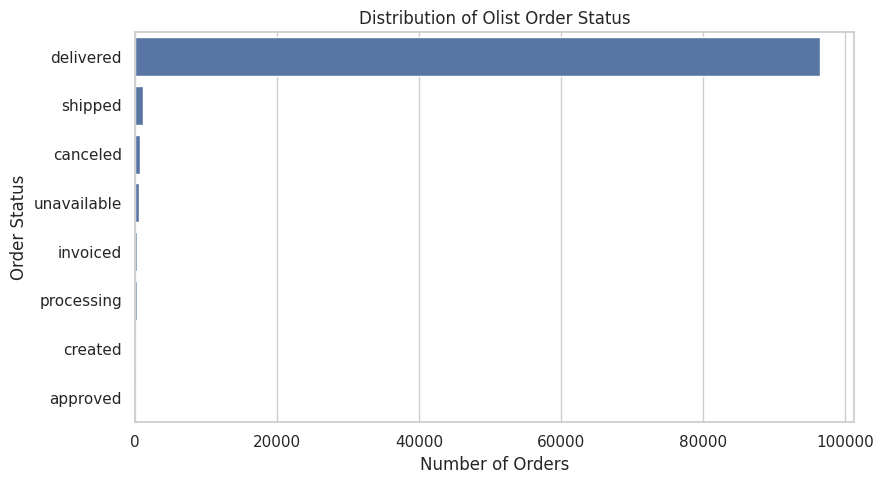

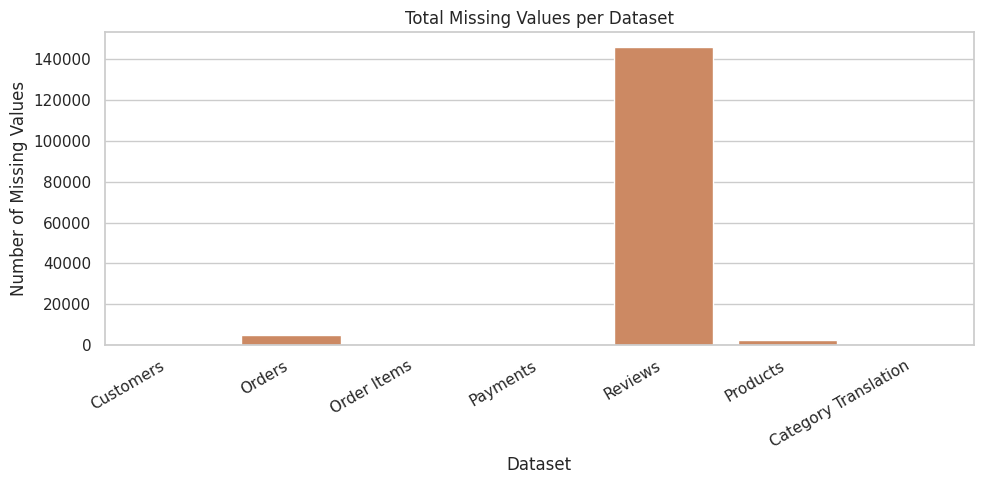

In [ ]:
datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": items,
    "Payments": payments,
    "Reviews": reviews,
    "Products": products,
    "Category Translation":
    category_translation
}

quality_rows = []

for dataset_name, dataframe in datasets.items():

    quality_rows.append({
        "Dataset": dataset_name,
        "Number of Rows": len(dataframe),
        "Number of Columns": dataframe.shape[1],
        "Total Missing Value":
        int(
            dataframe
            .isna()
            .sum()
            .sum()
        ),
        "Fully Duplicated Rows":
        int(
            dataframe
            .duplicated()
            .sum()
        )
    })

data_quality_summary = pd.DataFrame(
    quality_rows
)

display(data_quality_summary)

# Pemeriksaan order status
order_status_summary = (
    orders["order_status"]
    .value_counts()
    .rename_axis("order_status")
    .reset_index(name="total_orders")
)

order_status_summary[
    "percentage"
] = (
    order_status_summary[
        "total_orders"
    ]
    / order_status_summary[
        "total_orders"
    ].sum()
)

display(order_status_summary)

# Rentang waktu transaksi
date_summary = pd.DataFrame({
    "Indicator": [
        "Earliest transaction date",
        "Latest transaction date",
        "Number of unique orders",
        "Number of customer_id values",
        "Number of customer_unique_id values"
    ],
    "Value": [
        orders[
            "order_purchase_timestamp"
        ].min(),

        orders[
            "order_purchase_timestamp"
        ].max(),

        orders[
            "order_id"
        ].nunique(),

        customers[
            "customer_id"
        ].nunique(),

        customers[
            "customer_unique_id"
        ].nunique()
    ]
})

display(date_summary)

# Grafik order status
plt.figure(figsize=(9, 5))

sns.barplot(
    data=order_status_summary,
    y="order_status",
    x="total_orders",
    color="#4C72B0"
)

plt.title(
    "Distribution of Olist Order Status"
)

plt.xlabel("Number of Orders")
plt.ylabel("Order Status")
plt.tight_layout()
plt.show()

# Missing value setiap tabel
missing_by_dataset = pd.DataFrame({
    "Dataset": list(datasets.keys()),
    "Total Missing": [
        dataframe.isna().sum().sum()
        for dataframe in datasets.values()
    ]
})

plt.figure(figsize=(10, 5))

sns.barplot(
    data=missing_by_dataset,
    x="Dataset",
    y="Total Missing",
    color="#DD8452"
)

plt.title(
    "Total Missing Values per Dataset"
)
plt.xlabel("Dataset")
plt.ylabel("Number of Missing Values")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()

## 5. Agregasi order items

In [ ]:
products_enriched = products.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

products_enriched[
    "product_category_name_english"
] = products_enriched[
    "product_category_name_english"
].fillna("unknown")

items_enriched = items.merge(
    products_enriched[
        [
            "product_id",
            "product_category_name_english"
        ]
    ],
    on="product_id",
    how="left"
)

items_enriched[
    "product_category_name_english"
] = items_enriched[
    "product_category_name_english"
].fillna("unknown")

# Satu baris per order
item_aggregation = (
    items_enriched
    .groupby("order_id", as_index=False)
    .agg(
        total_items=("order_item_id", "count"),
        items_price=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
)

item_aggregation["order_total_value"] = (
    item_aggregation["items_price"]
    + item_aggregation["freight_value"]
)

# Kategori utama berdasarkan nilai produk terbesar
category_value = (
    items_enriched
    .groupby(
        [
            "order_id",
            "product_category_name_english"
        ],
        as_index=False
    )["price"]
    .sum()
    .sort_values(
        ["order_id", "price"],
        ascending=[True, False]
    )
    .drop_duplicates("order_id")
    .rename(
        columns={
            "product_category_name_english":
            "order_main_category"
        }
    )
    [
        [
            "order_id",
            "order_main_category"
        ]
    ]
)

item_summary = pd.DataFrame({
    "Indicator": [
        "Initial order item rows",
        "Unique orders after aggregation",
        "Average items per order",
        "Total product price",
        "Total freight",
        "Total order value"
    ],
    "Value": [
        len(items),
        item_aggregation["order_id"].nunique(),
        item_aggregation["total_items"].mean(),
        item_aggregation["items_price"].sum(),
        item_aggregation["freight_value"].sum(),
        item_aggregation["order_total_value"].sum()
    ]
})

display(item_summary)
display(item_aggregation.head(10))
display(category_value.head(10))

,Indicator,Value
0,Initial order item rows,1.126500e+05
1,Unique orders after aggregation,9.866600e+04
2,Average items per order,1.141731e+00
3,Total product price,1.359164e+07
4,Total freight,2.251910e+06
5,Total order value,1.584355e+07


,order_id,total_items,items_price,freight_value,order_total_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,72.19
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,259.83
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,216.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,218.04
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,21.90,12.69,34.59
6,00054e8431b9d7675808bcb819fb4a32,1,19.90,11.85,31.75
7,000576fe39319847cbb9d288c5617fa6,1,810.00,70.75,880.75
8,0005a1a1728c9d785b8e2b08b904576c,1,145.95,11.65,157.60
9,0005f50442cb953dcd1d21e1fb923495,1,53.99,11.40,65.39


,order_id,order_main_category
0,00010242fe8c5a6d1ba2dd792cb16214,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,pet_shop
2,000229ec398224ef6ca0657da4fc703e,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,garden_tools
5,00048cc3ae777c65dbb7d2a0634bc1ea,housewares
6,00054e8431b9d7675808bcb819fb4a32,telephony
7,000576fe39319847cbb9d288c5617fa6,garden_tools
8,0005a1a1728c9d785b8e2b08b904576c,health_beauty
9,0005f50442cb953dcd1d21e1fb923495,books_technical


## 6. Agregasi payment dan review

,order_id,payment_value_total
0,00010242fe8c5a6d1ba2dd792cb16214,72.19
1,00018f77f2f0320c557190d7a144bdd3,259.83
2,000229ec398224ef6ca0657da4fc703e,216.87
3,00024acbcdf0a6daa1e931b038114c75,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04
5,00048cc3ae777c65dbb7d2a0634bc1ea,34.59
6,00054e8431b9d7675808bcb819fb4a32,31.75
7,000576fe39319847cbb9d288c5617fa6,880.75
8,0005a1a1728c9d785b8e2b08b904576c,157.60
9,0005f50442cb953dcd1d21e1fb923495,65.39


,order_id,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,5.0
1,00018f77f2f0320c557190d7a144bdd3,4.0
2,000229ec398224ef6ca0657da4fc703e,5.0
3,00024acbcdf0a6daa1e931b038114c75,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0
5,00048cc3ae777c65dbb7d2a0634bc1ea,4.0
6,00054e8431b9d7675808bcb819fb4a32,4.0
7,000576fe39319847cbb9d288c5617fa6,5.0
8,0005a1a1728c9d785b8e2b08b904576c,1.0
9,0005f50442cb953dcd1d21e1fb923495,4.0


,payment_type,total_orders
0,credit_card,74935
1,boleto,19784
2,voucher,3191
3,debit_card,1527
4,not_defined,3


,review_score,total_orders
0,1.0,11316
1,2.0,3167
2,3.0,8137
3,4.0,19098
4,5.0,56955


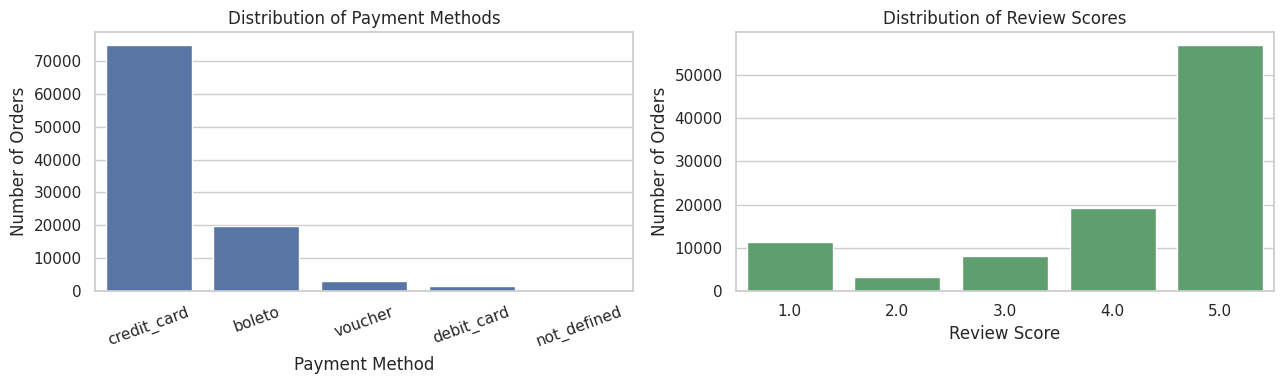

In [ ]:
# Total pembayaran per order
payment_total = (
    payments
    .groupby("order_id", as_index=False)
    ["payment_value"]
    .sum()
    .rename(
        columns={
            "payment_value":
            "payment_value_total"
        }
    )
)

# Metode pembayaran dominan
payment_main = (
    payments
    .groupby(
        [
            "order_id",
            "payment_type"
        ],
        as_index=False
    )["payment_value"]
    .sum()
    .sort_values(
        ["order_id", "payment_value"],
        ascending=[True, False]
    )
    .drop_duplicates("order_id")
    [
        [
            "order_id",
            "payment_type"
        ]
    ]
)

# Rata-rata review per order
review_aggregation = (
    reviews
    .groupby("order_id", as_index=False)
    .agg(
        review_score=("review_score", "mean")
    )
)

payment_distribution = (
    payment_main["payment_type"]
    .value_counts()
    .rename_axis("payment_type")
    .reset_index(name="total_orders")
)

review_distribution = (
    review_aggregation["review_score"]
    .round()
    .value_counts()
    .sort_index()
    .rename_axis("review_score")
    .reset_index(name="total_orders")
)

display(payment_total.head(10))
display(review_aggregation.head(10))
display(payment_distribution)
display(review_distribution)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4)
)

sns.barplot(
    data=payment_distribution,
    x="payment_type",
    y="total_orders",
    color="#4C72B0",
    ax=axes[0]
)

axes[0].set_title(
    "Distribution of Payment Methods"
)

axes[0].set_xlabel("Payment Method")
axes[0].set_ylabel("Number of Orders")
axes[0].tick_params(
    axis="x",
    rotation=20
)

sns.barplot(
    data=review_distribution,
    x="review_score",
    y="total_orders",
    color="#55A868",
    ax=axes[1]
)

axes[1].set_title(
    "Distribution of Review Scores"
)
axes[1].set_xlabel("Review Score")
axes[1].set_ylabel("Number of Orders")

plt.tight_layout()
plt.show()

## 7. Order-level fact table

In [ ]:
fact = (
    orders
    .merge(
        customers[
            [
                "customer_id",
                "customer_unique_id",
                "customer_city",
                "customer_state"
            ]
        ],
        on="customer_id",
        how="left"
    )
    .merge(
        item_aggregation,
        on="order_id",
        how="left"
    )
    .merge(
        category_value,
        on="order_id",
        how="left"
    )
    .merge(
        payment_total,
        on="order_id",
        how="left"
    )
    .merge(
        payment_main,
        on="order_id",
        how="left"
    )
    .merge(
        review_aggregation,
        on="order_id",
        how="left"
    )
)

# Hanya transaksi yang berhasil diselesaikan
fact = fact[
    (fact["order_status"] == "delivered")
    & fact["customer_unique_id"].notna()
    & fact["order_total_value"].notna()
    & fact["order_purchase_timestamp"].notna()
].copy()

fact["order_main_category"] = (
    fact["order_main_category"]
    .fillna("unknown")
)

fact["payment_type"] = (
    fact["payment_type"]
    .fillna("unknown")
)

fact["order_month"] = (
    fact["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

fact = (
    fact
    .sort_values("order_purchase_timestamp")
    .reset_index(drop=True)
)

# Pemeriksaan level data
assert fact["order_id"].is_unique, (
    "Duplicate order_id values remain."
)

assert (
    fact["order_status"] == "delivered"
).all(), (
    "Transactions other than delivered remain."
)

fact.to_csv(
    DATA_DIR / "order_fact_table.csv",
    index=False
)

fact.to_csv(
    OUTPUT_DIR
    / "sales_dashboard_order_level.csv",
    index=False
)

fact_summary = pd.DataFrame({
    "Indicator": [
        "Total delivered orders",
        "Unique customers",
        "Total sales",
        "Average order value",
        "Average review score",
        "Start date",
        "End date"
    ],
    "Value": [
        fact["order_id"].nunique(),
        fact["customer_unique_id"].nunique(),
        fact["order_total_value"].sum(),
        fact["order_total_value"].mean(),
        fact["review_score"].mean(),
        fact["order_purchase_timestamp"].min(),
        fact["order_purchase_timestamp"].max()
    ]
})

display(fact_summary)

display(
    fact[
        [
            "order_id",
            "customer_unique_id",
            "order_purchase_timestamp",
            "total_items",
            "order_total_value",
            "order_main_category",
            "payment_type",
            "review_score"
        ]
    ].head(10)
)

,Indicator,Value
0,Total delivered orders,96478
1,Unique customers,93358
2,Total sales,15419773.75
3,Average order value,159.826839
4,Average review score,4.156187
5,Start date,2016-09-15 12:16:38
6,End date,2018-08-29 15:00:37


,order_id,customer_unique_id,order_purchase_timestamp,total_items,order_total_value,order_main_category,payment_type,review_score
0,bfbd0f9bdef84302105ad712db648a6c,830d5b7aaa3b6f1e9ad63703bec97d23,2016-09-15 12:16:38,3.0,143.46,health_beauty,unknown,1.0
1,3b697a20d9e427646d92567910af6d57,32ea3bdedab835c3aa6cb68ce66565ef,2016-10-03 09:44:50,1.0,45.46,watches_gifts,boleto,4.0
2,be5bc2f0da14d8071e2d45451ad119d9,2f64e403852e6893ae37485d5fcacdaf,2016-10-03 16:56:50,1.0,39.09,sports_leisure,boleto,4.0
3,a41c8759fbe7aab36ea07e038b2d4465,61db744d2f835035a5625b59350c6b63,2016-10-03 21:13:36,1.0,53.73,sports_leisure,boleto,3.0
4,d207cc272675637bfed0062edffd0818,8d3a54507421dbd2ce0a1d58046826e0,2016-10-03 22:06:03,1.0,133.46,furniture_decor,credit_card,1.0
5,cd3b8574c82b42fc8129f6d502690c3e,87776adb449c551e74c13fc34f036105,2016-10-03 22:31:31,1.0,40.95,fashion_shoes,credit_card,5.0
6,ae8a60e4b03c5a4ba9ca0672c164b181,7390ed59fa1febbfda31a80b4318c8cb,2016-10-03 22:44:10,1.0,154.57,toys,credit_card,5.0
7,ef1b29b591d31d57c0d7337460dd83c9,10e89fd8e5c745f81bec101207ba4d7d,2016-10-03 22:51:30,1.0,92.27,furniture_decor,credit_card,1.0
8,0a0837a5eee9e7a9ce2b1fa831944d27,cd5a5843d35eebdf90368bf24d4a04cf,2016-10-04 09:06:10,1.0,65.50,unknown,debit_card,5.0
9,1ff217aa612f6cd7c4255c9bfe931c8b,14359ea0c7a105749c0a56478825b015,2016-10-04 09:16:33,1.0,44.23,consoles_games,credit_card,5.0


## 8. EDA fact table

,order_month,total_orders,total_customers,total_sales,average_order_value
11,2017-09,4150,4083,701077.49,168.934335
12,2017-10,4478,4417,751117.01,167.734929
13,2017-11,7289,7183,1153364.20,158.233530
14,2017-12,5513,5450,843078.29,152.925502
15,2018-01,7069,6974,1077887.46,152.480897
16,2018-02,6555,6400,966168.41,147.394113
17,2018-03,7003,6914,1120598.24,160.016884
18,2018-04,6798,6744,1132878.93,166.648857
19,2018-05,6749,6693,1128774.52,167.250633
20,2018-06,6099,6061,1011978.29,165.925281


,order_main_category,total_orders,total_sales,average_review
43,health_beauty,8614,1413225.63,4.233057
71,watches_gifts,5477,1265328.87,4.123414
7,bed_bath_table,9206,1232860.53,4.007463
65,sports_leisure,7492,1117500.98,4.234962
15,computers_accessories,6513,1034600.34,4.082228
39,furniture_decor,6190,877326.30,4.078125
49,housewares,5680,757673.37,4.206341
20,cool_stuff,3528,691578.88,4.230286
5,auto,3792,669591.94,4.153153
42,garden_tools,3407,565312.70,4.195691


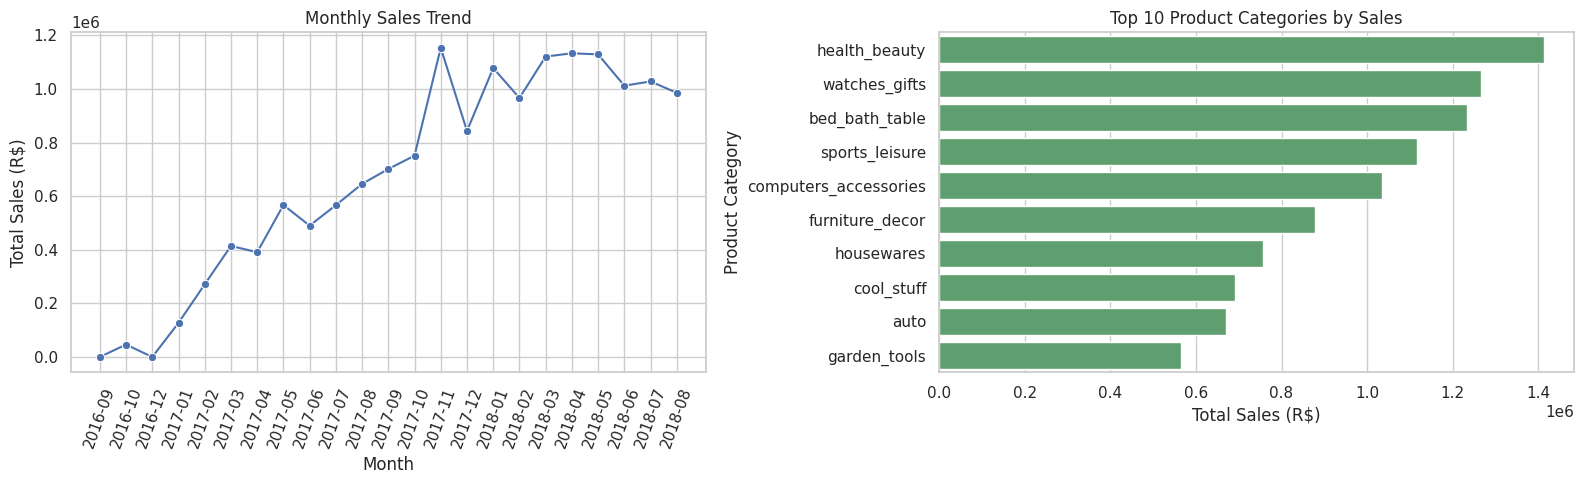

In [ ]:
monthly_transaction = (
    fact
    .groupby("order_month", as_index=False)
    .agg(
        total_orders=("order_id", "nunique"),
        total_customers=(
            "customer_unique_id",
            "nunique"
        ),
        total_sales=(
            "order_total_value",
            "sum"
        ),
        average_order_value=(
            "order_total_value",
            "mean"
        )
    )
)

category_performance = (
    fact
    .groupby(
        "order_main_category",
        as_index=False
    )
    .agg(
        total_orders=("order_id", "nunique"),
        total_sales=(
            "order_total_value",
            "sum"
        ),
        average_review=(
            "review_score",
            "mean"
        )
    )
    .sort_values(
        "total_sales",
        ascending=False
    )
)

display(monthly_transaction.tail(12))
display(category_performance.head(10))

figure, axes = plt.subplots(
    1,
    2,
    figsize=(16, 5)
)

sns.lineplot(
    data=monthly_transaction,
    x="order_month",
    y="total_sales",
    marker="o",
    color="#4C72B0",
    ax=axes[0]
)

axes[0].set_title(
    "Monthly Sales Trend"
)

axes[0].set_xlabel("Month")
axes[0].set_ylabel("Total Sales (R$)")

axes[0].tick_params(
    axis="x",
    rotation=70
)

sns.barplot(
    data=category_performance.head(10),
    y="order_main_category",
    x="total_sales",
    color="#55A868",
    ax=axes[1]
)

axes[1].set_title(
    "Top 10 Product Categories by Sales"
)

axes[1].set_xlabel("Total Sales (R$)")
axes[1].set_ylabel("Product Category")

plt.tight_layout()
plt.show()

## 9. Fungsi customer feature engineering

In [ ]:
def safe_mode(series, default="unknown"):
    """
    Mengambil nilai yang paling sering muncul.
    Digunakan untuk kategori, payment, dan state.
    """

    mode = series.dropna().mode()

    if len(mode) > 0:
        return mode.iloc[0]

    return default


def build_customer_snapshot(
    feature_start,
    cutoff_date,
    snapshot_name
):
    """
    Feature period:
    Enam bulan sebelum cutoff.

    Label period:
    90 hari setelah cutoff.

    is_churn = 1:
    Customer tidak membeli dalam 90 hari.

    is_churn = 0:
    Customer membeli kembali dalam 90 hari.
    """

    feature_start = pd.Timestamp(
        feature_start
    )

    cutoff_date = pd.Timestamp(
        cutoff_date
    )

    label_end_date = (
        cutoff_date
        + pd.Timedelta(days=90)
    )

    # --------------------------------------------------------
    # 1. Data sebelum cutoff untuk membuat fitur
    # --------------------------------------------------------

    feature_data = fact[
        (
            fact["order_purchase_timestamp"]
            >= feature_start
        )
        & (
            fact["order_purchase_timestamp"]
            < cutoff_date
        )
    ].copy()

    # --------------------------------------------------------
    # 2. Data 90 hari setelah cutoff untuk membuat label
    # --------------------------------------------------------

    label_data = fact[
        (
            fact["order_purchase_timestamp"]
            >= cutoff_date
        )
        & (
            fact["order_purchase_timestamp"]
            < label_end_date
        )
    ].copy()

    grouped = feature_data.groupby(
        "customer_unique_id"
    )

    # --------------------------------------------------------
    # 3. Agregasi fitur customer
    # --------------------------------------------------------

    customer = grouped.agg(
        last_purchase=(
            "order_purchase_timestamp",
            "max"
        ),
        total_orders=(
            "order_id",
            "nunique"
        ),
        total_spend=(
            "order_total_value",
            "sum"
        ),
        avg_review_score=(
            "review_score",
            "mean"
        ),
        total_reviews=(
            "review_score",
            "count"
        ),
        total_items=(
            "total_items",
            "sum"
        ),
        total_categories=(
            "order_main_category",
            "nunique"
        )
    )

    # Recency
    customer["recency_days"] = (
        cutoff_date
        - customer["last_purchase"]
    ).dt.days

    # Average order value
    customer["average_order_value"] = (
        customer["total_spend"]
        / customer["total_orders"]
    )

    # Rata-rata item per order
    customer["average_items_per_order"] = (
        customer["total_items"]
        / customer["total_orders"]
    )

    # Penanda customer satu transaksi
    customer["single_order_flag"] = (
        customer["total_orders"] == 1
    ).astype(int)

    # --------------------------------------------------------
    # 4. Rata-rata jarak antartransaksi
    # --------------------------------------------------------

    ordered_dates = (
        feature_data[
            [
                "customer_unique_id",
                "order_purchase_timestamp"
            ]
        ]
        .drop_duplicates()
        .sort_values(
            [
                "customer_unique_id",
                "order_purchase_timestamp"
            ]
        )
    )

    ordered_dates["order_gap"] = (
        ordered_dates
        .groupby("customer_unique_id")
        ["order_purchase_timestamp"]
        .diff()
        .dt.total_seconds()
        .div(86400)
    )

    average_gap = (
        ordered_dates
        .groupby("customer_unique_id")
        ["order_gap"]
        .mean()
    )

    customer["avg_days_between_orders"] = (
        average_gap
        .reindex(customer.index)
        .fillna(0)
    )

    # --------------------------------------------------------
    # 5. Fitur kategorikal
    # --------------------------------------------------------

    customer["favorite_category"] = (
        grouped["order_main_category"]
        .agg(safe_mode)
    )

    customer["payment_method"] = (
        grouped["payment_type"]
        .agg(safe_mode)
    )

    customer["customer_state"] = (
        grouped["customer_state"]
        .agg(safe_mode)
    )

    # --------------------------------------------------------
    # 6. Customer tenure
    # --------------------------------------------------------

    first_purchase = (
        fact[
            fact["order_purchase_timestamp"]
            < cutoff_date
        ]
        .groupby("customer_unique_id")
        ["order_purchase_timestamp"]
        .min()
    )

    customer["customer_tenure_days"] = (
        cutoff_date
        - first_purchase.reindex(
            customer.index
        )
    ).dt.days

    # --------------------------------------------------------
    # 6b. Active span (pengganti tenure di model)
    # --------------------------------------------------------
    # Untuk pelanggan sekali beli, tenure == recency sehingga
    # keduanya kolinear. Active span = jarak pembelian pertama
    # sampai pembelian terakhir (0 untuk pelanggan sekali beli).
    customer["active_span_days"] = (
        customer["customer_tenure_days"]
        - customer["recency_days"]
    ).clip(lower=0)

    # --------------------------------------------------------
    # 7. Label churn 90 hari
    # --------------------------------------------------------

    returned_customers = set(
        label_data[
            "customer_unique_id"
        ].unique()
    )

    customer["is_churn"] = (
        ~customer.index.isin(
            returned_customers
        )
    ).astype(int)

    customer["snapshot_date"] = (
        cutoff_date
    )

    customer["label_end_date"] = (
        label_end_date
    )

    customer["window"] = (
        snapshot_name
    )

    customer = (
        customer
        .drop(
            columns=[
                "last_purchase",
                "total_items"
            ]
        )
        .reset_index()
    )

    return customer


feature_definition = pd.DataFrame({
    "Feature Group": [
        "Recency",
        "Frequency",
        "Monetary",
        "Repeat Behavior",
        "Order Value",
        "Product",
        "Payment",
        "Review",
        "Customer",
        "Target"
    ],
    "Feature Name": [
        "recency_days",
        "total_orders",
        "total_spend",
        "avg_days_between_orders",
        "average_order_value",
        "favorite_category",
        "payment_method",
        "avg_review_score",
        "customer_state and tenure",
        "is_churn"
    ],
    "Description": [
        "Days from the last purchase to the cutoff",
        "Number of orders in the feature window",
        "Total customer spend",
        "Average days between orders",
        "Average value per order",
        "Most frequently purchased category",
        "Dominant payment method",
        "Average review score",
        "Customer location and relationship length",
        "No purchase within 90 days"
    ]
})

display(feature_definition)

,Feature Group,Feature Name,Description
0,Recency,recency_days,Days from the last purchase to the cutoff
1,Frequency,total_orders,Number of orders in the feature window
2,Monetary,total_spend,Total customer spend
3,Repeat Behavior,avg_days_between_orders,Average days between orders
4,Order Value,average_order_value,Average value per order
5,Product,favorite_category,Most frequently purchased category
6,Payment,payment_method,Dominant payment method
7,Review,avg_review_score,Average review score
8,Customer,customer_state and tenure,Customer location and relationship length
9,Target,is_churn,No purchase within 90 days


## 10. Membuat rolling snapshots dan holdout

,window,total_observations,unique_customers,active_customers,churn_customers,churn_rate
0,training_2017_07,13594,13594,114,13480,0.9916
1,training_2017_08,16641,16641,139,16502,0.9916
2,training_2017_09,19091,19091,185,18906,0.9903
3,training_2017_10,20635,20635,207,20428,0.9900
4,training_2017_11,22742,22742,227,22515,0.9900
5,training_2017_12,26415,26415,233,26182,0.9912
6,training_2018_01,28760,28760,225,28535,0.9922
7,training_2018_02,31912,31912,247,31665,0.9923
8,training_2018_03,34215,34215,280,33935,0.9918


Total rolling training observations: 214,005
Unique customers in rolling training: 55,267
Number of holdout customers: 38,838


,customer_unique_id,snapshot_date,label_end_date,recency_days,total_orders,total_spend,is_churn
0,0000f46a3911fa3c0805444483337064,2017-07-01,2017-09-29,112,1,86.22,1
1,0005e1862207bf6ccc02e4228effd9a0,2017-07-01,2017-09-29,118,1,150.12,1
2,00115fc7123b5310cf6d3a3aa932699e,2017-07-01,2017-09-29,160,1,76.11,1
3,0011805441c0d1b68b48002f1d005526,2017-07-01,2017-09-29,67,1,297.14,1
4,0011857aff0e5871ce5eb429f21cdaf5,2017-07-01,2017-09-29,2,1,192.83,1
5,00191a9719ef48ebb5860b130347bf33,2017-07-01,2017-09-29,72,1,58.86,1
6,001a2bf0e46c684031af91fb2bce149d,2017-07-01,2017-09-29,1,1,36.73,1
7,001f3c4211216384d5fe59b041ce1461,2017-07-01,2017-09-29,103,1,35.84,1
8,002043098f10ba39a4600b6c52fbfe3c,2017-07-01,2017-09-29,96,1,237.81,1
9,002b4cd83fabaffaa475f78ea5ef3e08,2017-07-01,2017-09-29,149,1,64.42,1


,customer_unique_id,snapshot_date,label_end_date,recency_days,total_orders,total_spend,is_churn
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-06-01,2018-08-30,21,1,141.90,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-06-01,2018-08-30,24,1,27.19,1
2,0004bd2a26a76fe21f786e4fbd80607f,2018-06-01,2018-08-30,56,1,166.98,1
3,00050ab1314c0e55a6ca13cf7181fecf,2018-06-01,2018-08-30,41,1,35.38,1
4,00053a61a98854899e70ed204dd4bafe,2018-06-01,2018-08-30,92,1,419.18,1
5,0005ef4cd20d2893f0d9fbd94d3c0d97,2018-06-01,2018-08-30,80,1,129.76,1
6,00090324bbad0e9342388303bb71ba0a,2018-06-01,2018-08-30,68,1,63.66,1
7,000949456b182f53c18b68d6babc79c1,2018-06-01,2018-08-30,38,1,82.05,1
8,000c8bdb58a29e7115cfc257230fb21b,2018-06-01,2018-08-30,170,1,29.00,1
9,000d460961d6dbfa3ec6c9f5805769e1,2018-06-01,2018-08-30,144,1,36.68,1


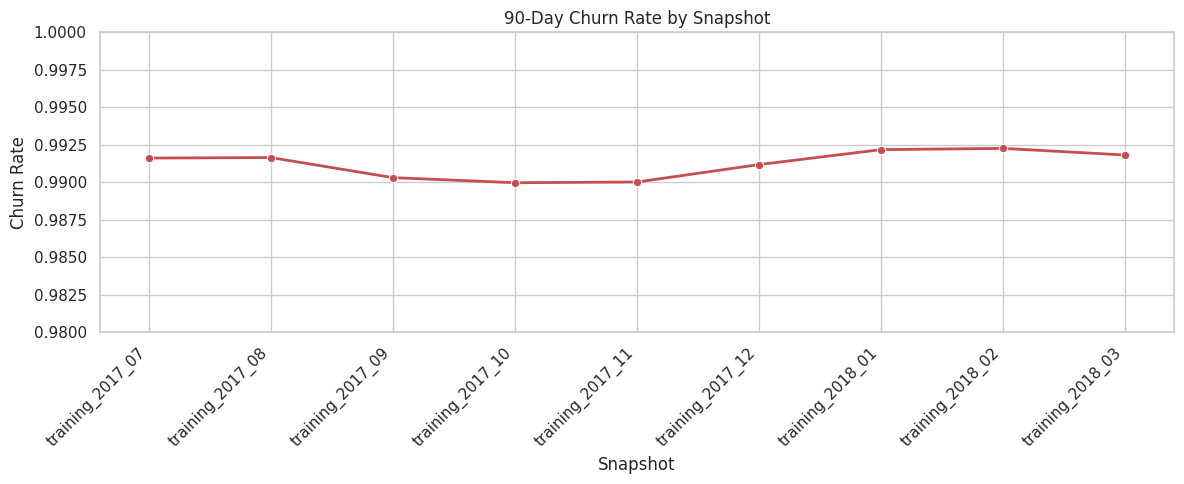

In [ ]:
# Cutoff bulanan untuk data training
training_cutoff_dates = pd.date_range(
    start="2017-07-01",
    end="2018-03-01",
    freq="MS"
)

training_snapshots = []

for cutoff_date in training_cutoff_dates:

    # Enam bulan sebelum cutoff
    feature_start = (
        cutoff_date
        - pd.DateOffset(months=6)
    )

    snapshot_name = (
        "training_"
        + cutoff_date.strftime("%Y_%m")
    )

    snapshot = build_customer_snapshot(
        feature_start=feature_start,
        cutoff_date=cutoff_date,
        snapshot_name=snapshot_name
    )

    training_snapshots.append(
        snapshot
    )

# Menggabungkan seluruh snapshot
calibration = pd.concat(
    training_snapshots,
    ignore_index=True
)

# Holdout terbaru
# Fitur: Desember 2017–Mei 2018
# Label: Juni–Agustus 2018
holdout = build_customer_snapshot(
    feature_start="2017-12-01",
    cutoff_date="2018-06-01",
    snapshot_name="holdout_2018_06"
)

calibration.to_csv(
    DATA_DIR
    / "rolling_training_customer_features.csv",
    index=False
)

holdout.to_csv(
    DATA_DIR
    / "holdout_90_days_customer_features.csv",
    index=False
)

snapshot_summary = (
    calibration
    .groupby("window", as_index=False)
    .agg(
        total_observations=(
            "customer_unique_id",
            "size"
        ),
        unique_customers=(
            "customer_unique_id",
            "nunique"
        ),
        active_customers=(
            "is_churn",
            lambda value:
            (value == 0).sum()
        ),
        churn_customers=(
            "is_churn",
            lambda value:
            (value == 1).sum()
        ),
        churn_rate=(
            "is_churn",
            "mean"
        )
    )
)

display(
    snapshot_summary.round(4)
)

print(
    "Total rolling training observations:",
    f"{len(calibration):,}"
)

print(
    "Unique customers in rolling training:",
    f"{calibration['customer_unique_id'].nunique():,}"
)

print(
    "Number of holdout customers:",
    f"{len(holdout):,}"
)

display(
    calibration[
        [
            "customer_unique_id",
            "snapshot_date",
            "label_end_date",
            "recency_days",
            "total_orders",
            "total_spend",
            "is_churn"
        ]
    ].head(10)
)

display(
    holdout[
        [
            "customer_unique_id",
            "snapshot_date",
            "label_end_date",
            "recency_days",
            "total_orders",
            "total_spend",
            "is_churn"
        ]
    ].head(10)
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=snapshot_summary,
    x="window",
    y="churn_rate",
    marker="o",
    linewidth=2,
    color="#C44E52"
)

plt.title(
    "90-Day Churn Rate by Snapshot"
)

plt.xlabel("Snapshot")
plt.ylabel("Churn Rate")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylim(0.98, 1.00)
plt.tight_layout()
plt.show()

## 11. Analisis distribusi label

,Dataset,Total Observations,Unique Customers,Active,Churn,Active Rate,Churn Rate
0,Rolling Training,214005,55267,1857,212148,0.0087,0.9913
1,Holdout (90-Day Label Window),38838,38838,260,38578,0.0067,0.9933


,window,is_churn,total_customers,status
0,training_2017_07,0,114,Active
1,training_2017_07,1,13480,Churn
2,training_2017_08,0,139,Active
3,training_2017_08,1,16502,Churn
4,training_2017_09,0,185,Active
5,training_2017_09,1,18906,Churn
6,training_2017_10,0,207,Active
7,training_2017_10,1,20428,Churn
8,training_2017_11,0,227,Active
9,training_2017_11,1,22515,Churn


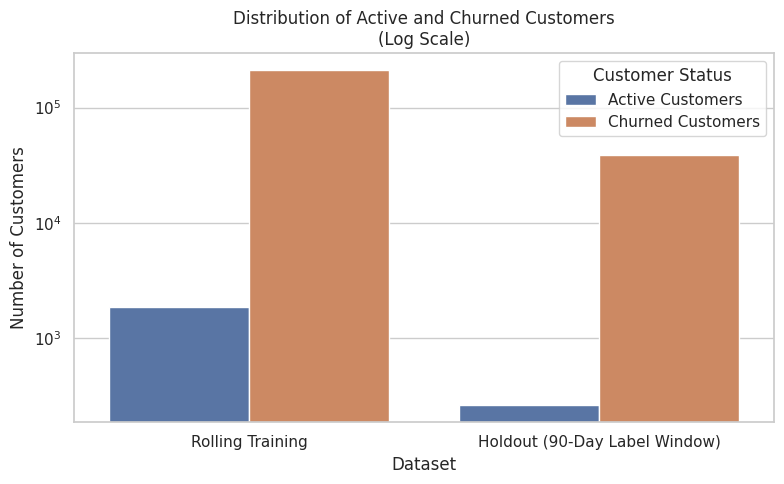

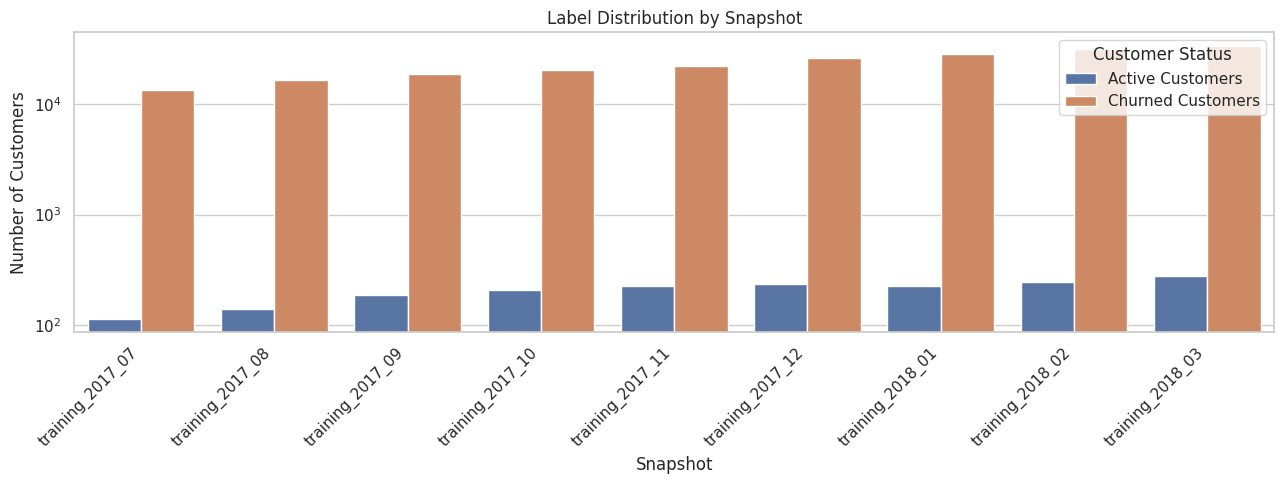

In [ ]:
label_summary = pd.DataFrame([
    {
        "Dataset": "Rolling Training",
        "Total Observations":
        len(calibration),
        "Unique Customers":
        calibration[
            "customer_unique_id"
        ].nunique(),
        "Active":
        (calibration["is_churn"] == 0).sum(),
        "Churn":
        (calibration["is_churn"] == 1).sum(),
        "Active Rate":
        (calibration["is_churn"] == 0).mean(),
        "Churn Rate":
        calibration["is_churn"].mean()
    },
    {
        "Dataset": "Holdout (90-Day Label Window)",
        "Total Observations":
        len(holdout),
        "Unique Customers":
        holdout[
            "customer_unique_id"
        ].nunique(),
        "Active":
        (holdout["is_churn"] == 0).sum(),
        "Churn":
        (holdout["is_churn"] == 1).sum(),
        "Active Rate":
        (holdout["is_churn"] == 0).mean(),
        "Churn Rate":
        holdout["is_churn"].mean()
    }
])

display(
    label_summary.round(4)
)

# Distribusi setiap snapshot
snapshot_class_distribution = (
    calibration
    .groupby(
        [
            "window",
            "is_churn"
        ],
        as_index=False
    )
    .size()
    .rename(
        columns={
            "size": "total_customers"
        }
    )
)

snapshot_class_distribution[
    "status"
] = snapshot_class_distribution[
    "is_churn"
].map({
    0: "Active",
    1: "Churn"
})

display(
    snapshot_class_distribution.head(20)
)

# Grafik Active dan Churn
label_long = label_summary.melt(
    id_vars="Dataset",
    value_vars=[
        "Active",
        "Churn"
    ],
    var_name="Status",
    value_name="Number of Customers"
)

label_long["Status"] = label_long["Status"].map({
    "Active": "Active Customers",
    "Churn": "Churned Customers"
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=label_long,
    x="Dataset",
    y="Number of Customers",
    hue="Status"
)

plt.yscale("log")

plt.title(
    "Distribution of Active and Churned Customers\n"
    "(Log Scale)"
)
plt.xlabel("Dataset")
plt.ylabel("Number of Customers")
plt.legend(title="Customer Status")

plt.tight_layout()
plt.show()

# Grafik per snapshot
plt.figure(figsize=(13, 5))

sns.barplot(
    data=snapshot_class_distribution.assign(
        status=snapshot_class_distribution["status"].map({
            "Active": "Active Customers",
            "Churn": "Churned Customers"
        })
    ),
    x="window",
    y="total_customers",
    hue="status"
)

plt.yscale("log")

plt.title(
    "Label Distribution by Snapshot"
)
plt.xlabel("Snapshot")
plt.ylabel("Number of Customers")
plt.legend(title="Customer Status")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

## 12. Preprocessing dan validation split tanpa data leakage

Pada tahap ini data calibration dibagi menjadi development dan validation secara **group-aware**, sehingga customer yang sama tidak berada di kedua subset. Preprocessor belum di-fit di sini; ia akan dimasukkan ke dalam pipeline model agar median, scaling, dan encoding hanya dipelajari dari training fold.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit


numeric_features = [
    "recency_days",
    "total_orders",
    "total_spend",
    "average_order_value",
    "avg_days_between_orders",
    "single_order_flag",
    "avg_review_score",
    "total_reviews",
    "average_items_per_order",
    "total_categories",
    "active_span_days"
]

categorical_features = [
    "favorite_category",
    "payment_method",
    "customer_state"
]

model_features = numeric_features + categorical_features


def make_preprocessor():
    """Membuat preprocessor baru agar dapat di-fit di setiap CV fold."""

    numeric_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ])

    try:
        encoder = OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=0.01,
            sparse_output=False
        )
    except TypeError:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=0.01,
            sparse=False
        )

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            encoder
        )
    ])

    return ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ])


X_calibration_raw = calibration[model_features].copy()
X_holdout_raw = holdout[model_features].copy()

y_calibration = calibration["is_churn"].to_numpy()
y_holdout = holdout["is_churn"].to_numpy()

training_groups = calibration["customer_unique_id"].to_numpy()

# Satu validation set yang sama untuk ML dan DL.
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

development_index, validation_index = next(
    group_split.split(
        X_calibration_raw,
        y_calibration,
        groups=training_groups
    )
)

X_development_raw = X_calibration_raw.iloc[development_index].copy()
X_validation_raw = X_calibration_raw.iloc[validation_index].copy()

y_development = y_calibration[development_index]
y_validation = y_calibration[validation_index]

development_groups = training_groups[development_index]
validation_groups = training_groups[validation_index]

assert set(development_groups).isdisjoint(set(validation_groups)), (
    "Development and validation customers still overlap."
)

split_summary = pd.DataFrame([
    {
        "Subset": "Development",
        "Count": len(y_development),
        "Unique Customers": pd.Series(development_groups).nunique(),
        "Active": int((y_development == 0).sum()),
        "Churn": int((y_development == 1).sum()),
        "Churn Rate": y_development.mean()
    },
    {
        "Subset": "Validation",
        "Count": len(y_validation),
        "Unique Customers": pd.Series(validation_groups).nunique(),
        "Active": int((y_validation == 0).sum()),
        "Churn": int((y_validation == 1).sum()),
        "Churn Rate": y_validation.mean()
    },
    {
        "Subset": "Holdout (90-Day Label Window)",
        "Count": len(y_holdout),
        "Unique Customers": holdout["customer_unique_id"].nunique(),
        "Active": int((y_holdout == 0).sum()),
        "Churn": int((y_holdout == 1).sum()),
        "Churn Rate": y_holdout.mean()
    }
])

display(split_summary.round(4))

feature_input_table = pd.DataFrame({
    "Type": (
        ["Numerical"] * len(numeric_features)
        + ["Categorical"] * len(categorical_features)
    ),
    "Input Feature": model_features
})

display(feature_input_table)

print(
    "The preprocessor is not fitted here; it is learned inside each model pipeline."
)

,Subset,Count,Unique Customers,Active,Churn,Churn Rate
0,Development,171164,44213,1475,169689,0.9914
1,Validation,42841,11054,382,42459,0.9911
2,Holdout (90-Day Label Window),38838,38838,260,38578,0.9933


,Type,Input Feature
0,Numerical,recency_days
1,Numerical,total_orders
2,Numerical,total_spend
3,Numerical,average_order_value
4,Numerical,avg_days_between_orders
5,Numerical,single_order_flag
6,Numerical,avg_review_score
7,Numerical,total_reviews
8,Numerical,average_items_per_order
9,Numerical,total_categories


The preprocessor is not fitted here; it is learned inside each model pipeline.


## 13. Fungsi evaluasi model

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    roc_curve
)


def select_threshold(actual, probability):
    """Memilih threshold dari validation set berdasarkan balanced accuracy."""

    threshold_rows = []

    for threshold in np.linspace(0.05, 0.95, 181):
        prediction = (probability >= threshold).astype(int)

        threshold_rows.append({
            "threshold": threshold,
            "balanced_accuracy": balanced_accuracy_score(
                actual,
                prediction
            ),
            "mcc": matthews_corrcoef(actual, prediction),
            "recall_active": recall_score(
                actual,
                prediction,
                pos_label=0,
                zero_division=0
            )
        })

    threshold_table = (
        pd.DataFrame(threshold_rows)
        .sort_values(
            ["balanced_accuracy", "mcc", "recall_active"],
            ascending=False
        )
        .reset_index(drop=True)
    )

    return float(threshold_table.iloc[0]["threshold"]), threshold_table


def evaluate_model(
    model_name,
    actual,
    probability,
    threshold=0.5
):
    """Menghitung evaluasi lengkap pada probabilitas dan threshold tertentu."""

    prediction = (probability >= threshold).astype(int)

    metrics = {
        "model": model_name,
        "threshold": threshold,
        "accuracy": accuracy_score(actual, prediction),
        "balanced_accuracy": balanced_accuracy_score(actual, prediction),
        "precision_churn": precision_score(
            actual, prediction, pos_label=1, zero_division=0
        ),
        "recall_churn": recall_score(
            actual, prediction, pos_label=1, zero_division=0
        ),
        "f1_churn": f1_score(
            actual, prediction, pos_label=1, zero_division=0
        ),
        "precision_active": precision_score(
            actual, prediction, pos_label=0, zero_division=0
        ),
        "recall_active": recall_score(
            actual, prediction, pos_label=0, zero_division=0
        ),
        "f1_active": f1_score(
            actual, prediction, pos_label=0, zero_division=0
        ),
        "roc_auc": roc_auc_score(actual, probability),
        "pr_auc_churn": average_precision_score(actual, probability),
        "pr_auc_active": average_precision_score(
            1 - actual,
            1 - probability
        ),
        "mcc": matthews_corrcoef(actual, prediction)
    }

    report = classification_report(
        actual,
        prediction,
        labels=[0, 1],
        target_names=["Active", "Churn"],
        output_dict=True,
        zero_division=0
    )

    matrix = confusion_matrix(
        actual,
        prediction,
        labels=[0, 1]
    )

    return metrics, prediction, report, matrix


metric_information = pd.DataFrame({
    "Metric": [
        "Balanced Accuracy",
        "PR-AUC Active",
        "Recall Active",
        "F1 Active",
        "ROC-AUC",
        "MCC",
        "Accuracy"
    ],
    "Purpose": [
        "Average performance on the active and churn classes",
        "Ranking ability for the very small active class",
        "Share of active customers correctly identified",
        "Combination of active-class precision and recall",
        "Ability to separate both classes across all thresholds",
        "Correlation between predicted and observed values on imbalanced data",
        "Supporting metric only, given the extreme class imbalance"
    ],
    "Use": [
        "Threshold selection",
        "Model selection",
        "Main evaluation",
        "Main evaluation",
        "Main evaluation",
        "Main evaluation",
        "Supporting"
    ]
})

display(metric_information)

,Metric,Purpose,Use
0,Balanced Accuracy,Average performance on the active and churn cl...,Threshold selection
1,PR-AUC Active,Ranking ability for the very small active class,Model selection
2,Recall Active,Share of active customers correctly identified,Main evaluation
3,F1 Active,Combination of active-class precision and recall,Main evaluation
4,ROC-AUC,Ability to separate both classes across all th...,Main evaluation
5,MCC,Correlation between predicted and observed val...,Main evaluation
6,Accuracy,"Supporting metric only, given the extreme clas...",Supporting


## 14. Training tiga model Machine Learning

Hyperparameter dicari hanya pada development set menggunakan `StratifiedGroupKFold`. Threshold setiap model ditentukan dari validation set, model kemudian di-fit ulang pada seluruh calibration, dan holdout digunakan sekali sebagai evaluasi akhir.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV


try:
    from sklearn.model_selection import StratifiedGroupKFold

    cross_validation = StratifiedGroupKFold(
        n_splits=3,
        shuffle=True,
        random_state=SEED
    )
    cv_method = "StratifiedGroupKFold"

except ImportError:
    from sklearn.model_selection import GroupKFold

    cross_validation = GroupKFold(n_splits=3)
    cv_method = "GroupKFold"

print("Metode cross-validation:", cv_method)


def model_pipeline(classifier):
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", classifier)
    ])


model_searches = {
    "Logistic Regression": RandomizedSearchCV(
        estimator=model_pipeline(
            LogisticRegression(random_state=SEED)
        ),
        param_distributions={
            "classifier__C": np.logspace(-3, 2, 20),
            "classifier__class_weight": ["balanced"],
            "classifier__solver": ["lbfgs"],
            "classifier__max_iter": [2000]
        },
        n_iter=N_ITER_ML,
        scoring="roc_auc",
        cv=cross_validation,
        random_state=SEED,
        n_jobs=-1,
        refit=True
    ),
    "Random Forest": RandomizedSearchCV(
        estimator=model_pipeline(
            RandomForestClassifier(
                random_state=SEED,
                n_jobs=-1
            )
        ),
        param_distributions={
            "classifier__n_estimators": [150, 250, 350],
            "classifier__max_depth": [4, 6, 8, 10],
            "classifier__min_samples_leaf": [2, 5, 10, 20],
            "classifier__max_features": ["sqrt", "log2"],
            "classifier__class_weight": ["balanced"]
        },
        n_iter=N_ITER_ML,
        scoring="roc_auc",
        cv=cross_validation,
        random_state=SEED,
        n_jobs=-1,
        refit=True
    ),
    "Histogram Gradient Boosting": RandomizedSearchCV(
        estimator=model_pipeline(
            HistGradientBoostingClassifier(
                random_state=SEED,
                class_weight="balanced"
            )
        ),
        param_distributions={
            "classifier__learning_rate": [0.03, 0.05, 0.10],
            "classifier__max_iter": [100, 150, 200],
            "classifier__max_leaf_nodes": [15, 31, 63],
            "classifier__min_samples_leaf": [10, 20, 30],
            "classifier__l2_regularization": [0.0, 0.1, 1.0]
        },
        n_iter=N_ITER_ML,
        scoring="roc_auc",
        cv=cross_validation,
        random_state=SEED,
        n_jobs=-1,
        refit=True
    )
}

display(pd.DataFrame([
    {
        "Model": model_name,
        "Random Search Trials": N_ITER_ML,
        "CV Folds": 3,
        "Preprocessing within CV": "Yes"
    }
    for model_name in model_searches
]))

trained_models = {}
model_probabilities = {}
validation_probabilities = {}
model_predictions = {}
model_thresholds = {}

metrics_rows = []
validation_metrics_rows = []
classification_reports = {}
confusion_matrices = {}
roc_results = {}
best_parameters = {}

for model_name, search in model_searches.items():
    print("\n" + "=" * 65)
    print("TUNING:", model_name)
    print("=" * 65)

    search.fit(
        X_development_raw,
        y_development,
        groups=development_groups
    )

    tuned_model = search.best_estimator_

    validation_probability = tuned_model.predict_proba(
        X_validation_raw
    )[:, 1]

    threshold, threshold_table = select_threshold(
        y_validation,
        validation_probability
    )

    validation_metrics, _, _, _ = evaluate_model(
        model_name,
        y_validation,
        validation_probability,
        threshold
    )
    validation_metrics["cv_roc_auc"] = search.best_score_
    validation_metrics_rows.append(validation_metrics)

    # Fit ulang konfigurasi terpilih pada seluruh calibration.
    final_model = search.best_estimator_
    final_model.fit(X_calibration_raw, y_calibration)

    holdout_probability = final_model.predict_proba(
        X_holdout_raw
    )[:, 1]

    holdout_metrics, prediction, report, matrix = evaluate_model(
        model_name,
        y_holdout,
        holdout_probability,
        threshold
    )
    holdout_metrics["cv_roc_auc"] = search.best_score_
    holdout_metrics["selection_roc_auc"] = validation_metrics["roc_auc"]
    metrics_rows.append(holdout_metrics)

    trained_models[model_name] = final_model
    model_probabilities[model_name] = holdout_probability
    validation_probabilities[model_name] = validation_probability
    model_predictions[model_name] = prediction
    model_thresholds[model_name] = threshold
    classification_reports[model_name] = report
    confusion_matrices[model_name] = matrix
    best_parameters[model_name] = search.best_params_

    fpr, tpr, _ = roc_curve(y_holdout, holdout_probability)
    roc_results[model_name] = (fpr, tpr, holdout_metrics["roc_auc"])

    print("Best parameters:", search.best_params_)
    print("CV ROC-AUC:", round(search.best_score_, 4))
    print("Validation threshold:", round(threshold, 4))
    print("Validation PR-AUC Active:", round(validation_metrics["pr_auc_active"], 4))
    print("Holdout ROC-AUC:", round(holdout_metrics["roc_auc"], 4))

validation_ml_metrics = pd.DataFrame(validation_metrics_rows)
holdout_ml_metrics = pd.DataFrame(metrics_rows)

display(validation_ml_metrics.round(4))
display(holdout_ml_metrics.round(4))

best_parameter_table = pd.DataFrame([
    {
        "Model": model_name,
        "Best Parameters": str(parameters),
        "Validation Threshold": model_thresholds[model_name]
    }
    for model_name, parameters in best_parameters.items()
])

display(best_parameter_table)

joblib.dump(
    trained_models,
    MODEL_DIR / "machine_learning_models.joblib"
)

holdout_ml_metrics.to_csv(
    OUTPUT_DIR / "machine_learning_metrics.csv",
    index=False
)

Metode cross-validation: StratifiedGroupKFold


,Model,Random Search Trials,CV Folds,Preprocessing within CV
0,Logistic Regression,5,3,Yes
1,Random Forest,5,3,Yes
2,Histogram Gradient Boosting,5,3,Yes



TUNING: Logistic Regression
Best parameters: {'classifier__solver': 'lbfgs', 'classifier__max_iter': 2000, 'classifier__class_weight': 'balanced', 'classifier__C': np.float64(0.0018329807108324356)}
CV ROC-AUC: 0.6051
Validation threshold: 0.44
Validation PR-AUC Active: 0.025
Holdout ROC-AUC: 0.6136

TUNING: Random Forest
Best parameters: {'classifier__n_estimators': 150, 'classifier__min_samples_leaf': 20, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 6, 'classifier__class_weight': 'balanced'}
CV ROC-AUC: 0.5845
Validation threshold: 0.51
Validation PR-AUC Active: 0.0186
Holdout ROC-AUC: 0.6184

TUNING: Histogram Gradient Boosting
Best parameters: {'classifier__min_samples_leaf': 10, 'classifier__max_leaf_nodes': 63, 'classifier__max_iter': 100, 'classifier__learning_rate': 0.03, 'classifier__l2_regularization': 0.0}
CV ROC-AUC: 0.5743
Validation threshold: 0.48
Validation PR-AUC Active: 0.0161
Holdout ROC-AUC: 0.5547


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc
0,Logistic Regression,0.44,0.8430,0.5706,0.9926,0.8479,0.9146,0.0170,0.2932,0.0322,0.5824,0.9925,0.0250,0.0368,0.6051
1,Random Forest,0.51,0.7857,0.5754,0.9928,0.7895,0.8796,0.0152,0.3613,0.0292,0.5775,0.9925,0.0186,0.0347,0.5845
2,Histogram Gradient Boosting,0.48,0.8336,0.5541,0.9922,0.8386,0.9090,0.0148,0.2696,0.0281,0.5437,0.9917,0.0161,0.0276,0.5743


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc,selection_roc_auc
0,Logistic Regression,0.44,0.8775,0.5888,0.9946,0.8815,0.9346,0.0166,0.2962,0.0314,0.6136,0.9951,0.0195,0.0446,0.6051,0.5824
1,Random Forest,0.51,0.8176,0.5892,0.9948,0.8207,0.8994,0.0133,0.3577,0.0256,0.6184,0.9951,0.0229,0.0378,0.5845,0.5775
2,Histogram Gradient Boosting,0.48,0.8543,0.5676,0.9944,0.8582,0.9213,0.0130,0.2769,0.0248,0.5547,0.9939,0.0162,0.0315,0.5743,0.5437


,Model,Best Parameters,Validation Threshold
0,Logistic Regression,"{'classifier__solver': 'lbfgs', 'classifier__m...",0.44
1,Random Forest,"{'classifier__n_estimators': 150, 'classifier_...",0.51
2,Histogram Gradient Boosting,"{'classifier__min_samples_leaf': 10, 'classifi...",0.48


## 15. Deep Learning Keras MLP

Konfigurasi neural network dipilih berdasarkan validation set yang sama dengan model machine learning. Preprocessor deep learning juga dipelajari hanya dari development ketika tuning dan di-fit ulang pada seluruh calibration sebelum pengujian holdout.

,Class,Weight
0,Active (0),58.0217
1,Churn (1),0.5043


,Hyperparameter,Options
0,number_layers,"[1, 2, 3]"
1,units,"[32, 64, 128]"
2,dropout,"[0.0, 0.2, 0.3]"
3,learning_rate,"[0.01, 0.005, 0.001]"
4,batch_size,"[128, 256, 512]"


Trial 1/4 | Validation AUC = 0.5762
Trial 2/4 | Validation AUC = 0.5775
Trial 3/4 | Validation AUC = 0.5759
Trial 4/4 | Validation AUC = 0.5793


,number_layers,units,dropout,learning_rate,batch_size,best_epoch,validation_auc
0,3,32,0.3,0.001,512,5,0.5793
1,1,128,0.3,0.001,128,6,0.5775
2,3,32,0.0,0.001,256,2,0.5762
3,1,32,0.0,0.010,512,2,0.5759


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc
0,Deep Learning (Keras MLP),0.49,0.8797,0.5579,0.9922,0.8855,0.9358,0.0178,0.2304,0.033,0.5786,0.9928,0.0282,0.0341,NaN


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc,selection_roc_auc
0,Deep Learning (Keras MLP),0.49,0.7486,0.5869,0.9948,0.7508,0.8558,0.0113,0.4231,0.022,0.6124,0.9951,0.0179,0.0327,NaN,0.5786


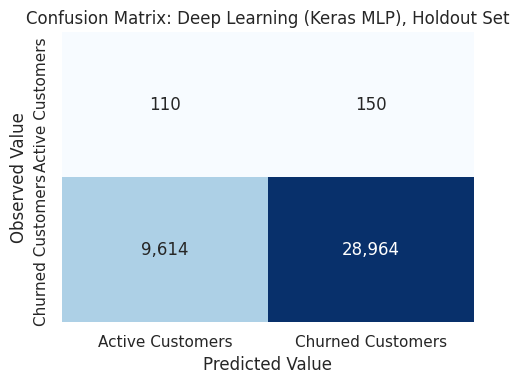

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


tf.random.set_seed(SEED)

# Reproducibility: seed Python, NumPy, dan TensorFlow sekaligus,
# serta paksa operasi TensorFlow berjalan deterministik.
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception as error:
    print("Op determinism could not be enabled:", error)

# Preprocessing tuning dipelajari hanya dari development.
dl_tuning_preprocessor = make_preprocessor()

X_train_dl = dl_tuning_preprocessor.fit_transform(
    X_development_raw
).astype("float32")

X_validation_dl = dl_tuning_preprocessor.transform(
    X_validation_raw
).astype("float32")


def create_class_weight(target):
    total_active = max(int((target == 0).sum()), 1)
    total_churn = max(int((target == 1).sum()), 1)

    return {
        0: len(target) / (2 * total_active),
        1: len(target) / (2 * total_churn)
    }


class_weight_dl = create_class_weight(y_development)

display(pd.DataFrame({
    "Class": ["Active (0)", "Churn (1)"],
    "Weight": [class_weight_dl[0], class_weight_dl[1]]
}).round(4))


def build_dl_model(
    input_dim,
    number_layers,
    units,
    dropout,
    learning_rate
):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,))
    ])

    for layer_number in range(number_layers):
        current_units = max(units // (2 ** layer_number), 8)
        model.add(layers.Dense(current_units, activation="relu"))

        if dropout > 0:
            model.add(layers.Dropout(dropout))

    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc")]
    )

    return model


search_space_dl = {
    "number_layers": [1, 2, 3],
    "units": [32, 64, 128],
    "dropout": [0.0, 0.2, 0.3],
    "learning_rate": [0.01, 0.005, 0.001],
    "batch_size": [128, 256, 512]
}

display(pd.DataFrame({
    "Hyperparameter": list(search_space_dl.keys()),
    "Options": [str(value) for value in search_space_dl.values()]
}))

trial_results = []
best_validation_auc = -np.inf
best_configuration = None
best_epoch = 1
best_validation_probability = None

for trial_number in range(N_TRIALS_DL):
    configuration = {
        key: random.choice(values)
        for key, values in search_space_dl.items()
    }

    model = build_dl_model(
        input_dim=X_train_dl.shape[1],
        number_layers=configuration["number_layers"],
        units=configuration["units"],
        dropout=configuration["dropout"],
        learning_rate=configuration["learning_rate"]
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=4,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_dl,
        y_development,
        validation_data=(X_validation_dl, y_validation),
        epochs=MAX_EPOCHS,
        batch_size=configuration["batch_size"],
        class_weight=class_weight_dl,
        callbacks=[early_stopping],
        verbose=0
    )

    validation_auc_values = history.history["val_auc"]
    current_best_epoch = int(np.argmax(validation_auc_values) + 1)
    current_best_auc = float(np.max(validation_auc_values))

    trial_results.append({
        **configuration,
        "best_epoch": current_best_epoch,
        "validation_auc": current_best_auc
    })

    print(
        f"Trial {trial_number + 1}/{N_TRIALS_DL} | "
        f"Validation AUC = {current_best_auc:.4f}"
    )

    if current_best_auc > best_validation_auc:
        best_validation_auc = current_best_auc
        best_configuration = configuration.copy()
        best_epoch = current_best_epoch
        best_validation_probability = model.predict(
            X_validation_dl,
            verbose=0
        ).ravel()

trial_dataframe = (
    pd.DataFrame(trial_results)
    .sort_values("validation_auc", ascending=False)
    .reset_index(drop=True)
)

display(trial_dataframe.round(4))

dl_threshold, dl_threshold_table = select_threshold(
    y_validation,
    best_validation_probability
)

dl_model_name = "Deep Learning (Keras MLP)"

dl_validation_metrics, _, _, _ = evaluate_model(
    dl_model_name,
    y_validation,
    best_validation_probability,
    dl_threshold
)
dl_validation_metrics["cv_roc_auc"] = np.nan
validation_metrics_rows.append(dl_validation_metrics)

# Fit ulang preprocessor dan model pada seluruh calibration.
final_dl_preprocessor = make_preprocessor()

X_calibration_dl = final_dl_preprocessor.fit_transform(
    X_calibration_raw
).astype("float32")

X_holdout_dl = final_dl_preprocessor.transform(
    X_holdout_raw
).astype("float32")

final_dl_model = build_dl_model(
    input_dim=X_calibration_dl.shape[1],
    number_layers=best_configuration["number_layers"],
    units=best_configuration["units"],
    dropout=best_configuration["dropout"],
    learning_rate=best_configuration["learning_rate"]
)

final_dl_model.fit(
    X_calibration_dl,
    y_calibration,
    epochs=best_epoch,
    batch_size=best_configuration["batch_size"],
    class_weight=create_class_weight(y_calibration),
    verbose=0
)

dl_probability = final_dl_model.predict(
    X_holdout_dl,
    verbose=0
).ravel()

dl_metrics, dl_prediction, dl_report, dl_matrix = evaluate_model(
    dl_model_name,
    y_holdout,
    dl_probability,
    dl_threshold
)
dl_metrics["cv_roc_auc"] = np.nan
dl_metrics["selection_roc_auc"] = dl_validation_metrics["roc_auc"]
metrics_rows.append(dl_metrics)

model_probabilities[dl_model_name] = dl_probability
validation_probabilities[dl_model_name] = best_validation_probability
model_predictions[dl_model_name] = dl_prediction
model_thresholds[dl_model_name] = dl_threshold
classification_reports[dl_model_name] = dl_report
confusion_matrices[dl_model_name] = dl_matrix

dl_fpr, dl_tpr, _ = roc_curve(y_holdout, dl_probability)
roc_results[dl_model_name] = (
    dl_fpr,
    dl_tpr,
    dl_metrics["roc_auc"]
)

final_dl_model.save(MODEL_DIR / "deep_learning_model.keras")
joblib.dump(
    final_dl_preprocessor,
    MODEL_DIR / "deep_learning_preprocessor.joblib"
)

pd.DataFrame(trial_results).to_csv(
    OUTPUT_DIR / "deep_learning_trials.csv",
    index=False
)

display(pd.DataFrame([dl_validation_metrics]).round(4))
display(pd.DataFrame([dl_metrics]).round(4))

plt.figure(figsize=(5, 4))
sns.heatmap(
    dl_matrix,
    annot=True,
    fmt=",",
    cmap="Blues",
    cbar=False,
    xticklabels=["Active Customers", "Churned Customers"],
    yticklabels=["Active Customers", "Churned Customers"]
)
plt.title("Confusion Matrix: Deep Learning (Keras MLP), Holdout Set")
plt.xlabel("Predicted Value")
plt.ylabel("Observed Value")
plt.tight_layout()
plt.show()

## 16. Perbandingan dan pemilihan model terbaik

Model final dipilih dari **PR-AUC kelas Active pada validation set**, bukan dari holdout, karena Active merupakan kelas minoritas dan holdout harus tetap menjadi data pengujian akhir.

**Keputusan desain:** kandidat model final dibatasi pada model yang dapat dijelaskan langsung dengan SHAP pada seluruh pelanggan holdout (Logistic Regression, Random Forest, Histogram Gradient Boosting). Keras MLP tetap dilatih dan dilaporkan sebagai **model pembanding**, tetapi tidak menjadi kandidat final. Dengan begitu, skor risiko, penjelasan SHAP, evaluasi Responsible AI, dan dashboard berasal dari model yang sama.


Validation results used for model selection:


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc,model_role
0,Deep Learning (Keras MLP),0.49,0.8797,0.5579,0.9922,0.8855,0.9358,0.0178,0.2304,0.0330,0.5786,0.9928,0.0282,0.0341,NaN,Benchmark
1,Logistic Regression,0.44,0.8430,0.5706,0.9926,0.8479,0.9146,0.0170,0.2932,0.0322,0.5824,0.9925,0.0250,0.0368,0.6051,Final candidate
2,Random Forest,0.51,0.7857,0.5754,0.9928,0.7895,0.8796,0.0152,0.3613,0.0292,0.5775,0.9925,0.0186,0.0347,0.5845,Final candidate
3,Histogram Gradient Boosting,0.48,0.8336,0.5541,0.9922,0.8386,0.9090,0.0148,0.2696,0.0281,0.5437,0.9917,0.0161,0.0276,0.5743,Final candidate


Holdout results used for final reporting:


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc,selection_roc_auc
0,Deep Learning (Keras MLP),0.49,0.7486,0.5869,0.9948,0.7508,0.8558,0.0113,0.4231,0.0220,0.6124,0.9951,0.0179,0.0327,NaN,0.5786
1,Histogram Gradient Boosting,0.48,0.8543,0.5676,0.9944,0.8582,0.9213,0.0130,0.2769,0.0248,0.5547,0.9939,0.0162,0.0315,0.5743,0.5437
2,Logistic Regression,0.44,0.8775,0.5888,0.9946,0.8815,0.9346,0.0166,0.2962,0.0314,0.6136,0.9951,0.0195,0.0446,0.6051,0.5824
3,Random Forest,0.51,0.8176,0.5892,0.9948,0.8207,0.8994,0.0133,0.3577,0.0256,0.6184,0.9951,0.0229,0.0378,0.5845,0.5775


Final candidates: Logistic Regression, Random Forest, Histogram Gradient Boosting
Model selected by active-class validation PR-AUC (among final candidates):
Logistic Regression


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc,selection_roc_auc
2,Logistic Regression,0.44,0.8775,0.5888,0.9946,0.8815,0.9346,0.0166,0.2962,0.0314,0.6136,0.9951,0.0195,0.0446,0.6051,0.5824


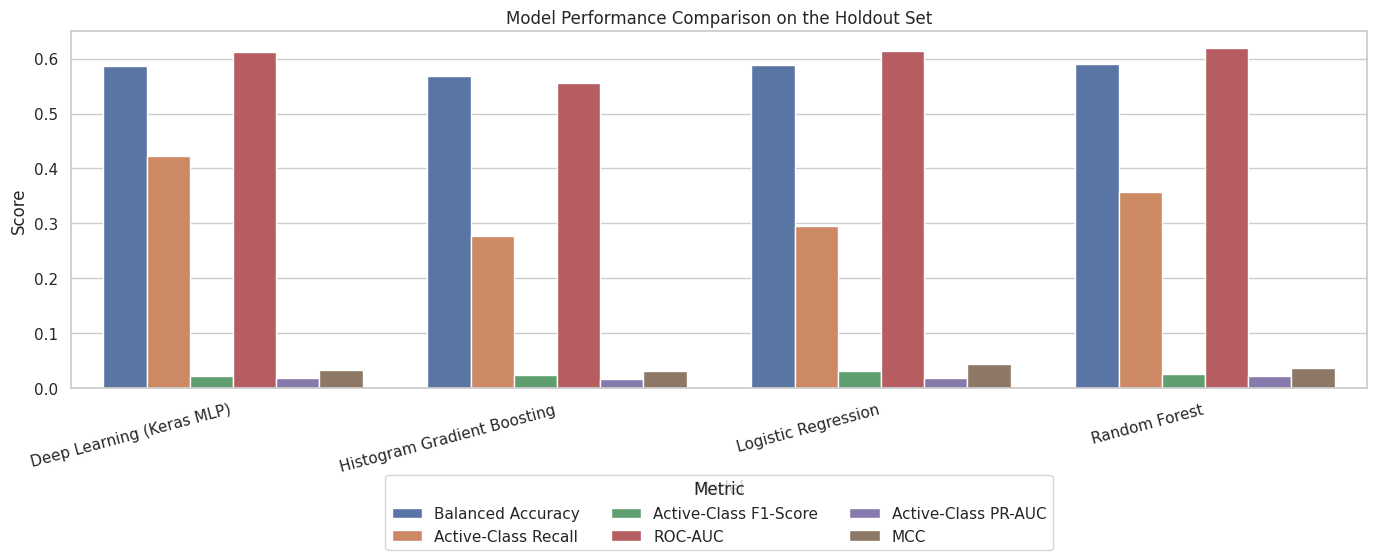

In [ ]:
# Tabel validation digunakan untuk pemilihan model.
validation_metrics_dataframe = (
    pd.DataFrame(validation_metrics_rows)
    .sort_values(
        ["pr_auc_active", "roc_auc", "mcc"],
        ascending=False
    )
    .reset_index(drop=True)
)

# Tabel holdout hanya digunakan untuk evaluasi final.
metrics_dataframe = (
    pd.DataFrame(metrics_rows)
    .sort_values("model")
    .reset_index(drop=True)
)

# Kandidat final: hanya model yang dapat dijelaskan langsung dengan SHAP.
# Keras MLP tetap dilaporkan sebagai pembanding.
FINAL_CANDIDATE_MODELS = list(trained_models.keys())

validation_metrics_dataframe["model_role"] = np.where(
    validation_metrics_dataframe["model"].isin(FINAL_CANDIDATE_MODELS),
    "Kandidat final",
    "Pembanding"
)

candidate_validation = validation_metrics_dataframe[
    validation_metrics_dataframe["model_role"] == "Kandidat final"
]

best_model_name = candidate_validation.iloc[0]["model"]

best_model_result = metrics_dataframe[
    metrics_dataframe["model"] == best_model_name
].copy()

validation_metrics_dataframe.to_csv(
    OUTPUT_DIR / "model_selection_validation.csv",
    index=False
)

metrics_dataframe.to_csv(
    OUTPUT_DIR / "model_performance_comparison.csv",
    index=False
)

comparison_all_sets = pd.concat([
    validation_metrics_dataframe.assign(evaluation_set="Validation"),
    metrics_dataframe.assign(evaluation_set="Holdout")
], ignore_index=True)

comparison_all_sets.to_csv(
    OUTPUT_DIR / "model_validation_and_holdout.csv",
    index=False
)

print("Validation results used for model selection:")
display(english_view(validation_metrics_dataframe.round(4)))

print("Holdout results used for final reporting:")
display(metrics_dataframe.round(4))

print("Final candidates:", ", ".join(FINAL_CANDIDATE_MODELS))
print("Model selected by active-class validation PR-AUC (among final candidates):")
print(best_model_name)
display(best_model_result.round(4))

if best_model_name in trained_models:
    selected_preprocessor = trained_models[
        best_model_name
    ].named_steps["preprocessor"]
else:
    selected_preprocessor = final_dl_preprocessor

selected_feature_names = selected_preprocessor.get_feature_names_out()
selected_feature_count = len(selected_feature_names)

metrics_long = metrics_dataframe.melt(
    id_vars="model",
    value_vars=[
        "balanced_accuracy",
        "recall_active",
        "f1_active",
        "roc_auc",
        "pr_auc_active",
        "mcc"
    ],
    var_name="metric",
    value_name="score"
)

metric_display_names = {
    "balanced_accuracy": "Balanced Accuracy",
    "recall_active": "Active-Class Recall",
    "f1_active": "Active-Class F1-Score",
    "roc_auc": "ROC-AUC",
    "pr_auc_active": "Active-Class PR-AUC",
    "mcc": "MCC"
}
metrics_plot = metrics_long.assign(
    metric=metrics_long["metric"].map(metric_display_names)
)

plt.figure(figsize=(14, 6))
sns.barplot(
    data=metrics_plot,
    x="model",
    y="score",
    hue="metric"
)
plt.title("Model Performance Comparison on the Holdout Set")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.legend(
    title="Metric",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=3
)
plt.tight_layout()
plt.show()

## 17. Confusion matrix, ROC Curve, dan feature importance

,Model,Class,Precision,Recall,F1 Score,Support
0,Logistic Regression,Active,0.0166,0.2962,0.0314,260.0
1,Logistic Regression,Churn,0.9946,0.8815,0.9346,38578.0
2,Random Forest,Active,0.0133,0.3577,0.0256,260.0
3,Random Forest,Churn,0.9948,0.8207,0.8994,38578.0
4,Histogram Gradient Boosting,Active,0.0130,0.2769,0.0248,260.0
5,Histogram Gradient Boosting,Churn,0.9944,0.8582,0.9213,38578.0
6,Deep Learning (Keras MLP),Active,0.0113,0.4231,0.0220,260.0
7,Deep Learning (Keras MLP),Churn,0.9948,0.7508,0.8558,38578.0


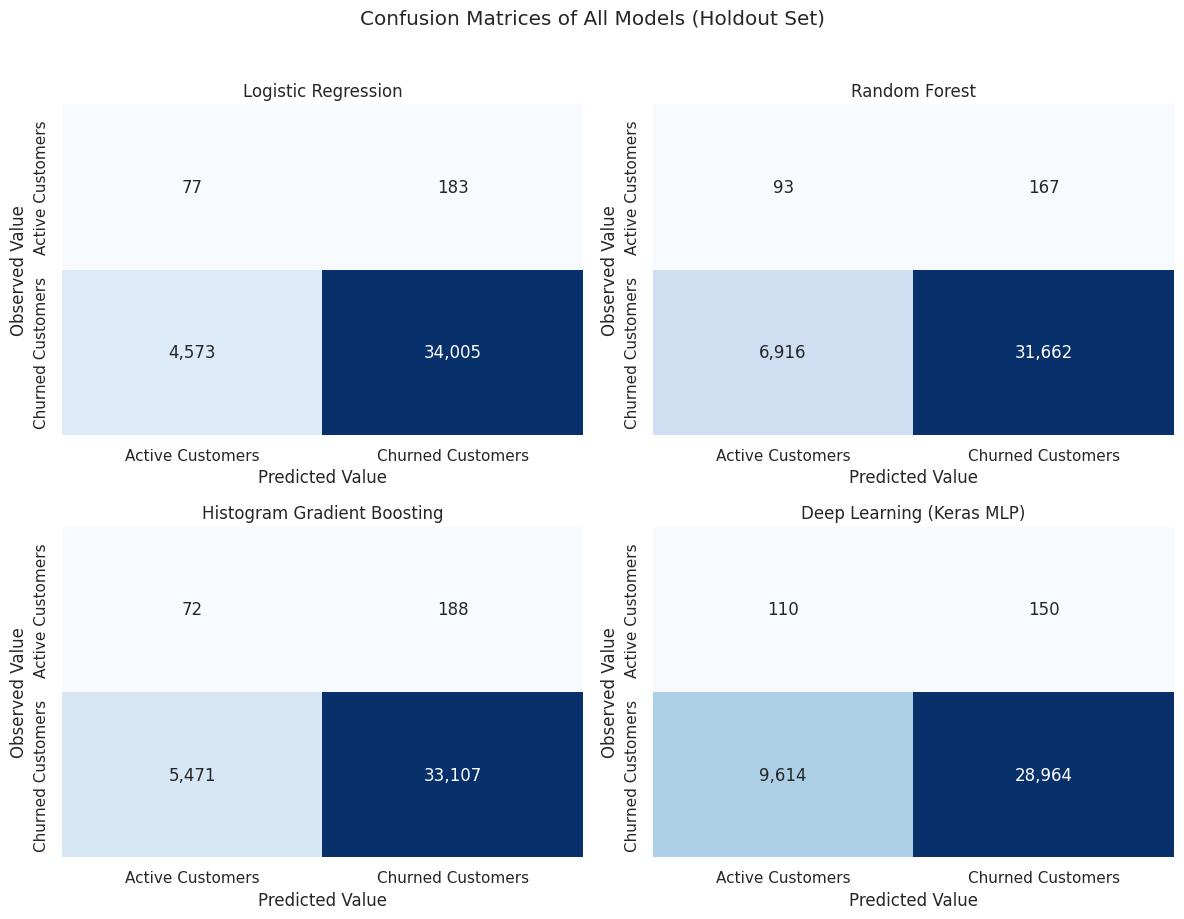

,Model,Actual Active - Predicted Active,Actual Active - Predicted Churn,Actual Churn - Predicted Active,Actual Churn - Predicted Churn
0,Logistic Regression,77,183,4573,34005
1,Random Forest,93,167,6916,31662
2,Histogram Gradient Boosting,72,188,5471,33107
3,Deep Learning (Keras MLP),110,150,9614,28964


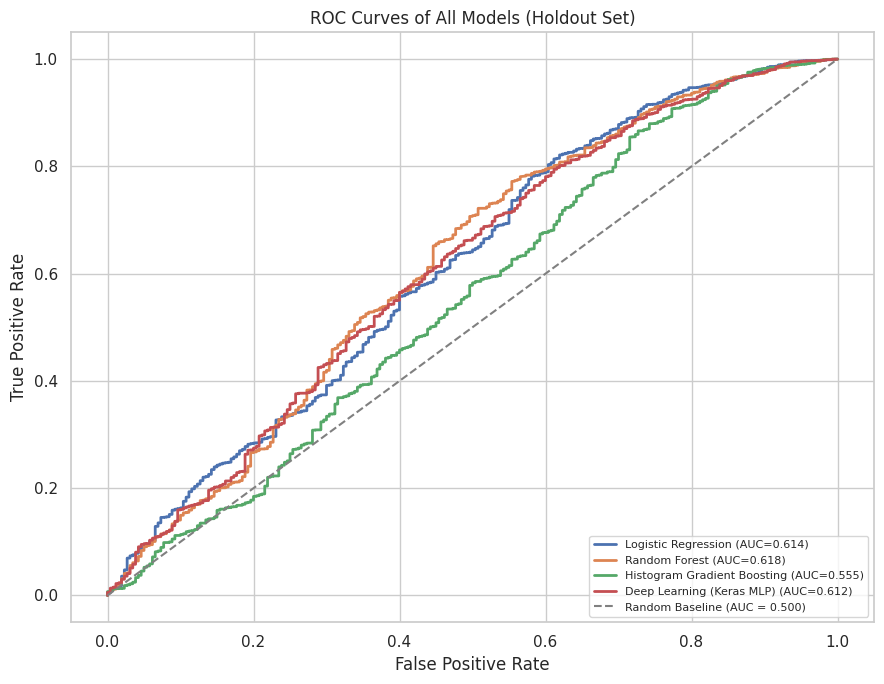

,model,threshold,roc_auc,balanced_accuracy,recall_active,mcc
3,Random Forest,0.51,0.6184,0.5892,0.3577,0.0378
2,Logistic Regression,0.44,0.6136,0.5888,0.2962,0.0446
0,Deep Learning (Keras MLP),0.49,0.6124,0.5869,0.4231,0.0327
1,Histogram Gradient Boosting,0.48,0.5547,0.5676,0.2769,0.0315


,feature,importance
10,numeric__active_span_days,0.1471
0,numeric__recency_days,0.0998
4,numeric__avg_days_between_orders,0.0884
7,numeric__total_reviews,0.0801
1,numeric__total_orders,0.0746
3,numeric__average_order_value,0.0730
2,numeric__total_spend,0.0722
5,numeric__single_order_flag,0.0708
8,numeric__average_items_per_order,0.0356
6,numeric__avg_review_score,0.0332


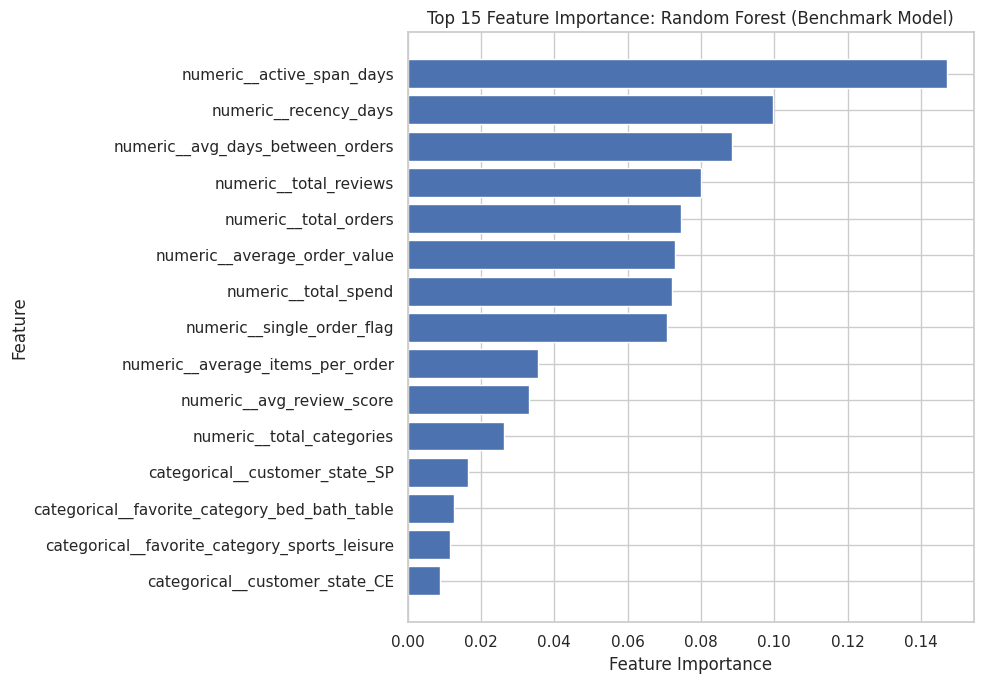

Note: this feature importance comes from Random Forest as a benchmark model. The main model was still selected by active-class PR-AUC on the validation set.


In [ ]:
# ============================================================
# 1. CLASSIFICATION REPORT HOLDOUT
# ============================================================

classification_report_rows = []

for model_name, report in classification_reports.items():
    for class_name in ["Active", "Churn"]:
        classification_report_rows.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1 Score": report[class_name]["f1-score"],
            "Support": report[class_name]["support"]
        })

classification_report_dataframe = pd.DataFrame(
    classification_report_rows
)

classification_report_dataframe.to_csv(
    OUTPUT_DIR / "classification_reports.csv",
    index=False
)

display(classification_report_dataframe.round(4))

# ============================================================
# 2. CONFUSION MATRIX SELURUH MODEL
# ============================================================

number_models = len(confusion_matrices)
figure, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()
confusion_matrix_rows = []

for axis, (model_name, matrix) in zip(
    axes,
    confusion_matrices.items()
):
    sns.heatmap(
        matrix,
        annot=True,
        fmt=",",
        cmap="Blues",
        cbar=False,
        ax=axis,
        xticklabels=["Active Customers", "Churned Customers"],
        yticklabels=["Active Customers", "Churned Customers"]
    )
    axis.set_title(model_name)
    axis.set_xlabel("Predicted Value")
    axis.set_ylabel("Observed Value")

    confusion_matrix_rows.append({
        "Model": model_name,
        "Actual Active - Predicted Active": matrix[0, 0],
        "Actual Active - Predicted Churn": matrix[0, 1],
        "Actual Churn - Predicted Active": matrix[1, 0],
        "Actual Churn - Predicted Churn": matrix[1, 1]
    })

for empty_axis in axes[number_models:]:
    empty_axis.axis("off")

plt.suptitle("Confusion Matrices of All Models (Holdout Set)", y=1.02)
plt.tight_layout()
plt.savefig(
    FIG_DIR / "confusion_matrix_all_models.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

confusion_matrix_dataframe = pd.DataFrame(confusion_matrix_rows)
confusion_matrix_dataframe.to_csv(
    OUTPUT_DIR / "confusion_matrices.csv",
    index=False
)
display(confusion_matrix_dataframe)

# ============================================================
# 3. ROC CURVE HOLDOUT
# ============================================================

plt.figure(figsize=(9, 7))

for model_name, (false_positive_rate, true_positive_rate, auc_value) in roc_results.items():
    plt.plot(
        false_positive_rate,
        true_positive_rate,
        linewidth=2,
        label=f"{model_name} (AUC={auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Baseline (AUC = 0.500)"
)
plt.title("ROC Curves of All Models (Holdout Set)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(
    FIG_DIR / "roc_curve_all_models.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

display(
    metrics_dataframe[
        ["model", "threshold", "roc_auc", "balanced_accuracy", "recall_active", "mcc"]
    ].sort_values("roc_auc", ascending=False).round(4)
)

# ============================================================
# 4. FEATURE IMPORTANCE RANDOM FOREST
# ============================================================

random_forest_pipeline = trained_models["Random Forest"]
random_forest_preprocessor = random_forest_pipeline.named_steps["preprocessor"]
random_forest_classifier = random_forest_pipeline.named_steps["classifier"]

feature_names = random_forest_preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": random_forest_classifier.feature_importances_
}).sort_values("importance", ascending=False)

feature_importance.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False
)

top_15_features = feature_importance.head(15)
display(top_15_features.round(4))

plt.figure(figsize=(10, 7))
plot_importance = top_15_features.sort_values("importance")
plt.barh(
    plot_importance["feature"],
    plot_importance["importance"],
    color="#4C72B0"
)
plt.title(
    "Top 15 Feature Importance: Random Forest (Benchmark Model)"
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(
    FIG_DIR / "feature_importance_top15.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
print(
    "Note: this feature importance comes from Random Forest "
    "as a benchmark model. The main model was still selected by "
    "active-class PR-AUC on the validation set."
)

## 18. Explainable AI menggunakan SHAP

SHAP digunakan untuk menjelaskan model yang dipilih dari validation set.
Penjelasan terdiri dari:

- **Global explanation:** fitur yang paling berpengaruh terhadap seluruh
  prediksi.
- **Local explanation:** alasan satu customer memperoleh probabilitas churn
  tertentu.
- **Grouped business features:** hasil one-hot encoding digabungkan kembali
  menjadi fitur bisnis seperti kategori favorit, metode pembayaran, dan state.

Nilai SHAP positif mendorong prediksi menuju kelas **Churn (1)**, sedangkan
nilai SHAP negatif menahan prediksi churn atau mendorongnya menuju kelas
**Active (0)**. SHAP menjelaskan perilaku model dan tidak membuktikan hubungan
sebab-akibat.


SHAP version: 0.54.1

Model to be explained:
Logistic Regression

Classifier type:
LogisticRegression

Example feature names after preprocessing:


,Original Feature,Readable Feature,Business Group
0,numeric__recency_days,Recency (days),Recency
1,numeric__total_orders,Total Orders,Total Orders
2,numeric__total_spend,Total Spend,Total Spend
3,numeric__average_order_value,Average Order Value,Average Order Value
4,numeric__avg_days_between_orders,Average Days Between Orders,Average Days Between Orders
5,numeric__single_order_flag,Single Order Customer,Single Order Customer
6,numeric__avg_review_score,Average Review Score,Average Review Score
7,numeric__total_reviews,Total Reviews,Total Reviews
8,numeric__average_items_per_order,Average Items per Order,Average Items per Order
9,numeric__total_categories,Total Categories,Total Categories



Number of SHAP background samples: 500
Number of holdout customers: 38838
Number of features: 52

Explained model: Logistic Regression
SHAP explainer type: LinearExplainer
Number of customers explained: 38,838
Number of features after preprocessing: 52

Top 15 SHAP features:


,feature,original_transformed_feature,business_group,mean_abs_shap,mean_signed_shap,average_direction
0,Recency (days),numeric__recency_days,Recency,0.127267,0.028876,Net push toward churn
1,Average Review Score,numeric__avg_review_score,Average Review Score,0.106378,0.009630,Net push toward churn
2,Customer State = Sp,categorical__customer_state_SP,Customer State,0.104178,-0.003004,Net push toward active
3,Total Orders,numeric__total_orders,Total Orders,0.074155,0.011918,Net push toward churn
4,Average Items per Order,numeric__average_items_per_order,Average Items per Order,0.052413,-0.002977,Net push toward active
5,Favorite Category = Bed Bath Table,categorical__favorite_category_bed_bath_table,Favorite Category,0.050235,0.011099,Net push toward churn
6,Favorite Category = Sports Leisure,categorical__favorite_category_sports_leisure,Favorite Category,0.047778,0.000218,Net push toward churn
7,Customer State = Rj,categorical__customer_state_RJ,Customer State,0.039170,0.003562,Net push toward churn
8,Active Span (days),numeric__active_span_days,Active Span,0.035946,-0.019624,Net push toward active
9,Favorite Category = Health Beauty,categorical__favorite_category_health_beauty,Favorite Category,0.028565,-0.002218,Net push toward active


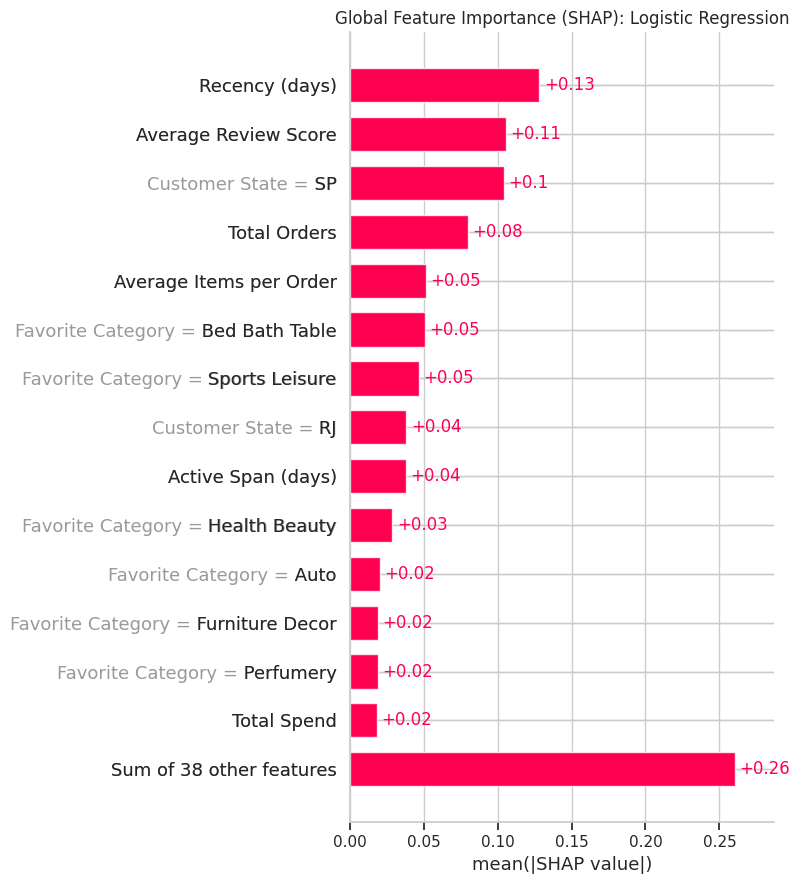

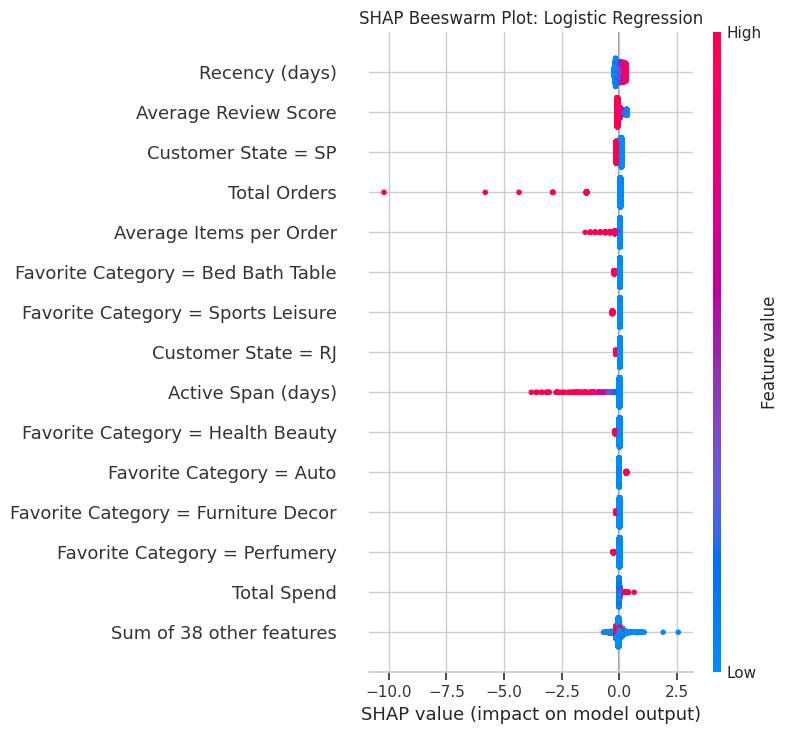


SHAP by business feature:


,business_feature,mean_abs_shap,mean_signed_shap,average_direction
0,Favorite Category,0.166330,0.015335,Net push toward churn
1,Recency,0.127267,0.028876,Net push toward churn
2,Average Review Score,0.106378,0.009630,Net push toward churn
3,Customer State,0.089994,-0.001016,Net push toward active
4,Total Orders,0.074155,0.011918,Net push toward churn
5,Average Items per Order,0.052413,-0.002977,Net push toward active
6,Active Span,0.035946,-0.019624,Net push toward active
7,Total Spend,0.018154,-0.001358,Net push toward active
8,Single Order Customer,0.014277,-0.002353,Net push toward active
9,Payment Method,0.013837,-0.000118,Net push toward active


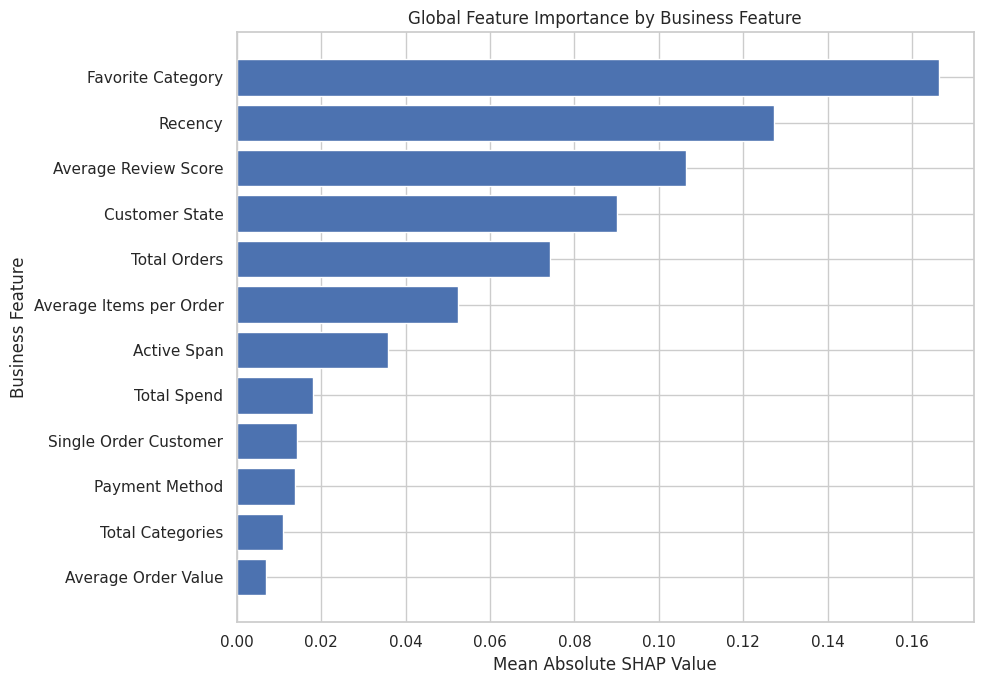


Example SHAP explanations per customer:


,customer_unique_id,shap_explained_model,top_churn_driver_1,top_churn_driver_1_value,top_churn_driver_2,top_churn_driver_2_value,top_churn_driver_3,top_churn_driver_3_value,top_protective_factor,top_protective_value
0,0000366f3b9a7992bf8c76cfdf3221e2,Logistic Regression,Total Orders,0.043925,Average Items per Order,0.027498,Active Span,0.008365,Favorite Category,-0.195709
1,0000b849f77a49e4a4ce2b2a4ca5be3f,Logistic Regression,Total Orders,0.043925,Average Items per Order,0.027498,Average Review Score,0.015799,Recency,-0.156742
2,0004bd2a26a76fe21f786e4fbd80607f,Logistic Regression,Favorite Category,0.071402,Total Orders,0.043925,Average Items per Order,0.027498,Customer State,-0.092803
3,00050ab1314c0e55a6ca13cf7181fecf,Logistic Regression,Total Orders,0.043925,Average Items per Order,0.027498,Favorite Category,0.026783,Recency,-0.107949
4,00053a61a98854899e70ed204dd4bafe,Logistic Regression,Average Review Score,0.319625,Customer State,0.099874,Total Orders,0.043925,Favorite Category,-0.270077
5,0005ef4cd20d2893f0d9fbd94d3c0d97,Logistic Regression,Average Review Score,0.319625,Customer State,0.079469,Total Orders,0.043925,Favorite Category,-0.270077
6,00090324bbad0e9342388303bb71ba0a,Logistic Regression,Total Orders,0.043925,Average Items per Order,0.027498,Active Span,0.008365,Favorite Category,-0.195709
7,000949456b182f53c18b68d6babc79c1,Logistic Regression,Total Orders,0.043925,Average Items per Order,0.027498,Payment Method,0.019264,Recency,-0.116559
8,000c8bdb58a29e7115cfc257230fb21b,Logistic Regression,Recency,0.262308,Total Orders,0.043925,Customer State,0.032265,Favorite Category,-0.195709
9,000d460961d6dbfa3ec6c9f5805769e1,Logistic Regression,Recency,0.187683,Total Orders,0.043925,Average Items per Order,0.027498,Customer State,-0.092803



Example customers for individual explanations:


,Example,customer_unique_id,churn_risk_score,actual_status
0,Highest Risk Score,b90f1d3b98edcabd42c810c0cfcf0424,0.844664,Churn
1,Typical Correctly Detected Active,6dcf48fcc0c4d96dd7af8a0897ae9de8,0.378734,Active


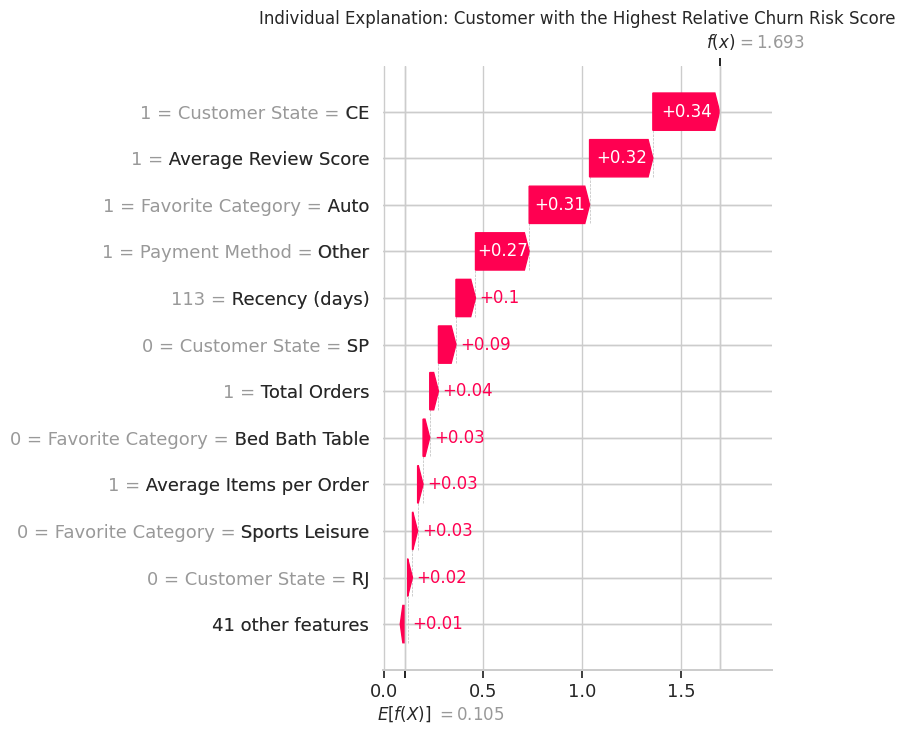

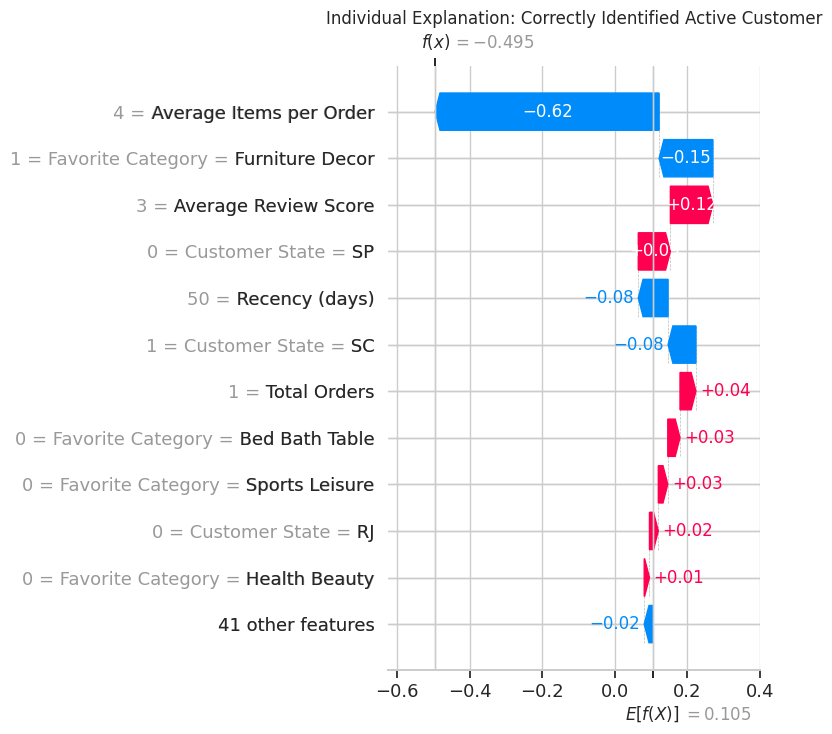


EXPLAINABLE AI SUMMARY
Explained model: Logistic Regression
Most important SHAP business feature: Favorite Category
Note: SHAP values explain model behavior and are not evidence of cause and effect.


In [ ]:
import importlib.util
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

# ============================================================
# 1. INSTALL DAN IMPORT SHAP
# ============================================================

if importlib.util.find_spec("shap") is None:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "shap"
    ])

import shap

print("SHAP version:", shap.__version__)

# ============================================================
# 2. MENGAMBIL MODEL TERBAIK HASIL VALIDATION
# ============================================================

# SHAP menjelaskan model yang sama dengan model terpilih.
if best_model_name not in trained_models:
    raise ValueError(
        f"Selected model {best_model_name} is not in trained_models; "
        "SHAP must explain the same model that was selected."
    )

explained_model_name = best_model_name

explained_pipeline = trained_models[
    explained_model_name
]

explained_preprocessor = explained_pipeline.named_steps[
    "preprocessor"
]

explained_classifier = explained_pipeline.named_steps[
    "classifier"
]

print("\nModel to be explained:")
print(explained_model_name)

print("\nClassifier type:")
print(type(explained_classifier).__name__)

# ============================================================
# 3. NAMA FITUR SETELAH PREPROCESSING
# ============================================================

transformed_feature_names = (
    explained_preprocessor.get_feature_names_out()
)

def readable_feature_name(feature_name):
    raw_name = feature_name.split("__", 1)[-1]

    numeric_labels = {
        "recency_days": "Recency (days)",
        "total_orders": "Total Orders",
        "total_spend": "Total Spend",
        "average_order_value": "Average Order Value",
        "avg_days_between_orders": "Average Days Between Orders",
        "single_order_flag": "Single Order Customer",
        "avg_review_score": "Average Review Score",
        "total_reviews": "Total Reviews",
        "average_items_per_order": "Average Items per Order",
        "total_categories": "Total Categories",
        "customer_tenure_days": "Customer Tenure (days)",
        "active_span_days": "Active Span (days)"
    }

    if raw_name in numeric_labels:
        return numeric_labels[raw_name]

    prefixes = {
        "favorite_category_": "Favorite Category = ",
        "payment_method_": "Payment Method = ",
        "customer_state_": "Customer State = "
    }

    for prefix, label in prefixes.items():
        if raw_name.startswith(prefix):
            category_value = raw_name[
                len(prefix):
            ]
            return (
                label
                + category_value
                .replace("_", " ")
                .title()
            )

    return raw_name.replace("_", " ").title()

def business_feature_group(feature_name):
    raw_name = feature_name.split("__", 1)[-1]

    if raw_name.startswith("favorite_category_"):
        return "Favorite Category"

    if raw_name.startswith("payment_method_"):
        return "Payment Method"

    if raw_name.startswith("customer_state_"):
        return "Customer State"

    feature_labels = {
        "recency_days": "Recency",
        "total_orders": "Total Orders",
        "total_spend": "Total Spend",
        "average_order_value": "Average Order Value",
        "avg_days_between_orders": "Average Days Between Orders",
        "single_order_flag": "Single Order Customer",
        "avg_review_score": "Average Review Score",
        "total_reviews": "Total Reviews",
        "average_items_per_order": "Average Items per Order",
        "total_categories": "Total Categories",
        "customer_tenure_days": "Customer Tenure",
        "active_span_days": "Active Span"
    }

    return feature_labels.get(
        raw_name,
        raw_name.replace("_", " ").title()
    )

readable_feature_names = [
    readable_feature_name(feature_name)
    for feature_name in transformed_feature_names
]

feature_groups = [
    business_feature_group(feature_name)
    for feature_name in transformed_feature_names
]

feature_name_table = pd.DataFrame({
    "Original Feature": transformed_feature_names,
    "Readable Feature": readable_feature_names,
    "Business Group": feature_groups
})

print("\nExample feature names after preprocessing:")
display(
    feature_name_table.head(20)
)

# ============================================================
# 4. TRANSFORMASI DATA UNTUK SHAP
# ============================================================

rng_shap = np.random.default_rng(SEED)

background_size = min(
    500,
    len(X_calibration_raw)
)

background_index = rng_shap.choice(
    len(X_calibration_raw),
    size=background_size,
    replace=False
)

X_background = explained_preprocessor.transform(
    X_calibration_raw.iloc[
        background_index
    ]
)

X_holdout_explain = explained_preprocessor.transform(
    X_holdout_raw
)

X_background_dataframe = pd.DataFrame(
    X_background,
    columns=readable_feature_names
)

X_holdout_explain_dataframe = pd.DataFrame(
    X_holdout_explain,
    columns=readable_feature_names
)

print("\nNumber of SHAP background samples:", len(X_background_dataframe))
print("Number of holdout customers:", len(X_holdout_explain_dataframe))
print("Number of features:", X_holdout_explain_dataframe.shape[1])

# ============================================================
# 5. MEMILIH SHAP EXPLAINER
# ============================================================

if isinstance(
    explained_classifier,
    LogisticRegression
):
    shap_explainer_type = "LinearExplainer"
    background_masker = shap.maskers.Independent(
        X_background_dataframe,
        max_samples=background_size
    )
    shap_explainer = shap.LinearExplainer(
        explained_classifier,
        background_masker
    )
    raw_shap_explanation = shap_explainer(
        X_holdout_explain_dataframe
    )
    shap_values_array = np.asarray(
        raw_shap_explanation.values
    )
    shap_base_values = np.asarray(
        raw_shap_explanation.base_values
    )
elif isinstance(
    explained_classifier,
    (
        RandomForestClassifier,
        HistGradientBoostingClassifier
    )
):
    shap_explainer_type = "TreeExplainer"
    shap_explainer = shap.TreeExplainer(
        explained_classifier
    )
    raw_shap_explanation = shap_explainer(
        X_holdout_explain_dataframe
    )
    shap_values_array = np.asarray(
        raw_shap_explanation.values
    )
    shap_base_values = np.asarray(
        raw_shap_explanation.base_values
    )
    if shap_values_array.ndim == 3:
        if shap_values_array.shape[-1] == 2:
            shap_values_array = (
                shap_values_array[:, :, 1]
            )
        elif shap_values_array.shape[0] == 2:
            shap_values_array = (
                shap_values_array[1]
            )
    if shap_base_values.ndim == 2:
        if shap_base_values.shape[-1] == 2:
            shap_base_values = (
                shap_base_values[:, 1]
            )
else:
    raise ValueError(
        "Model type not supported by the SHAP cell: "
        + type(explained_classifier).__name__
    )

if shap_values_array.ndim != 2:
    raise ValueError(
        "Unexpected SHAP value dimensions: "
        + str(shap_values_array.shape)
    )

if shap_base_values.ndim == 0:
    shap_base_values = np.repeat(
        shap_base_values,
        len(X_holdout_explain_dataframe)
    )

# Feature names used in plots only: infrequent categories are shown as
# "Other" and Brazilian state codes in upper case. Saved CSV files keep
# readable_feature_names unchanged.
def plot_feature_name(name):
    name = name.replace("Infrequent Sklearn", "Other")
    prefix = "Customer State = "
    if name.startswith(prefix):
        name = prefix + name[len(prefix):].upper()
    return name

plot_feature_names = [
    plot_feature_name(name)
    for name in readable_feature_names
]

shap_explanation = shap.Explanation(
    values=shap_values_array,
    base_values=shap_base_values,
    data=X_holdout_explain_dataframe.to_numpy(),
    feature_names=plot_feature_names
)

print("\nExplained model:", explained_model_name)
print("SHAP explainer type:", shap_explainer_type)
print(
    "Number of customers explained:",
    f"{len(shap_explanation):,}"
)
print(
    "Number of features after preprocessing:",
    shap_values_array.shape[1]
)

# ============================================================
# 6. GLOBAL SHAP — DETAIL FITUR
# ============================================================

shap_global_detailed = pd.DataFrame({
    "feature": readable_feature_names,
    "original_transformed_feature": (
        transformed_feature_names
    ),
    "business_group": feature_groups,
    "mean_abs_shap": np.abs(
        shap_values_array
    ).mean(axis=0),
    "mean_signed_shap": (
        shap_values_array.mean(axis=0)
    )
})

shap_global_detailed = (
    shap_global_detailed
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_global_detailed[
    "average_direction"
] = np.where(
    shap_global_detailed[
        "mean_signed_shap"
    ] >= 0,
    "Secara neto mendorong prediksi Churn",
    "Secara neto menahan prediksi Churn"
)

shap_global_detailed.to_csv(
    OUTPUT_DIR / "shap_global_importance_detailed.csv",
    index=False
)

print("\nTop 15 SHAP features:")
display(
    english_view(
        shap_global_detailed
        .head(15)
        .round(6)
    )
)

# ============================================================
# 7. GLOBAL SHAP BAR PLOT
# ============================================================

plot_sample_size = min(
    5000,
    len(shap_explanation)
)

plot_index = rng_shap.choice(
    len(shap_explanation),
    size=plot_sample_size,
    replace=False
)

shap_plot_sample = shap_explanation[
    plot_index
]

shap.plots.bar(
    shap_plot_sample,
    max_display=15,
    show=False
)

plt.title(
    f"Global Feature Importance (SHAP): {explained_model_name}"
)
plt.tight_layout()
plt.savefig(
    FIG_DIR / "shap_global_bar.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# 8. SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    shap_plot_sample,
    max_display=15,
    show=False
)

plt.title(
    f"SHAP Beeswarm Plot: {explained_model_name}"
)
plt.tight_layout()
plt.savefig(
    FIG_DIR / "shap_beeswarm.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# 9. SHAP BERDASARKAN KELOMPOK FITUR BISNIS
# ============================================================

business_group_names = list(
    dict.fromkeys(feature_groups)
)

feature_groups_array = np.asarray(
    feature_groups
)

grouped_shap_values = np.column_stack([
    shap_values_array[
        :,
        feature_groups_array == group_name
    ].sum(axis=1)
    for group_name in business_group_names
])

shap_global_grouped = pd.DataFrame({
    "business_feature": business_group_names,
    "mean_abs_shap": np.abs(
        grouped_shap_values
    ).mean(axis=0),
    "mean_signed_shap": (
        grouped_shap_values.mean(axis=0)
    )
})

shap_global_grouped = (
    shap_global_grouped
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_global_grouped[
    "average_direction"
] = np.where(
    shap_global_grouped[
        "mean_signed_shap"
    ] >= 0,
    "Secara neto mendorong prediksi Churn",
    "Secara neto menahan prediksi Churn"
)

shap_global_grouped.to_csv(
    OUTPUT_DIR / "shap_global_importance_grouped.csv",
    index=False
)

print("\nSHAP by business feature:")
display(
    english_view(shap_global_grouped.round(6))
)

top_grouped_shap = (
    shap_global_grouped
    .head(12)
    .sort_values("mean_abs_shap")
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_grouped_shap["business_feature"],
    top_grouped_shap["mean_abs_shap"],
    color="#4C72B0"
)
plt.title(
    "Global Feature Importance by Business Feature"
)
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Business Feature")
plt.tight_layout()
plt.savefig(
    FIG_DIR / "shap_grouped_business_features.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# 10. SHAP DRIVER SETIAP CUSTOMER
# ============================================================

row_numbers = np.arange(
    len(grouped_shap_values)
)

top_positive_index = np.argsort(
    -grouped_shap_values,
    axis=1
)[:, :3]

top_protective_index = np.argmin(
    grouped_shap_values,
    axis=1
)

customer_shap_drivers = holdout[
    ["customer_unique_id"]
].copy()

customer_shap_drivers[
    "shap_explained_model"
] = explained_model_name

for rank_number in range(3):
    selected_index = top_positive_index[
        :,
        rank_number
    ]
    selected_values = grouped_shap_values[
        row_numbers,
        selected_index
    ]
    customer_shap_drivers[
        f"top_churn_driver_{rank_number + 1}"
    ] = [
        (
            business_group_names[index]
            if value > 0
            else "Tidak ada pendorong positif"
        )
        for index, value in zip(
            selected_index,
            selected_values
        )
    ]
    customer_shap_drivers[
        f"top_churn_driver_{rank_number + 1}_value"
    ] = selected_values

top_protective_values = grouped_shap_values[
    row_numbers,
    top_protective_index
]

customer_shap_drivers[
    "top_protective_factor"
] = [
    (
        business_group_names[index]
        if value < 0
        else "Tidak ada faktor pelindung"
    )
    for index, value in zip(
        top_protective_index,
        top_protective_values
    )
]

customer_shap_drivers[
    "top_protective_value"
] = top_protective_values

customer_shap_drivers.to_csv(
    OUTPUT_DIR / "shap_customer_explanations.csv",
    index=False
)

print("\nExample SHAP explanations per customer:")
display(
    english_view(
        customer_shap_drivers
        .head(10)
        .round(6)
    )
)

# ============================================================
# 11. LOCAL SHAP EXPLANATION
# ============================================================

selected_probability = model_probabilities[
    explained_model_name
]

selected_threshold_local = model_thresholds[
    explained_model_name
]

# Waterfall menampilkan nilai asli fitur numerik,
# bukan nilai hasil standardisasi.
number_of_numeric = len(numeric_features)

assert all(
    name.startswith("numeric__")
    for name in transformed_feature_names[:number_of_numeric]
), "Numerical feature order does not match."

display_matrix = (
    X_holdout_explain_dataframe
    .to_numpy(dtype=float)
    .copy()
)

display_matrix[:, :number_of_numeric] = np.round(
    X_holdout_raw[numeric_features].to_numpy(dtype=float),
    2
)

shap_explanation_display = shap.Explanation(
    values=shap_values_array,
    base_values=shap_base_values,
    data=display_matrix,
    feature_names=plot_feature_names
)

# (a) Customer dengan risk score tertinggi.
highest_risk_position = int(
    np.argmax(selected_probability)
)

# (b) Customer Active yang terdeteksi benar dengan skor paling
#     tipikal (paling dekat dengan median skor kelompoknya).
correct_active_positions = np.where(
    (y_holdout == 0)
    & (selected_probability < selected_threshold_local)
)[0]

if len(correct_active_positions) == 0:
    raise ValueError(
        "No correctly identified active customer was found."
    )

typical_active_position = int(
    correct_active_positions[
        np.argmin(
            np.abs(
                selected_probability[correct_active_positions]
                - np.median(
                    selected_probability[correct_active_positions]
                )
            )
        )
    ]
)

# Variabel lama dipertahankan agar kode setelahnya tetap kompatibel.
lowest_risk_position = typical_active_position

local_example_table = pd.DataFrame({
    "Example": [
        "Highest Risk Score",
        "Typical Correctly Detected Active"
    ],
    "customer_unique_id": [
        holdout.iloc[highest_risk_position]["customer_unique_id"],
        holdout.iloc[typical_active_position]["customer_unique_id"]
    ],
    "churn_risk_score": [
        selected_probability[highest_risk_position],
        selected_probability[typical_active_position]
    ],
    "actual_status": [
        "Churn" if y_holdout[highest_risk_position] == 1 else "Active",
        "Churn" if y_holdout[typical_active_position] == 1 else "Active"
    ]
})

local_example_table.to_csv(
    OUTPUT_DIR / "shap_local_examples.csv",
    index=False
)

print("\nExample customers for individual explanations:")
display(
    local_example_table.round(6)
)

for position, title, filename in [
    (
        highest_risk_position,
        "Individual Explanation: Customer with the Highest Relative Churn Risk Score",
        "shap_waterfall_high_risk.png"
    ),
    (
        typical_active_position,
        "Individual Explanation: Correctly Identified Active Customer",
        "shap_waterfall_low_risk.png"
    )
]:
    shap.plots.waterfall(
        shap_explanation_display[position],
        max_display=12,
        show=False
    )
    plt.title(title)
    plt.tight_layout()
    plt.savefig(
        FIG_DIR / filename,
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()

# ============================================================

# 12. KESIMPULAN CELL 18
# ============================================================

print("\n" + "=" * 65)
print("EXPLAINABLE AI SUMMARY")
print("=" * 65)

print("Explained model:", explained_model_name)
print(
    "Most important SHAP business feature:",
    shap_global_grouped.iloc[
        0
    ]["business_feature"]
)
print(
    "Note: SHAP values explain model behavior "
    "and are not evidence of cause and effect."
)

## 19. Responsible AI evaluation dan model card

Tahap ini mendokumentasikan keandalan dan batas penggunaan model. Evaluasi
mencakup calibration, bootstrap confidence interval, dan pemeriksaan performa
berdasarkan state yang memiliki jumlah observasi memadai. Pemeriksaan state
bukan bukti fairness demografis karena Dataset Olist tidak menyediakan atribut
sensitif seperti gender atau ras.

Model hanya digunakan untuk **pendukung prioritas retensi**. Hasil probabilitas
dan SHAP tidak boleh digunakan sebagai keputusan otomatis yang merugikan
customer.


Evaluated model: Logistic Regression
Decision threshold: 0.44
Number of holdout observations: 38,838

Brier score before recalibration: 0.22446
Brier score after recalibration (Platt): 0.006679
Prevalence baseline Brier score: 0.006654

Calibration results:


,metric,value
0,Selected Model Brier Score,0.224460
1,Calibrated Brier Score (Platt),0.006679
2,Prevalence Baseline Brier Score,0.006654
3,Active Prevalence / PR-AUC Baseline,0.006694
4,Selected Model PR-AUC Active,0.019521
5,PR-AUC Active Improvement over Baseline,2.916052



Calibration interpretation:
The model is not well calibrated. The raw Brier score (0.2245) and the Brier score after Platt scaling (0.0067) are not lower than the baseline (0.0067).
Model output is used as a relative churn risk score, not as an absolute probability that a customer will churn.

Calibration curve table:


,mean_predicted_probability,observed_churn_rate
0,0.343672,0.981720
1,0.451998,0.991761
2,0.484419,0.996395
3,0.509167,0.993304
4,0.531195,0.995366
5,0.552310,0.995366
6,0.574733,0.994592
7,0.599732,0.992533
8,0.630120,0.995881
9,0.685331,0.996138


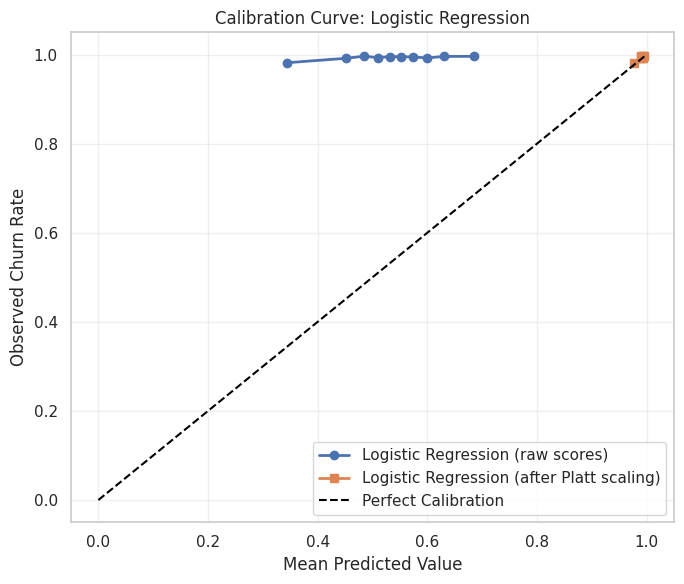


Bootstrap 95% Confidence Interval (300 successful resamples):


,metric,mean,ci_2_5_percent,ci_97_5_percent
0,roc_auc,0.613350,0.575417,0.650613
1,pr_auc_active,0.021476,0.013010,0.033301
2,balanced_accuracy,0.588374,0.554806,0.617795
3,mcc,0.044427,0.027207,0.059428



Geographic Performance Audit by customer_state:


,customer_state,total_customers,active_customers,churn_customers,balanced_accuracy,recall_active,roc_auc,pr_auc_active
0,SP,16625,133,16492,0.5980,0.3759,0.6121,0.0232
1,RJ,4843,31,4812,0.6031,0.3226,0.5410,0.0291
2,MG,4595,22,4573,0.5945,0.2727,0.5451,0.0089
3,RS,2063,7,2056,0.6754,0.4286,0.7280,0.0826
4,PR,1989,13,1976,0.5478,0.1538,0.5030,0.0150
5,SC,1456,12,1444,0.5886,0.2500,0.7329,0.0241
6,BA,1289,9,1280,0.5391,0.1111,0.7905,0.0361
7,DF,845,7,838,0.4851,0.0000,0.4870,0.0125
8,GO,810,7,803,0.4751,0.0000,0.7870,0.0325
9,ES,789,5,784,0.4802,0.0000,0.5663,0.0082



Responsible AI Evaluation Summary:


,Indicator,Value
0,Selected Model,Logistic Regression
1,Decision Threshold,0.44
2,Balanced Accuracy Holdout,0.588807
3,ROC-AUC Holdout,0.613596
4,PR-AUC Active Holdout,0.019521
5,Recall Active Holdout,0.296154
6,MCC Holdout,0.044614
7,Brier Score Model,0.22446
8,Calibrated Brier Score (Platt),0.006679
9,Brier Score Baseline,0.006654



Responsible AI Model Card:


,Component,Description
0,Model,Logistic Regression
1,Intended Use,Supporting the prioritization of customer rete...
2,Target Definition,A customer is labeled as churned if no purchas...
3,Selection Criterion,Selected by the highest active-class PR-AUC on...
4,Decision Threshold,0.44
5,Explainability,Global and individual explanations based on SHAP.
6,Reliability Evaluation,"Evaluated with a time-based holdout set, calib..."
7,Privacy,Uses the anonymized customer_unique_id and per...
8,Human Oversight,Final retention decisions must be reviewed by ...
9,Prohibited Use,Not to be used for automated decisions that re...



RESPONSIBLE AI EVALUATION SUMMARY
Model: Logistic Regression
ROC-AUC holdout: 0.6136
Balanced Accuracy holdout: 0.5888
PR-AUC Active holdout: 0.0195
Active-class PR-AUC relative to baseline: 2.92 times
Brier score raw / after Platt / baseline: 0.2245 / 0.0067 / 0.0067
The model is not well calibrated. The raw Brier score (0.2245) and the Brier score after Platt scaling (0.0067) are not lower than the baseline (0.0067).
Model output is used as a relative churn risk score to support retention prioritization, not as an automated decision.


In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    brier_score_loss,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score,
    matthews_corrcoef,
    recall_score
)

from sklearn.linear_model import LogisticRegression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. MENGAMBIL HASIL MODEL TERPILIH
# ============================================================

selected_probability = model_probabilities[
    best_model_name
]

selected_threshold = model_thresholds[
    best_model_name
]

selected_prediction = (
    selected_probability >= selected_threshold
).astype(int)

print("Evaluated model:", best_model_name)
print(
    "Decision threshold:",
    round(selected_threshold, 4)
)
print(
    "Number of holdout observations:",
    f"{len(y_holdout):,}"
)


# ============================================================
# 2. CALIBRATION DAN BRIER SCORE
# ============================================================

# Probabilitas baseline mengikuti proporsi kelas churn
# pada dataset calibration.
baseline_churn_probability = float(
    y_calibration.mean()
)

baseline_probability = np.repeat(
    baseline_churn_probability,
    len(y_holdout)
)

# Semakin kecil Brier Score, semakin baik kalibrasi model.
selected_brier_score = brier_score_loss(
    y_holdout,
    selected_probability
)

baseline_brier_score = brier_score_loss(
    y_holdout,
    baseline_probability
)

# Karena kelas Active adalah kelas minoritas,
# prevalensi Active menjadi baseline PR-AUC Active.
active_prevalence = float(
    (y_holdout == 0).mean()
)

selected_pr_auc_active = average_precision_score(
    1 - y_holdout,
    1 - selected_probability
)

pr_auc_improvement = (
    selected_pr_auc_active / active_prevalence
    if active_prevalence > 0
    else np.nan
)


# ============================================================
# 2b. REKALIBRASI SKOR (PLATT SCALING)
# ============================================================
# Kalibrator dipelajari dari probabilitas validation model terpilih
# (model yang dilatih pada development), lalu diterapkan ke holdout.
# Transformasinya monoton, sehingga urutan pelanggan, ROC-AUC,
# PR-AUC, dan prediksi pada threshold keputusan tidak berubah.

def to_logit(probability):
    probability = np.clip(
        np.asarray(probability, dtype=float),
        1e-6,
        1 - 1e-6
    )
    return np.log(
        probability / (1 - probability)
    ).reshape(-1, 1)


platt_calibrator = LogisticRegression(
    C=1e6,
    max_iter=1000
)

platt_calibrator.fit(
    to_logit(validation_probabilities[best_model_name]),
    y_validation
)

calibrated_probability = platt_calibrator.predict_proba(
    to_logit(selected_probability)
)[:, 1]

calibrated_brier_score = brier_score_loss(
    y_holdout,
    calibrated_probability
)

print(
    "\nBrier score before recalibration:",
    round(selected_brier_score, 6)
)
print(
    "Brier score after recalibration (Platt):",
    round(calibrated_brier_score, 6)
)
print(
    "Prevalence baseline Brier score:",
    round(baseline_brier_score, 6)
)


calibration_metrics = pd.DataFrame({
    "metric": [
        "Selected Model Brier Score",
        "Calibrated Brier Score (Platt)",
        "Prevalence Baseline Brier Score",
        "Active Prevalence / PR-AUC Baseline",
        "Selected Model PR-AUC Active",
        "PR-AUC Active Improvement over Baseline"
    ],
    "value": [
        selected_brier_score,
        calibrated_brier_score,
        baseline_brier_score,
        active_prevalence,
        selected_pr_auc_active,
        pr_auc_improvement
    ]
})

calibration_metrics.to_csv(
    OUTPUT_DIR / "calibration_metrics.csv",
    index=False
)

print("\nCalibration results:")

display(
    calibration_metrics.round(6)
)


# ============================================================
# 3. INTERPRETASI HASIL CALIBRATION
# ============================================================

if calibrated_brier_score < baseline_brier_score:

    calibration_status = (
        f"Skor mentah belum terkalibrasi (Brier {selected_brier_score:.4f} "
        f"vs baseline {baseline_brier_score:.4f}). Setelah Platt scaling, "
        f"Brier turun menjadi {calibrated_brier_score:.4f}, lebih rendah "
        "daripada baseline."
    )

    score_interpretation = (
        "churn_risk_score digunakan sebagai relative churn risk score "
        "untuk mengurutkan prioritas; calibrated_churn_probability dapat "
        "dibaca sebagai estimasi probabilitas churn, tetap dengan hati-hati."
    )

elif selected_brier_score < baseline_brier_score:

    calibration_status = (
        "Model memiliki Brier Score lebih rendah daripada baseline."
    )

    score_interpretation = (
        "Nilai model dapat digunakan sebagai probabilitas prediksi, "
        "tetapi tetap harus diinterpretasikan secara hati-hati."
    )

else:

    calibration_status = (
        f"Model belum terkalibrasi dengan baik. Brier mentah "
        f"{selected_brier_score:.4f} dan setelah Platt scaling "
        f"{calibrated_brier_score:.4f} belum lebih rendah daripada "
        f"baseline {baseline_brier_score:.4f}."
    )

    score_interpretation = (
        "Nilai prediksi digunakan sebagai relative churn risk score, "
        "bukan probabilitas absolut pelanggan akan churn."
    )

# English versions for on-screen display (saved files keep the original text).
if calibrated_brier_score < baseline_brier_score:
    calibration_status_en = (
        f"Raw scores are not well calibrated (Brier {selected_brier_score:.4f} "
        f"vs baseline {baseline_brier_score:.4f}). After Platt scaling, "
        f"the Brier score fell to {calibrated_brier_score:.4f}, below the baseline."
    )
    score_interpretation_en = (
        "churn_risk_score is used as a relative churn risk score for ranking "
        "priorities; calibrated_churn_probability can be read as an estimated "
        "churn probability, with caution."
    )
elif selected_brier_score < baseline_brier_score:
    calibration_status_en = (
        "The model has a lower Brier score than the baseline."
    )
    score_interpretation_en = (
        "Model scores can be used as predicted probabilities, "
        "but should still be interpreted with caution."
    )
else:
    calibration_status_en = (
        f"The model is not well calibrated. The raw Brier score "
        f"({selected_brier_score:.4f}) and the Brier score after Platt scaling "
        f"({calibrated_brier_score:.4f}) are not lower than the "
        f"baseline ({baseline_brier_score:.4f})."
    )
    score_interpretation_en = (
        "Model output is used as a relative churn risk score, "
        "not as an absolute probability that a customer will churn."
    )

DISPLAY_EN[calibration_status] = calibration_status_en
DISPLAY_EN[score_interpretation] = score_interpretation_en

print("\nCalibration interpretation:")
print(calibration_status_en)
print(score_interpretation_en)


# ============================================================
# 4. CALIBRATION CURVE
# ============================================================

fraction_of_positives, mean_predicted_value = (
    calibration_curve(
        y_holdout,
        selected_probability,
        n_bins=10,
        strategy="quantile"
    )
)

calibration_curve_dataframe = pd.DataFrame({
    "mean_predicted_probability": (
        mean_predicted_value
    ),
    "observed_churn_rate": (
        fraction_of_positives
    )
})

calibration_curve_dataframe.to_csv(
    OUTPUT_DIR / "calibration_curve.csv",
    index=False
)

calibrated_fraction, calibrated_mean_predicted = (
    calibration_curve(
        y_holdout,
        calibrated_probability,
        n_bins=10,
        strategy="quantile"
    )
)

calibrated_curve_dataframe = pd.DataFrame({
    "mean_predicted_probability": calibrated_mean_predicted,
    "observed_churn_rate": calibrated_fraction
})

calibrated_curve_dataframe.to_csv(
    OUTPUT_DIR / "calibration_curve_after_platt.csv",
    index=False
)

print("\nCalibration curve table:")

display(
    calibration_curve_dataframe.round(6)
)


plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    linewidth=2,
    label=f"{best_model_name} (raw scores)"
)

plt.plot(
    calibrated_mean_predicted,
    calibrated_fraction,
    marker="s",
    linewidth=2,
    label=f"{best_model_name} (after Platt scaling)"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Value")
plt.ylabel("Observed Churn Rate")
plt.title(
    f"Calibration Curve: {best_model_name}"
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "calibration_curve.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 5. BOOTSTRAP CONFIDENCE INTERVAL
# ============================================================

bootstrap_rng = np.random.default_rng(SEED)

bootstrap_results = []

number_bootstrap = 300

for bootstrap_number in range(number_bootstrap):

    sample_index = bootstrap_rng.choice(
        len(y_holdout),
        size=len(y_holdout),
        replace=True
    )

    sample_actual = y_holdout[
        sample_index
    ]

    sample_probability = selected_probability[
        sample_index
    ]

    sample_prediction = selected_prediction[
        sample_index
    ]

    # ROC-AUC tidak bisa dihitung jika hanya terdapat
    # satu kelas dalam sampel bootstrap.
    if len(np.unique(sample_actual)) < 2:
        continue

    bootstrap_results.append({
        "roc_auc": roc_auc_score(
            sample_actual,
            sample_probability
        ),
        "pr_auc_active": average_precision_score(
            1 - sample_actual,
            1 - sample_probability
        ),
        "balanced_accuracy": (
            balanced_accuracy_score(
                sample_actual,
                sample_prediction
            )
        ),
        "mcc": matthews_corrcoef(
            sample_actual,
            sample_prediction
        )
    })


bootstrap_dataframe = pd.DataFrame(
    bootstrap_results
)

bootstrap_summary_rows = []

for metric_name in bootstrap_dataframe.columns:

    bootstrap_summary_rows.append({
        "metric": metric_name,
        "mean": bootstrap_dataframe[
            metric_name
        ].mean(),
        "ci_2_5_percent": bootstrap_dataframe[
            metric_name
        ].quantile(0.025),
        "ci_97_5_percent": bootstrap_dataframe[
            metric_name
        ].quantile(0.975)
    })


bootstrap_confidence_intervals = pd.DataFrame(
    bootstrap_summary_rows
)

bootstrap_confidence_intervals.to_csv(
    OUTPUT_DIR / "bootstrap_confidence_intervals.csv",
    index=False
)

print(
    "\nBootstrap 95% Confidence Interval "
    f"({len(bootstrap_dataframe)} successful resamples):"
)

display(
    bootstrap_confidence_intervals.round(6)
)


# ============================================================
# 6. AUDIT PERFORMA BERDASARKAN CUSTOMER STATE
# ============================================================

geographic_audit_rows = []

for state_name, state_index in (
    holdout
    .groupby("customer_state")
    .groups
    .items()
):

    state_index = np.asarray(
        list(state_index),
        dtype=int
    )

    state_actual = y_holdout[
        state_index
    ]

    # State hanya dianalisis jika mempunyai minimal:
    # - 500 pelanggan;
    # - 5 pelanggan Active.
    #
    # Hal ini dilakukan agar metrik tidak terlalu labil.
    if (
        len(state_index) < 500
        or (state_actual == 0).sum() < 5
    ):
        continue

    state_probability = selected_probability[
        state_index
    ]

    state_prediction = (
        state_probability >= selected_threshold
    ).astype(int)

    # Memastikan terdapat dua kelas.
    if len(np.unique(state_actual)) < 2:
        continue

    geographic_audit_rows.append({
        "customer_state": state_name,
        "total_customers": len(state_index),
        "active_customers": int(
            (state_actual == 0).sum()
        ),
        "churn_customers": int(
            (state_actual == 1).sum()
        ),
        "balanced_accuracy": (
            balanced_accuracy_score(
                state_actual,
                state_prediction
            )
        ),
        "recall_active": recall_score(
            state_actual,
            state_prediction,
            pos_label=0,
            zero_division=0
        ),
        "roc_auc": roc_auc_score(
            state_actual,
            state_probability
        ),
        "pr_auc_active": (
            average_precision_score(
                1 - state_actual,
                1 - state_probability
            )
        )
    })


geographic_performance_audit = pd.DataFrame(
    geographic_audit_rows
)

if not geographic_performance_audit.empty:

    geographic_performance_audit = (
        geographic_performance_audit
        .sort_values(
            "total_customers",
            ascending=False
        )
        .reset_index(drop=True)
    )

else:

    geographic_performance_audit = pd.DataFrame(
        columns=[
            "customer_state",
            "total_customers",
            "active_customers",
            "churn_customers",
            "balanced_accuracy",
            "recall_active",
            "roc_auc",
            "pr_auc_active"
        ]
    )


geographic_performance_audit.to_csv(
    OUTPUT_DIR / "geographic_performance_audit.csv",
    index=False
)

print("\nGeographic Performance Audit by customer_state:")

display(
    geographic_performance_audit.round(4)
)


# ============================================================
# 7. RINGKASAN HASIL MODEL TERPILIH
# ============================================================

selected_result_row = metrics_dataframe[
    metrics_dataframe["model"] == best_model_name
].iloc[0]

responsible_ai_summary = pd.DataFrame({
    "Indicator": [
        "Selected Model",
        "Decision Threshold",
        "Balanced Accuracy Holdout",
        "ROC-AUC Holdout",
        "PR-AUC Active Holdout",
        "Recall Active Holdout",
        "MCC Holdout",
        "Brier Score Model",
        "Calibrated Brier Score (Platt)",
        "Brier Score Baseline",
        "Calibration Status"
    ],
    "Value": [
        best_model_name,
        selected_threshold,
        selected_result_row[
            "balanced_accuracy"
        ],
        selected_result_row[
            "roc_auc"
        ],
        selected_result_row[
            "pr_auc_active"
        ],
        selected_result_row[
            "recall_active"
        ],
        selected_result_row[
            "mcc"
        ],
        selected_brier_score,
        calibrated_brier_score,
        baseline_brier_score,
        calibration_status
    ]
})

responsible_ai_summary.to_csv(
    OUTPUT_DIR / "responsible_ai_summary.csv",
    index=False
)

print("\nResponsible AI Evaluation Summary:")

display(
    english_view(responsible_ai_summary.round(6))
)


# ============================================================
# 8. RESPONSIBLE AI MODEL CARD
# ============================================================

responsible_ai_model_card = pd.DataFrame({
    "Component": [
        "Model",
        "Intended Use",
        "Target Definition",
        "Selection Criterion",
        "Decision Threshold",
        "Explainability",
        "Reliability Evaluation",
        "Privacy",
        "Human Oversight",
        "Prohibited Use",
        "Main Limitation",
        "Causality Warning"
    ],
    "Description": [
        best_model_name,

        (
            "Pendukung penentuan prioritas program "
            "retensi pelanggan."
        ),

        (
            "Pelanggan dianggap churn apabila tidak melakukan "
            "pembelian kembali dalam 90 hari setelah cutoff."
        ),

        (
            "Model dipilih berdasarkan PR-AUC kelas Active "
            "tertinggi pada validation set di antara model yang "
            "dapat dijelaskan langsung (LR, RF, HGB); Keras MLP "
            "dilaporkan sebagai pembanding."
        ),

        str(round(selected_threshold, 4)),

        (
            "Menggunakan global dan local explanation "
            "berbasis SHAP."
        ),

        (
            "Dievaluasi menggunakan time-based holdout, "
            "calibration, bootstrap confidence interval, "
            "dan geographic performance audit; skor "
            "direkalibrasi dengan Platt scaling dari validation set."
        ),

        (
            "Menggunakan customer_unique_id yang telah "
            "dianonimkan dan tidak melakukan re-identification."
        ),

        (
            "Keputusan retensi akhir harus ditinjau "
            "oleh manusia."
        ),

        (
            "Model tidak digunakan untuk keputusan otomatis "
            "yang menolak, mengeluarkan, atau memberikan "
            "perlakuan merugikan kepada pelanggan."
        ),

        (
            "Dataset memiliki class imbalance ekstrem dan "
            "jumlah pelanggan repeat order yang sangat rendah."
        ),

        (
            "SHAP menjelaskan perilaku model dan tidak "
            "membuktikan hubungan sebab-akibat."
        )
    ]
})


# ============================================================
# 9. MENAMBAHKAN INFORMASI KALIBRASI KE MODEL CARD
# ============================================================

additional_model_card = pd.DataFrame({
    "Component": [
        "Probability Calibration",
        "Score Interpretation"
    ],
    "Description": [
        calibration_status,

        score_interpretation
    ]
})


responsible_ai_model_card = pd.concat(
    [
        responsible_ai_model_card,
        additional_model_card
    ],
    ignore_index=True
)


# ============================================================
# 10. MENYIMPAN MODEL CARD FINAL
# ============================================================

responsible_ai_model_card.to_csv(
    OUTPUT_DIR / "responsible_ai_model_card.csv",
    index=False
)

print("\nResponsible AI Model Card:")

model_card_english = [
    best_model_name,
    "Supporting the prioritization of customer retention programs.",
    "A customer is labeled as churned if no purchase is made within 90 days after the cutoff.",
    (
        "Selected by the highest active-class PR-AUC on the validation set among "
        "directly explainable models (LR, RF, HGB); the Keras MLP is reported as a benchmark."
    ),
    str(round(selected_threshold, 4)),
    "Global and individual explanations based on SHAP.",
    (
        "Evaluated with a time-based holdout set, calibration, bootstrap confidence "
        "intervals, and a geographic performance audit; scores were recalibrated with "
        "Platt scaling fitted on the validation set."
    ),
    "Uses the anonymized customer_unique_id and performs no re-identification.",
    "Final retention decisions must be reviewed by people.",
    (
        "Not to be used for automated decisions that reject, exclude, or "
        "disadvantage customers."
    ),
    "Extreme class imbalance and very few customers with repeat orders.",
    "SHAP explains model behavior and does not establish cause and effect.",
    calibration_status_en,
    score_interpretation_en
]

display(
    responsible_ai_model_card.assign(Description=model_card_english)
)


# ============================================================
# 11. KESIMPULAN OTOMATIS CELL 19
# ============================================================

print("\n" + "=" * 65)
print("RESPONSIBLE AI EVALUATION SUMMARY")
print("=" * 65)

print("Model:", best_model_name)

print(
    "ROC-AUC holdout:",
    round(
        selected_result_row["roc_auc"],
        4
    )
)

print(
    "Balanced Accuracy holdout:",
    round(
        selected_result_row[
            "balanced_accuracy"
        ],
        4
    )
)

print(
    "PR-AUC Active holdout:",
    round(
        selected_result_row[
            "pr_auc_active"
        ],
        4
    )
)

print(
    "Active-class PR-AUC relative to baseline:",
    round(pr_auc_improvement, 2),
    "times"
)

print(
    "Brier score raw / after Platt / baseline:",
    round(selected_brier_score, 4),
    "/",
    round(calibrated_brier_score, 4),
    "/",
    round(baseline_brier_score, 4)
)

print(calibration_status_en)

print(
    "Model output is used as a relative churn risk score "
    "to support retention prioritization, not as "
    "an automated decision."
)

## 20. Prediksi customer, SHAP drivers, relative risk, RFM, dan dashboard

Marketing Dashboard menggabungkan probabilitas churn, threshold keputusan,
relative risk, RFM, dan faktor utama hasil SHAP. Penjelasan digunakan sebagai
pendukung keputusan; keputusan retensi akhir tetap memerlukan human oversight

Dashboard model: Logistic Regression
Decision threshold: 0.44
Relative risk cut-points from validation: 0.511 and 0.5962
Note: model output is used as a relative churn risk score, not an absolute probability.

Sales KPI:


,Metric,Value
0,Total Orders,9.647800e+04
1,Total Customers,9.335800e+04
2,Product Revenue,1.322150e+07
3,Gross Order Value Including Freight,1.541977e+07
4,Average Order Value Including Freight,1.598268e+02
5,Average Review Score,4.156187e+00
6,Total Freight,2.198276e+06



Risk Segment Summary:


,risk_segment,total_customers,actual_churn_rate,average_churn_risk_score,average_total_spend
0,Relative High Risk,10143,0.9955,0.6454,203.3717
1,Relative Low Risk,13887,0.9906,0.4392,144.9462
2,Relative Medium Risk,14808,0.9943,0.5526,148.1442



RFM Segment Summary:


,rfm_segment,total_customers,actual_churn_rate,average_churn_risk_score,average_total_spend,average_orders
0,At-Risk Loyal,9,0.7778,0.0913,345.0389,3.2222
1,Big Spenders,3376,0.9935,0.5228,293.9768,1.1206
2,Champions,33,0.8788,0.0597,527.0067,3.1818
3,Lost / Hibernating,6335,0.9945,0.5749,54.9141,1.0000
4,New / Recent Customers,15313,0.9919,0.5019,166.0698,1.0000
5,Regular,13772,0.9947,0.5614,171.7627,1.0254



Marketing dashboard preview:


,customer_unique_id,recency_days,total_orders,total_spend,churn_risk_score,decision_threshold,churn_prediction,risk_segment,top_churn_driver_1,top_churn_driver_2,top_churn_driver_3,top_protective_factor,R_score,F_score,M_score,RFM_score,rfm_segment
0,0000366f3b9a7992bf8c76cfdf3221e2,21,1,141.90,0.406637,0.44,0,Relative Low Risk,Total Orders,Average Items per Order,Active Span,Favorite Category,5,1,4,514,New / Recent Customers
1,0000b849f77a49e4a4ce2b2a4ca5be3f,24,1,27.19,0.442159,0.44,1,Relative Low Risk,Total Orders,Average Items per Order,Average Review Score,Recency,5,1,1,511,New / Recent Customers
2,0004bd2a26a76fe21f786e4fbd80607f,56,1,166.98,0.524135,0.44,1,Relative Medium Risk,Favorite Category,Total Orders,Average Items per Order,Customer State,4,1,4,414,New / Recent Customers
3,00050ab1314c0e55a6ca13cf7181fecf,41,1,35.38,0.499765,0.44,1,Relative Low Risk,Total Orders,Average Items per Order,Favorite Category,Recency,4,1,1,411,New / Recent Customers
4,00053a61a98854899e70ed204dd4bafe,92,1,419.18,0.549092,0.44,1,Relative Medium Risk,Average Review Score,Customer State,Total Orders,Favorite Category,3,1,5,315,Big Spenders
5,0005ef4cd20d2893f0d9fbd94d3c0d97,80,1,129.76,0.572419,0.44,1,Relative Medium Risk,Average Review Score,Customer State,Total Orders,Favorite Category,3,1,3,313,Regular
6,00090324bbad0e9342388303bb71ba0a,68,1,63.66,0.435210,0.44,0,Relative Low Risk,Total Orders,Average Items per Order,Active Span,Favorite Category,4,1,2,412,New / Recent Customers
7,000949456b182f53c18b68d6babc79c1,38,1,82.05,0.483099,0.44,1,Relative Low Risk,Total Orders,Average Items per Order,Payment Method,Recency,4,1,2,412,New / Recent Customers
8,000c8bdb58a29e7115cfc257230fb21b,170,1,29.00,0.537278,0.44,1,Relative Medium Risk,Recency,Total Orders,Customer State,Favorite Category,1,1,1,111,Lost / Hibernating
9,000d460961d6dbfa3ec6c9f5805769e1,144,1,36.68,0.543371,0.44,1,Relative Medium Risk,Recency,Total Orders,Average Items per Order,Customer State,1,1,1,111,Lost / Hibernating


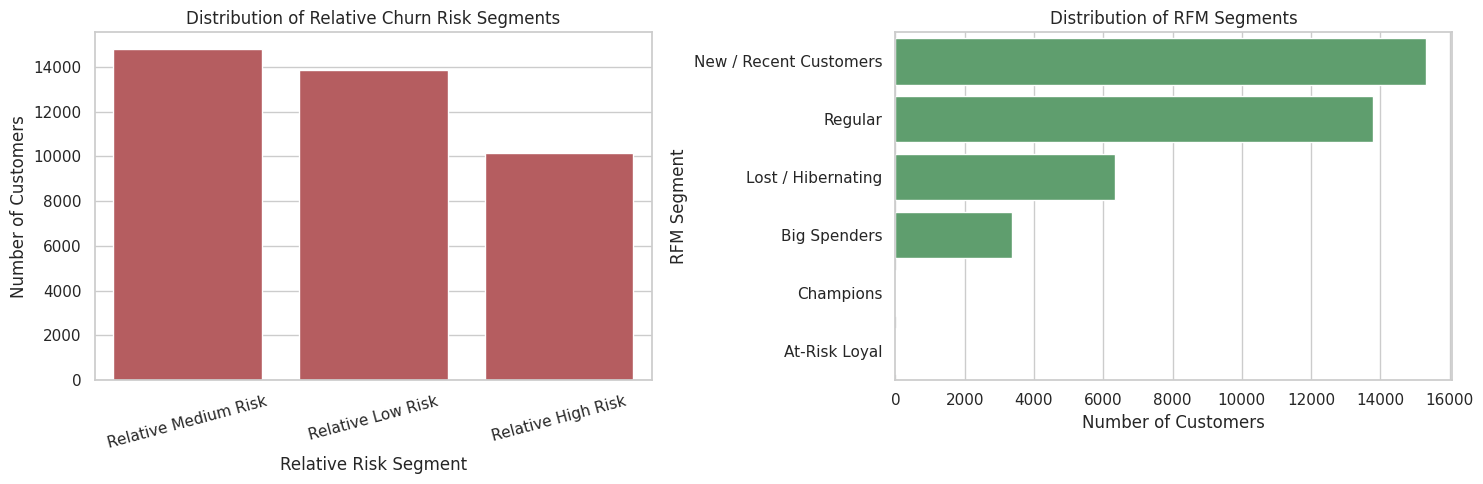


Distribution of SHAP churn drivers:


,business_feature,total_appearances
0,Total Orders,32288
1,Recency,18753
2,Favorite Category,18628
3,Average Items per Order,14622
4,Customer State,13888
5,Average Review Score,9944
6,Total Spend,2593
7,Active Span,2505
8,Payment Method,1277
9,Single Order Customer,785


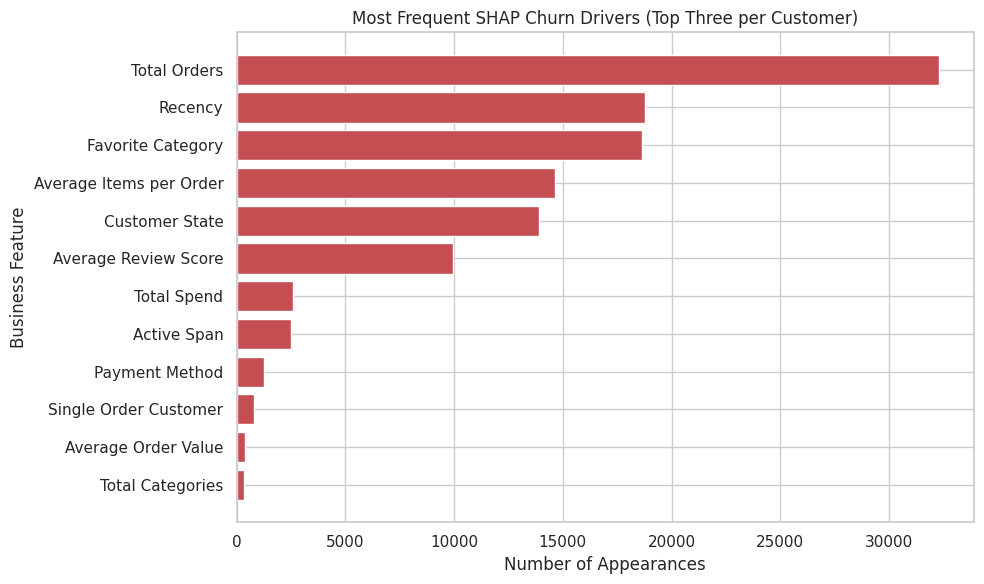


Marketing dashboard saved: /content/olist_outputs/marketing_churn_dashboard.csv
SHAP driver distribution saved: /content/olist_outputs/shap_driver_distribution.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. HASIL MODEL TERPILIH DARI VALIDATION
# ============================================================

best_probability = model_probabilities[
    best_model_name
]

best_threshold = model_thresholds[
    best_model_name
]

best_prediction = (
    best_probability >= best_threshold
).astype(int)


# ============================================================
# 2. MEMBENTUK MARKETING DASHBOARD
# ============================================================

marketing_dashboard = (
    holdout
    .reset_index(drop=True)
    .copy()
)

original_customer_order = marketing_dashboard[
    "customer_unique_id"
].copy()

marketing_dashboard = marketing_dashboard.merge(
    customer_shap_drivers,
    on="customer_unique_id",
    how="left",
    validate="one_to_one",
    sort=False
)

# Memastikan urutan customer tidak berubah setelah merge
assert original_customer_order.equals(
    marketing_dashboard[
        "customer_unique_id"
    ]
), (
    "Customer order changed after the SHAP merge."
)


# Kolom lama dipertahankan agar kode sebelumnya tetap kompatibel
marketing_dashboard[
    "churn_probability"
] = best_probability

# Nama yang digunakan untuk interpretasi dan dashboard
marketing_dashboard[
    "churn_risk_score"
] = best_probability

# Probabilitas hasil rekalibrasi Platt dari bagian 19
marketing_dashboard[
    "calibrated_churn_probability"
] = calibrated_probability

marketing_dashboard[
    "decision_threshold"
] = best_threshold

marketing_dashboard[
    "churn_prediction"
] = best_prediction

marketing_dashboard[
    "actual_status"
] = np.where(
    marketing_dashboard["is_churn"] == 1,
    "Churn",
    "Active"
)

marketing_dashboard[
    "predicted_status"
] = np.where(
    marketing_dashboard[
        "churn_prediction"
    ] == 1,
    "Churn",
    "Active"
)

marketing_dashboard[
    "selected_model"
] = best_model_name

marketing_dashboard[
    "explanation_method"
] = "SHAP"

marketing_dashboard[
    "score_interpretation"
] = (
    "Relative churn risk score; not an absolute probability"
)

marketing_dashboard[
    "human_oversight_note"
] = (
    "Keputusan retensi memerlukan peninjauan manusia; "
    "SHAP bukan bukti hubungan sebab-akibat."
)


# ============================================================
# 3. RELATIVE RISK SEGMENT
# Batas dipelajari dari validation, bukan holdout.
# ============================================================

validation_best_probability = validation_probabilities[
    best_model_name
]

risk_low_cutoff, risk_high_cutoff = np.quantile(
    validation_best_probability,
    [0.40, 0.75]
)

marketing_dashboard[
    "risk_segment"
] = np.select(
    [
        marketing_dashboard[
            "churn_risk_score"
        ] <= risk_low_cutoff,

        marketing_dashboard[
            "churn_risk_score"
        ] <= risk_high_cutoff
    ],
    [
        "Relative Low Risk",
        "Relative Medium Risk"
    ],
    default="Relative High Risk"
)

marketing_dashboard[
    "risk_low_cutoff"
] = risk_low_cutoff

marketing_dashboard[
    "risk_high_cutoff"
] = risk_high_cutoff

marketing_dashboard[
    "risk_definition"
] = (
    "Relative risk based on validation score quantiles"
)


# ============================================================
# 4. RFM SCORING
# ============================================================

def percentile_score(
    series,
    higher_is_better=True
):
    """
    Membentuk skor 1–5 berdasarkan percentile.
    """

    percentile = series.rank(
        method="average",
        pct=True
    )

    score = (
        np.ceil(percentile * 5)
        .clip(1, 5)
        .astype(int)
    )

    if not higher_is_better:
        score = 6 - score

    return score


def frequency_score(total_orders):
    """
    Customer dengan jumlah order yang sama
    memperoleh frequency score yang sama.
    """

    return np.select(
        [
            total_orders <= 1,
            total_orders == 2
        ],
        [
            1,
            3
        ],
        default=5
    ).astype(int)


marketing_dashboard[
    "R_score"
] = percentile_score(
    marketing_dashboard[
        "recency_days"
    ],
    higher_is_better=False
)

marketing_dashboard[
    "F_score"
] = frequency_score(
    marketing_dashboard[
        "total_orders"
    ]
)

marketing_dashboard[
    "M_score"
] = percentile_score(
    marketing_dashboard[
        "total_spend"
    ],
    higher_is_better=True
)

marketing_dashboard[
    "RFM_score"
] = (
    marketing_dashboard[
        "R_score"
    ].astype(str)
    + marketing_dashboard[
        "F_score"
    ].astype(str)
    + marketing_dashboard[
        "M_score"
    ].astype(str)
)

marketing_dashboard[
    "RFM_sum"
] = marketing_dashboard[
    [
        "R_score",
        "F_score",
        "M_score"
    ]
].sum(axis=1)


# ============================================================
# 5. RFM SEGMENTATION
# ============================================================

def assign_rfm_segment(row):

    recency = row["R_score"]
    frequency = row["F_score"]
    monetary = row["M_score"]

    if (
        recency >= 4
        and frequency >= 4
        and monetary >= 4
    ):
        return "Champions"

    if (
        recency >= 4
        and frequency <= 2
    ):
        return "New / Recent Customers"

    if (
        recency <= 2
        and frequency >= 4
    ):
        return "At-Risk Loyal"

    if (
        recency <= 2
        and frequency <= 2
        and monetary <= 2
    ):
        return "Lost / Hibernating"

    if (
        recency >= 3
        and monetary >= 4
    ):
        return "Big Spenders"

    return "Regular"


marketing_dashboard[
    "rfm_segment"
] = marketing_dashboard.apply(
    assign_rfm_segment,
    axis=1
)


# ============================================================
# 6. SALES KPI
# ============================================================

sales_kpi = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Total Customers",
        "Product Revenue",
        "Gross Order Value Including Freight",
        "Average Order Value Including Freight",
        "Average Review Score",
        "Total Freight"
    ],
    "Value": [
        fact["order_id"].nunique(),
        fact["customer_unique_id"].nunique(),
        fact["items_price"].sum(),
        fact["order_total_value"].sum(),
        fact["order_total_value"].mean(),
        fact["review_score"].mean(),
        fact["freight_value"].sum()
    ]
})

sales_kpi.to_csv(
    OUTPUT_DIR / "sales_kpi_summary.csv",
    index=False
)

monthly_transaction.to_csv(
    OUTPUT_DIR / "monthly_sales_trend.csv",
    index=False
)

category_performance.to_csv(
    OUTPUT_DIR / "category_performance.csv",
    index=False
)


# ============================================================
# 7. RFM DAN RISK SUMMARY
# ============================================================

rfm_summary = (
    marketing_dashboard
    .groupby(
        "rfm_segment",
        as_index=False,
        observed=True
    )
    .agg(
        total_customers=(
            "customer_unique_id",
            "nunique"
        ),
        actual_churn_rate=(
            "is_churn",
            "mean"
        ),
        average_churn_risk_score=(
            "churn_risk_score",
            "mean"
        ),
        average_total_spend=(
            "total_spend",
            "mean"
        ),
        average_orders=(
            "total_orders",
            "mean"
        )
    )
)

risk_summary = (
    marketing_dashboard
    .groupby(
        "risk_segment",
        as_index=False,
        observed=True
    )
    .agg(
        total_customers=(
            "customer_unique_id",
            "nunique"
        ),
        actual_churn_rate=(
            "is_churn",
            "mean"
        ),
        average_churn_risk_score=(
            "churn_risk_score",
            "mean"
        ),
        average_total_spend=(
            "total_spend",
            "mean"
        )
    )
)

rfm_summary.to_csv(
    OUTPUT_DIR / "rfm_segment_summary.csv",
    index=False
)

risk_summary.to_csv(
    OUTPUT_DIR / "risk_segment_summary.csv",
    index=False
)


# ============================================================
# 8. MENAMPILKAN OUTPUT DASHBOARD
# ============================================================

print("Dashboard model:", best_model_name)

print(
    "Decision threshold:",
    round(best_threshold, 4)
)

print(
    "Relative risk cut-points from validation:",
    round(risk_low_cutoff, 4),
    "and",
    round(risk_high_cutoff, 4)
)

print(
    "Note: model output is used as a relative "
    "churn risk score, not an absolute probability."
)

print("\nSales KPI:")

display(sales_kpi)

print("\nRisk Segment Summary:")

display(
    risk_summary.round(4)
)

print("\nRFM Segment Summary:")

display(
    rfm_summary.round(4)
)

print("\nMarketing dashboard preview:")

display(
    english_view(marketing_dashboard)[
        [
            "customer_unique_id",
            "recency_days",
            "total_orders",
            "total_spend",
            "churn_risk_score",
            "decision_threshold",
            "churn_prediction",
            "risk_segment",
            "top_churn_driver_1",
            "top_churn_driver_2",
            "top_churn_driver_3",
            "top_protective_factor",
            "R_score",
            "F_score",
            "M_score",
            "RFM_score",
            "rfm_segment"
        ]
    ].head(10)
)


# ============================================================
# 9. VISUALISASI RISK DAN RFM
# ============================================================

risk_distribution = (
    marketing_dashboard[
        "risk_segment"
    ]
    .value_counts()
    .rename_axis("risk_segment")
    .reset_index(name="total_customers")
)

rfm_distribution = (
    marketing_dashboard[
        "rfm_segment"
    ]
    .value_counts()
    .rename_axis("rfm_segment")
    .reset_index(name="total_customers")
)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)

sns.barplot(
    data=risk_distribution,
    x="risk_segment",
    y="total_customers",
    color="#C44E52",
    ax=axes[0]
)

axes[0].set_title(
    "Distribution of Relative Churn Risk Segments"
)
axes[0].set_xlabel(
    "Relative Risk Segment"
)
axes[0].set_ylabel(
    "Number of Customers"
)
axes[0].tick_params(
    axis="x",
    rotation=15
)

sns.barplot(
    data=rfm_distribution,
    y="rfm_segment",
    x="total_customers",
    color="#55A868",
    ax=axes[1]
)

axes[1].set_title(
    "Distribution of RFM Segments"
)
axes[1].set_xlabel(
    "Number of Customers"
)
axes[1].set_ylabel(
    "RFM Segment"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "risk_and_rfm_distribution.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 10. DISTRIBUSI FAKTOR UTAMA SHAP
# ============================================================

shap_driver_distribution = pd.concat([
    marketing_dashboard[
        ["top_churn_driver_1"]
    ].rename(
        columns={
            "top_churn_driver_1": "business_feature"
        }
    ),

    marketing_dashboard[
        ["top_churn_driver_2"]
    ].rename(
        columns={
            "top_churn_driver_2": "business_feature"
        }
    ),

    marketing_dashboard[
        ["top_churn_driver_3"]
    ].rename(
        columns={
            "top_churn_driver_3": "business_feature"
        }
    )
], ignore_index=True)

shap_driver_distribution = (
    shap_driver_distribution
    .dropna(
        subset=["business_feature"]
    )
)

shap_driver_distribution = (
    shap_driver_distribution[
        shap_driver_distribution[
            "business_feature"
        ] != "Tidak ada pendorong positif"
    ]
    .value_counts("business_feature")
    .reset_index(name="total_appearances")
    .sort_values(
        "total_appearances",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_driver_distribution.to_csv(
    OUTPUT_DIR / "shap_driver_distribution.csv",
    index=False
)

print("\nDistribution of SHAP churn drivers:")

display(
    shap_driver_distribution.head(15)
)


top_shap_drivers = (
    shap_driver_distribution
    .head(12)
    .sort_values("total_appearances")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_shap_drivers[
        "business_feature"
    ],
    top_shap_drivers[
        "total_appearances"
    ],
    color="#C44E52"
)

plt.title(
    "Most Frequent SHAP Churn Drivers (Top Three per Customer)"
)
plt.xlabel("Number of Appearances")
plt.ylabel("Business Feature")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "shap_driver_distribution.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 11. MENYIMPAN MARKETING DASHBOARD FINAL
# ============================================================

marketing_dashboard.to_csv(
    OUTPUT_DIR / "marketing_churn_dashboard.csv",
    index=False
)

print(
    "\nMarketing dashboard saved:",
    OUTPUT_DIR / "marketing_churn_dashboard.csv"
)

print(
    "SHAP driver distribution saved:",
    OUTPUT_DIR / "shap_driver_distribution.csv"
)


## 21. Validasi dan download seluruh output


Cell terakhir memeriksa granularitas data, kelengkapan kolom dashboard,
keberadaan output model, SHAP, Responsible AI, serta membuat file ZIP.


In [ ]:
# ============================================================
# CELL 21 — VALIDASI DAN DOWNLOAD SELURUH OUTPUT
# ============================================================

import shutil
import numpy as np
import pandas as pd

from google.colab import files


# ============================================================
# 1. VALIDASI LEVEL DATA
# ============================================================

assert fact["order_id"].is_unique, (
    "The fact table still contains duplicate order_id values."
)

assert marketing_dashboard[
    "customer_unique_id"
].is_unique, (
    "The marketing dashboard still contains duplicate customers."
)

assert (
    fact["order_status"] == "delivered"
).all(), (
    "The fact table still contains non-delivered transactions."
)

assert len(marketing_dashboard) == len(holdout), (
    "The number of marketing dashboard rows does not match "
    "the number of holdout customers."
)


# ============================================================
# 2. VALIDASI KOLOM DASHBOARD
# ============================================================

required_dashboard_columns = {
    "customer_unique_id",
    "is_churn",
    "churn_probability",
    "churn_risk_score",
    "decision_threshold",
    "churn_prediction",
    "actual_status",
    "predicted_status",
    "risk_segment",
    "risk_definition",
    "R_score",
    "F_score",
    "M_score",
    "RFM_score",
    "rfm_segment",
    "shap_explained_model",
    "top_churn_driver_1",
    "top_churn_driver_2",
    "top_churn_driver_3",
    "top_protective_factor",
    "score_interpretation",
    "human_oversight_note"
}

missing_dashboard_columns = (
    required_dashboard_columns
    - set(marketing_dashboard.columns)
)

if missing_dashboard_columns:
    raise ValueError(
        "Dashboard columns are incomplete: "
        + str(missing_dashboard_columns)
    )

print("Data-level and dashboard column validation passed.")

print(
    "Number of orders:",
    f"{fact['order_id'].nunique():,}"
)

print(
    "Number of dashboard customers:",
    f"{marketing_dashboard['customer_unique_id'].nunique():,}"
)


# ============================================================
# 3. VALIDASI NILAI SHAP
# ============================================================

invalid_positive_drivers = 0

for rank_number in range(1, 4):

    driver_column = (
        f"top_churn_driver_{rank_number}"
    )

    value_column = (
        f"top_churn_driver_{rank_number}_value"
    )

    invalid_positive_drivers += (
        (
            marketing_dashboard[
                driver_column
            ] != "Tidak ada pendorong positif"
        )
        & (
            marketing_dashboard[
                value_column
            ] <= 0
        )
    ).sum()

assert invalid_positive_drivers == 0, (
    "Some factors labeled as churn drivers "
    "have non-positive SHAP values."
)

invalid_protective_factors = (
    (
        marketing_dashboard[
            "top_protective_factor"
        ] != "Tidak ada faktor pelindung"
    )
    & (
        marketing_dashboard[
            "top_protective_value"
        ] >= 0
    )
).sum()

assert invalid_protective_factors == 0, (
    "Some protective factors have "
    "non-negative SHAP values."
)

print("SHAP contribution direction validation passed.")


# ============================================================
# 4. DAFTAR OUTPUT WAJIB
# ============================================================

important_outputs = [
    "sales_dashboard_order_level.csv",
    "marketing_churn_dashboard.csv",
    "model_selection_validation.csv",
    "model_performance_comparison.csv",
    "model_validation_and_holdout.csv",
    "machine_learning_metrics.csv",
    "deep_learning_trials.csv",
    "classification_reports.csv",
    "confusion_matrices.csv",
    "feature_importance.csv",
    "sales_kpi_summary.csv",
    "monthly_sales_trend.csv",
    "category_performance.csv",
    "rfm_segment_summary.csv",
    "risk_segment_summary.csv",
    "shap_global_importance_detailed.csv",
    "shap_global_importance_grouped.csv",
    "shap_customer_explanations.csv",
    "shap_driver_distribution.csv",
    "calibration_metrics.csv",
    "calibration_curve.csv",
    "bootstrap_confidence_intervals.csv",
    "geographic_performance_audit.csv",
    "responsible_ai_summary.csv",
    "responsible_ai_model_card.csv",
    "figures/shap_global_bar.png",
    "figures/shap_beeswarm.png",
    "figures/shap_grouped_business_features.png",
    "figures/shap_waterfall_high_risk.png",
    "figures/shap_waterfall_low_risk.png",
    "figures/shap_driver_distribution.png",
    "figures/calibration_curve.png",
    "figures/risk_and_rfm_distribution.png"
]

output_status_rows = []

for filename in important_outputs:

    file_path = OUTPUT_DIR / filename

    output_status_rows.append({
        "File Name": filename,
        "Status": (
            "Created"
            if file_path.exists()
            else "Not created"
        ),
        "Size (KB)": (
            round(
                file_path.stat().st_size / 1024,
                2
            )
            if file_path.exists()
            else np.nan
        )
    })

output_status = pd.DataFrame(
    output_status_rows
)

print("\nStatus of all outputs:")

display(output_status)

failed_outputs = output_status[
    output_status["Status"] != "Created"
]

if len(failed_outputs) > 0:

    print(
        "Warning: some outputs "
        "were not created."
    )

    display(failed_outputs)

    raise FileNotFoundError(
        "Some outputs have not been created. "
        "Please check the previous cells."
    )

else:
    print("All outputs were created.")


# ============================================================
# 5. RINGKASAN FINAL
# ============================================================

selected_holdout_metrics = metrics_dataframe[
    metrics_dataframe[
        "model"
    ] == best_model_name
].iloc[0]

final_summary = pd.DataFrame({
    "Indicator": [
        "Total order fact table",
        "Customer marketing dashboard",
        "Number of features in the selected model",
        "Number of models",
        "Model selection criterion",
        "Model selected on validation",
        "Threshold from validation",
        "Balanced Accuracy holdout",
        "ROC-AUC holdout",
        "PR-AUC Active holdout",
        "PR-AUC relative to baseline",
        "Model explained by SHAP",
        "Top global SHAP feature",
        "Brier Score model",
        "Brier Score baseline",
        "Score interpretation",
        "Responsible AI output"
    ],
    "Value": [
        fact["order_id"].nunique(),
        marketing_dashboard[
            "customer_unique_id"
        ].nunique(),
        selected_feature_count,
        len(metrics_dataframe),
        "PR-AUC Active validation",
        best_model_name,
        model_thresholds[
            best_model_name
        ],
        selected_holdout_metrics[
            "balanced_accuracy"
        ],
        selected_holdout_metrics[
            "roc_auc"
        ],
        selected_holdout_metrics[
            "pr_auc_active"
        ],
        pr_auc_improvement,
        explained_model_name,
        shap_global_grouped.iloc[
            0
        ]["business_feature"],
        selected_brier_score,
        baseline_brier_score,
        (
            "Relative churn risk score; "
            "not an absolute probability"
        ),
        (
            "SHAP, model card, calibration, "
            "bootstrap CI, geographic audit, "
            "and human oversight"
        )
    ]
})

print("\nFinal study summary:")

display(
    final_summary.round(6)
)


# ============================================================
# 6. KESIMPULAN OTOMATIS
# ============================================================

print("\n" + "=" * 65)
print("FINAL PIPELINE SUMMARY")
print("=" * 65)

print("Selected model:", best_model_name)

print(
    "Threshold:",
    round(
        model_thresholds[
            best_model_name
        ],
        4
    )
)

print(
    "Balanced Accuracy holdout:",
    round(
        selected_holdout_metrics[
            "balanced_accuracy"
        ],
        4
    )
)

print(
    "ROC-AUC holdout:",
    round(
        selected_holdout_metrics[
            "roc_auc"
        ],
        4
    )
)

print(
    "PR-AUC Active holdout:",
    round(
        selected_holdout_metrics[
            "pr_auc_active"
        ],
        4
    )
)

print(
    "Active-class PR-AUC improvement:",
    round(pr_auc_improvement, 2),
    "times the baseline"
)

print(
    "Most important SHAP feature:",
    shap_global_grouped.iloc[
        0
    ]["business_feature"]
)

print(
    "Note: the score is used as a relative churn "
    "risk score, not an absolute probability."
)


# ============================================================
# 7. MEMBUAT DAN DOWNLOAD ZIP
# ============================================================

zip_path = shutil.make_archive(
    "/content/Olist_Responsible_AI_SHAP_FINAL",
    "zip",
    OUTPUT_DIR
)

print("\nZIP file created:")
print(zip_path)

files.download(zip_path)

Data-level and dashboard column validation passed.
Number of orders: 96,478
Number of dashboard customers: 38,838
SHAP contribution direction validation passed.

Status of all outputs:


,File Name,Status,Size (KB)
0,sales_dashboard_order_level.csv,Created,26558.18
1,marketing_churn_dashboard.csv,Created,26763.74
2,model_selection_validation.csv,Created,1.36
3,model_performance_comparison.csv,Created,1.39
4,model_validation_and_holdout.csv,Created,2.68
5,machine_learning_metrics.csv,Created,1.10
6,deep_learning_trials.csv,Created,0.23
7,classification_reports.csv,Created,0.78
8,confusion_matrices.csv,Created,0.29
9,feature_importance.csv,Created,2.95


All outputs were created.

Final study summary:


,Indicator,Value
0,Total order fact table,96478
1,Customer marketing dashboard,38838
2,Number of features in the selected model,52
3,Number of models,4
4,Model selection criterion,PR-AUC Active validation
5,Model selected on validation,Logistic Regression
6,Threshold from validation,0.44
7,Balanced Accuracy holdout,0.588807
8,ROC-AUC holdout,0.613596
9,PR-AUC Active holdout,0.019521



FINAL PIPELINE SUMMARY
Selected model: Logistic Regression
Threshold: 0.44
Balanced Accuracy holdout: 0.5888
ROC-AUC holdout: 0.6136
PR-AUC Active holdout: 0.0195
Active-class PR-AUC improvement: 2.92 times the baseline
Most important SHAP feature: Favorite Category
Note: the score is used as a relative churn risk score, not an absolute probability.

ZIP file created:
/content/Olist_Responsible_AI_SHAP_FINAL.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# PIP INSTALL STREAMLIT

##22. Tahap 1 — SHAP Re-analysis

#CELL 1A: Persiapan, skema grup, dan verifikasi korelasi

In [ ]:

import pandas as pd
import shap
from scipy.stats import kendalltau
from sklearn.base import clone

STAGE1_DIR = OUTPUT_DIR / "stage1_shap_reanalysis"
STAGE1_DIR.mkdir(parents=True, exist_ok=True)

# ---- 1. Cek objek wajib dari notebook ----------------------
required_objects = [
    "trained_models", "best_model_name", "X_calibration_raw",
    "y_calibration", "training_groups", "X_holdout_raw", "y_holdout",
    "holdout", "validation_probabilities", "model_probabilities",
    "numeric_features", "categorical_features", "SEED", "OUTPUT_DIR",
]
missing = [name for name in required_objects if name not in globals()]
if missing:
    raise NameError(
        "Objek berikut belum ada. Jalankan notebook sampai CELL 36: "
        + ", ".join(missing)
    )

assert best_model_name == "Logistic Regression", (
    "Tahap 1 dirancang untuk LR (LinearExplainer). Model terpilih: "
    + str(best_model_name)
)

ref_pipeline = trained_models[best_model_name]
ref_preprocessor = ref_pipeline.named_steps["preprocessor"]
ref_classifier = ref_pipeline.named_steps["classifier"]

# ---- 2. Skema pengelompokan --------------------------------
# Skema A = 14 fitur bisnis seperti di artikel saat ini.
# Skema B = fitur repeat-purchase yang tumpang tindih digabung,
#           begitu juga dua fitur moneter. Grup ditentukan secara
#           konseptual LEBIH DULU, lalu diverifikasi dengan korelasi
#           Spearman pada calibration set (data training saja).
BASE_LABELS = {
    "recency_days": "Recency",
    "total_orders": "Total Orders",
    "total_spend": "Total Spend",
    "average_order_value": "Average Order Value",
    "avg_days_between_orders": "Average Days Between Orders",
    "single_order_flag": "Single Order Customer",
    "avg_review_score": "Average Review Score",
    "total_reviews": "Total Reviews",
    "average_items_per_order": "Average Items per Order",
    "total_categories": "Total Categories",
    "active_span_days": "Active Span",
    "favorite_category": "Favorite Category",
    "payment_method": "Payment Method",
    "customer_state": "Customer State",
}

CORRELATED_GROUPS = {
    "Repeat-Purchase History": [
        "total_orders", "single_order_flag", "active_span_days",
        "avg_days_between_orders", "total_reviews",
    ],
    "Monetary Value": ["total_spend", "average_order_value"],
}


def source_feature(transformed_name):
    """'numeric__total_orders' -> 'total_orders';
    'categorical__customer_state_SP' -> 'customer_state'."""
    raw = transformed_name.split("__", 1)[-1]
    for cat in categorical_features:
        if raw.startswith(cat + "_"):
            return cat
    return raw


def group_label(transformed_name, scheme):
    src = source_feature(transformed_name)
    if scheme == "B":
        for group, members in CORRELATED_GROUPS.items():
            if src in members:
                return group
    return BASE_LABELS.get(src, src)


# ---- 3. Verifikasi korelasi (calibration set saja) ---------
spearman = X_calibration_raw[numeric_features].corr(method="spearman")
spearman.to_csv(STAGE1_DIR / "stage1_spearman_numeric_calibration.csv")

group_check_rows = []
for group, members in CORRELATED_GROUPS.items():
    sub = spearman.loc[members, members].abs()
    upper = sub.where(np.triu(np.ones(sub.shape, dtype=bool), k=1))
    pairs = upper.stack()
    others = [f for f in numeric_features if f not in members]
    group_check_rows.append({
        "group": group,
        "members": ", ".join(members),
        "min_abs_rho_within": round(pairs.min(), 3),
        "median_abs_rho_within": round(pairs.median(), 3),
        "max_abs_rho_with_outside": round(
            spearman.loc[members, others].abs().values.max(), 3
        ),
    })
group_check = pd.DataFrame(group_check_rows)
group_check.to_csv(STAGE1_DIR / "stage1_grouping_check.csv", index=False)

print("Korelasi Spearman |rho| antar fitur numerik (calibration):")
display(spearman.round(2))
print("\nPemeriksaan grup korelasi:")
display(group_check)

# Pasangan dengan |rho| >= 0.7 di seluruh fitur numerik
high_pairs = (
    spearman.abs()
    .where(np.triu(np.ones(spearman.shape, dtype=bool), k=1))
    .stack()
    .loc[lambda s: s >= 0.7]
    .sort_values(ascending=False)
    .rename("abs_spearman")
    .reset_index()
)
high_pairs.to_csv(STAGE1_DIR / "stage1_high_correlation_pairs.csv", index=False)
print("\nPasangan fitur dengan |rho| >= 0.70:")
display(high_pairs)

Korelasi Spearman |rho| antar fitur numerik (calibration):


,recency_days,total_orders,total_spend,average_order_value,avg_days_between_orders,single_order_flag,avg_review_score,total_reviews,average_items_per_order,total_categories,active_span_days
recency_days,1.00,-0.03,-0.00,0.00,-0.03,0.03,0.03,-0.02,-0.00,-0.02,-0.02
total_orders,-0.03,1.00,0.14,0.00,0.93,-1.00,-0.01,0.86,0.07,0.67,0.60
total_spend,-0.00,0.14,1.00,0.99,0.13,-0.14,-0.03,0.11,0.22,0.10,0.09
average_order_value,0.00,0.00,0.99,1.00,0.01,-0.00,-0.03,-0.01,0.22,0.01,0.01
avg_days_between_orders,-0.03,0.93,0.13,0.01,1.00,-0.93,-0.01,0.81,0.06,0.64,0.65
single_order_flag,0.03,-1.00,-0.14,-0.00,-0.93,1.00,0.01,-0.86,-0.07,-0.67,-0.59
avg_review_score,0.03,-0.01,-0.03,-0.03,-0.01,0.01,1.00,-0.01,-0.10,-0.01,0.00
total_reviews,-0.02,0.86,0.11,-0.01,0.81,-0.86,-0.01,1.00,0.05,0.58,0.52
average_items_per_order,-0.00,0.07,0.22,0.22,0.06,-0.07,-0.10,0.05,1.00,0.04,0.04
total_categories,-0.02,0.67,0.10,0.01,0.64,-0.67,-0.01,0.58,0.04,1.00,0.46



Pemeriksaan grup korelasi:


,group,members,min_abs_rho_within,median_abs_rho_within,max_abs_rho_with_outside
0,Repeat-Purchase History,"total_orders, single_order_flag, active_span_d...",0.519,0.836,0.669
1,Monetary Value,"total_spend, average_order_value",0.989,0.989,0.224



Pasangan fitur dengan |rho| >= 0.70:


,level_0,level_1,abs_spearman
0,total_orders,single_order_flag,0.999982
1,total_spend,average_order_value,0.989381
2,total_orders,avg_days_between_orders,0.929157
3,avg_days_between_orders,single_order_flag,0.928935
4,total_orders,total_reviews,0.864937
5,single_order_flag,total_reviews,0.864913
6,avg_days_between_orders,total_reviews,0.806415


#CELL 1B: SHAP referensi dan cek reproduksi

In [ ]:
# ============================================================
# Background dipilih PERSIS seperti CELL 36 (rng SEED, 500 baris
# calibration) sehingga hasil referensi harus identik.
# ============================================================

def background_indices(seed, size):
    rng = np.random.default_rng(seed)
    return rng.choice(len(X_calibration_raw), size=min(size, len(X_calibration_raw)),
                      replace=False)


def linear_shap(pipeline, bg_index):
    """SHAP (log-odds) untuk seluruh holdout; mengembalikan
    (shap_values, transformed_feature_names)."""
    pre = pipeline.named_steps["preprocessor"]
    clf = pipeline.named_steps["classifier"]
    names = pre.get_feature_names_out()
    X_bg = pd.DataFrame(pre.transform(X_calibration_raw.iloc[bg_index]), columns=names)
    X_ho = pd.DataFrame(pre.transform(X_holdout_raw), columns=names)
    masker = shap.maskers.Independent(X_bg, max_samples=len(X_bg))
    explainer = shap.LinearExplainer(clf, masker)
    values = np.asarray(explainer(X_ho).values)
    return values, names


def group_shap(values, names, scheme):
    labels = np.array([group_label(n, scheme) for n in names])
    groups = list(dict.fromkeys(labels))
    grouped = np.column_stack([values[:, labels == g].sum(axis=1) for g in groups])
    return grouped, groups


REF_BG_INDEX = background_indices(SEED, 500)
ref_values, ref_names = linear_shap(ref_pipeline, REF_BG_INDEX)

# Cek reproduksi terhadap array SHAP asli (bila masih di memori)
if "shap_values_array" in globals():
    max_diff = float(np.max(np.abs(ref_values - shap_values_array)))
    print("Selisih maksimum vs shap_values_array asli:", max_diff)
    assert max_diff < 1e-8, "SHAP referensi tidak identik dengan CELL 36."

# Cek reproduksi terhadap file shap_driver_distribution.csv (positif, skema A)
grouped_A, groups_A = group_shap(ref_values, ref_names, "A")
order_pos = np.argsort(-grouped_A, axis=1)[:, :3]
rows = np.arange(len(grouped_A))
counts = {}
for r in range(3):
    idx = order_pos[:, r]
    val = grouped_A[rows, idx]
    for g, v in zip(np.array(groups_A)[idx], val):
        if v > 0:
            counts[g] = counts.get(g, 0) + 1
repro = pd.Series(counts, name="recomputed_top3_positive").to_frame()
old_file = OUTPUT_DIR / "shap_driver_distribution.csv"
if old_file.exists():
    old = pd.read_csv(old_file).set_index("business_feature")["total_appearances"]
    repro["original_file"] = old
    repro["difference"] = repro["recomputed_top3_positive"] - repro["original_file"]
repro = repro.sort_values("recomputed_top3_positive", ascending=False)
repro.to_csv(STAGE1_DIR / "stage1_reproduction_check.csv")
print("\nReproduksi distribusi driver lama (top-3 positif, skema A):")
display(repro)

Selisih maksimum vs shap_values_array asli: 0.0

Reproduksi distribusi driver lama (top-3 positif, skema A):


,recomputed_top3_positive,original_file,difference
Total Orders,32288,32288,0
Recency,18753,18753,0
Favorite Category,18628,18628,0
Average Items per Order,14622,14622,0
Customer State,13888,13888,0
Average Review Score,9944,9944,0
Total Spend,2593,2593,0
Active Span,2505,2505,0
Payment Method,1277,1277,0
Single Order Customer,785,785,0


#CELL 1C: Diagnostik kontribusi yang hampir konstan

In [ ]:
# ============================================================
# Menjelaskan mengapa Total Orders sering muncul sebagai driver:
# untuk fitur yang hampir konstan, SHAP linear juga hampir konstan.
# ============================================================
diag_rows = []
grouped_B, groups_B = group_shap(ref_values, ref_names, "B")
for scheme, grouped, groups in [("A", grouped_A, groups_A), ("B", grouped_B, groups_B)]:
    for j, g in enumerate(groups):
        col = grouped[:, j]
        diag_rows.append({
            "scheme": scheme,
            "group": g,
            "mean_abs_shap": np.abs(col).mean(),
            "std_shap": col.std(),
            "share_positive": (col > 0).mean(),
            "n_unique_values_rounded_1e6": len(np.unique(np.round(col, 6))),
            "modal_value_share": pd.Series(np.round(col, 6)).value_counts(normalize=True).iloc[0],
        })
diagnostic = pd.DataFrame(diag_rows)
diagnostic.to_csv(STAGE1_DIR / "stage1_shap_constancy_diagnostic.csv", index=False)
display(diagnostic.round(4))

,scheme,group,mean_abs_shap,std_shap,share_positive,n_unique_values_rounded_1e6,modal_value_share
0,A,Recency,0.1273,0.1464,0.5541,182,0.0093
1,A,Total Orders,0.0742,0.2362,0.9798,6,0.9798
2,A,Total Spend,0.0182,0.0331,0.2771,15619,0.0027
3,A,Average Order Value,0.0071,0.0130,0.2781,13184,0.0027
4,A,Average Days Between Orders,0.0003,0.0023,0.9879,482,0.9866
5,A,Single Order Customer,0.0143,0.0427,0.0202,2,0.9798
6,A,Average Review Score,0.1064,0.1372,0.4328,23,0.5650
7,A,Total Reviews,0.0030,0.0109,0.0198,7,0.9733
8,A,Average Items per Order,0.0524,0.1161,0.8989,29,0.8989
9,A,Total Categories,0.0110,0.0481,0.0093,5,0.9907


#CELL 1D: Peringkat global vs individual dan Kendall’s τ

In [ ]:
# ============================================================
# Dua basis yang dibandingkan secara SETARA:
#   ABS : global = mean |SHAP|      ; individual = top-k by |SHAP|
#   POS : global = mean max(SHAP,0) ; individual = top-k by SHAP>0
# ============================================================

def driver_table(grouped, groups, basis):
    n = len(grouped)
    rows = np.arange(n)
    if basis == "ABS":
        score = np.abs(grouped)
        global_value = score.mean(axis=0)
    else:  # POS
        score = np.where(grouped > 0, grouped, -np.inf)
        global_value = np.clip(grouped, 0, None).mean(axis=0)
    order = np.argsort(-score, axis=1)[:, :3]
    top1 = pd.Series(0, index=groups, dtype=int)
    top3 = pd.Series(0, index=groups, dtype=int)
    for r in range(3):
        idx = order[:, r]
        valid = np.isfinite(score[rows, idx]) & (score[rows, idx] > 0)
        names_r = np.array(groups)[idx][valid]
        vc = pd.Series(names_r).value_counts()
        top3 = top3.add(vc, fill_value=0)
        if r == 0:
            top1 = top1.add(vc, fill_value=0)
    table = pd.DataFrame({
        "global_value": global_value,
        "top1_count": top1.reindex(groups).astype(int).values,
        "top3_count": top3.reindex(groups).astype(int).values,
    }, index=groups)
    table["global_rank"] = table["global_value"].rank(ascending=False, method="min").astype(int)
    table["top1_rank"] = table["top1_count"].rank(ascending=False, method="min").astype(int)
    table["top3_rank"] = table["top3_count"].rank(ascending=False, method="min").astype(int)
    table["top1_share_pct"] = 100 * table["top1_count"] / n
    table["top3_share_pct"] = 100 * table["top3_count"] / n
    return table.sort_values("global_rank"), order


def tau(a, b):
    res = kendalltau(a, b, variant="b")
    return res.statistic, res.pvalue


tables, tau_rows, customer_orders = [], [], {}
for scheme, grouped, groups in [("A", grouped_A, groups_A), ("B", grouped_B, groups_B)]:
    abs_global = pd.Series(np.abs(grouped).mean(axis=0), index=groups)
    for basis in ["ABS", "POS"]:
        t, order = driver_table(grouped, groups, basis)
        customer_orders[(scheme, basis)] = order
        t.insert(0, "basis", basis)
        t.insert(0, "scheme", scheme)
        tables.append(t.reset_index(names="feature_group"))
        for local_col in ["top1_count", "top3_count"]:
            stat, p = tau(t["global_value"], t[local_col])
            # Versi "core": hanya grup dengan mean |SHAP| global >= 0.02
            # (grup yang hampir tidak berperan dapat menghasilkan banyak ties)
            core_groups = abs_global[abs_global >= 0.02].index
            core = t.loc[t.index.isin(core_groups)]
            stat_core, p_core = tau(core["global_value"], core[local_col]) if len(core) >= 4 else (np.nan, np.nan)
            tau_rows.append({
                "scheme": scheme, "basis": basis,
                "comparison": f"global_value vs {local_col}",
                "n_groups": len(t), "kendall_tau_b": stat, "p_value": p,
                "n_core_groups": len(core), "kendall_tau_b_core": stat_core, "p_value_core": p_core,
            })

global_local = pd.concat(tables, ignore_index=True)
tau_table = pd.DataFrame(tau_rows)
global_local.to_csv(STAGE1_DIR / "stage1_global_vs_individual.csv", index=False)
tau_table.to_csv(STAGE1_DIR / "stage1_kendall_tau.csv", index=False)

print("Tabel global vs individual (lihat skema B, basis ABS dan POS):")
display(global_local.round(4))
print("\nKendall's tau-b:")
display(tau_table.round(4))

Tabel global vs individual (lihat skema B, basis ABS dan POS):


,feature_group,scheme,basis,global_value,top1_count,top3_count,global_rank,top1_rank,top3_rank,top1_share_pct,top3_share_pct
0,Favorite Category,A,ABS,0.1663,16348,31466,1,1,1,42.0928,81.0186
1,Recency,A,ABS,0.1273,10145,27315,2,2,2,26.1213,70.3306
2,Average Review Score,A,ABS,0.1064,5373,21516,3,3,4,13.8344,55.3994
3,Customer State,A,ABS,0.0900,2907,22510,4,4,3,7.4849,57.9587
4,Total Orders,A,ABS,0.0742,798,5882,5,7,5,2.0547,15.1450
5,Average Items per Order,A,ABS,0.0524,1701,3652,6,5,6,4.3797,9.4032
6,Active Span,A,ABS,0.0359,469,739,7,8,9,1.2076,1.9028
7,Total Spend,A,ABS,0.0182,199,857,8,9,8,0.5124,2.2066
8,Single Order Customer,A,ABS,0.0143,0,558,9,10,10,0.0000,1.4367
9,Payment Method,A,ABS,0.0138,898,1532,10,6,7,2.3122,3.9446



Kendall's tau-b:


,scheme,basis,comparison,n_groups,kendall_tau_b,p_value,n_core_groups,kendall_tau_b_core,p_value_core
0,A,ABS,global_value vs top1_count,14,0.8270,0.0001,7,0.9048,0.0028
1,A,ABS,global_value vs top3_count,14,0.8901,0.0000,7,0.9048,0.0028
2,A,POS,global_value vs top1_count,14,0.6872,0.0009,7,0.8783,0.0062
3,A,POS,global_value vs top3_count,14,0.8022,0.0000,7,0.2381,0.5619
4,B,ABS,global_value vs top1_count,9,0.8333,0.0009,7,0.8095,0.0107
5,B,ABS,global_value vs top3_count,9,0.8333,0.0009,7,0.8095,0.0107
6,B,POS,global_value vs top1_count,9,0.7222,0.0059,7,0.8095,0.0107
7,B,POS,global_value vs top3_count,9,0.5556,0.0446,7,0.2381,0.5619


#CELL 1E: Stabilitas peringkat

In [ ]:
# ============================================================
# S1: ganti background SHAP (seed & ukuran berbeda), model tetap.
# S2: bootstrap pelanggan pada calibration set, LR di-refit dengan
#     hiperparameter TERPILIH (tidak di-tuning ulang), background tetap.
#     Holdout tidak pernah dipakai untuk melatih -> tidak ada leakage.
# ============================================================
N_BOOT = 30                          # turunkan ke 10 untuk uji cepat
BG_SEEDS = list(range(1, 11))        # 10 background alternatif
BG_SIZES = [500, 1000]
STABILITY_SCHEME = "B"

ref_grouped, ref_groups = (grouped_B, groups_B) if STABILITY_SCHEME == "B" else (grouped_A, groups_A)
ref_global_abs = pd.Series(np.abs(ref_grouped).mean(axis=0), index=ref_groups)
ref_order_abs = customer_orders[(STABILITY_SCHEME, "ABS")]
ref_order_pos = customer_orders[(STABILITY_SCHEME, "POS")]


def compare_to_reference(values, names, label, replicate):
    grouped, groups = group_shap(values, names, STABILITY_SCHEME)
    grouped = pd.DataFrame(grouped, columns=groups).reindex(columns=ref_groups, fill_value=0.0).values
    global_abs = np.abs(grouped).mean(axis=0)
    t_stat, _ = tau(ref_global_abs.values, global_abs)
    out = {"test": label, "replicate": replicate, "tau_global_abs": t_stat}
    for basis, ref_order in [("ABS", ref_order_abs), ("POS", ref_order_pos)]:
        _, order = driver_table(grouped, list(ref_groups), basis)
        out[f"top1_agreement_{basis}"] = (order[:, 0] == ref_order[:, 0]).mean()
        if basis == "ABS":
            inter = (np.sort(order, axis=1)[:, :, None] == np.sort(ref_order, axis=1)[:, None, :]).any(axis=2).sum(axis=1)
            out["top3_jaccard_ABS"] = (inter / (6 - inter)).mean()
    out["top_global_group"] = ref_groups[int(np.argmax(global_abs))]
    global_rank = pd.Series(global_abs, index=ref_groups).rank(ascending=False, method="min")
    return out, global_rank


stability_rows = []

# S1 — background
for size in BG_SIZES:
    for s in BG_SEEDS:
        vals, names = linear_shap(ref_pipeline, background_indices(SEED + 1000 * size + s, size))
        stability_rows.append(compare_to_reference(vals, names, f"S1_background_n{size}", s)[0])
print("S1 selesai.")

# S2 — customer-level bootstrap of the calibration set
unique_customers = pd.unique(training_groups)
customer_rows = pd.Series(np.arange(len(training_groups))).groupby(training_groups).apply(np.array)
rng_boot = np.random.default_rng(SEED + 7)
boot_ranks = []
for b in range(N_BOOT):
    sampled = rng_boot.choice(unique_customers, size=len(unique_customers), replace=True)
    row_index = np.concatenate(customer_rows.loc[sampled].values)
    boot_pipeline = clone(ref_pipeline)
    boot_pipeline.fit(X_calibration_raw.iloc[row_index], y_calibration[row_index])
    vals, names = linear_shap(boot_pipeline, REF_BG_INDEX)
    row, rank_b = compare_to_reference(vals, names, "S2_customer_bootstrap", b)
    stability_rows.append(row)
    boot_ranks.append(rank_b)
    if (b + 1) % 5 == 0:
        print(f"S2 bootstrap {b + 1}/{N_BOOT}")

stability = pd.DataFrame(stability_rows)
stability.to_csv(STAGE1_DIR / "stage1_stability_replicates.csv", index=False)

metric_cols = ["tau_global_abs", "top1_agreement_ABS", "top3_jaccard_ABS",
               "top1_agreement_POS"]
stability_summary = (
    stability.groupby("test")[metric_cols]
    .agg(["mean", "min", lambda x: x.quantile(0.025), lambda x: x.quantile(0.975)])
)
stability_summary.columns = [f"{m}_{s}".replace("<lambda_0>", "p2.5").replace("<lambda_1>", "p97.5")
                             for m, s in stability_summary.columns]
stability_summary.to_csv(STAGE1_DIR / "stage1_stability_summary.csv")
display(stability_summary.T.round(4))

# Peringkat global per grup di setiap replikasi bootstrap (S2)
boot_ranks = pd.DataFrame(boot_ranks)
rank_stability = pd.DataFrame({
    "reference_rank": ref_global_abs.rank(ascending=False, method="min").astype(int),
    "median_boot_rank": boot_ranks.median(),
    "min_boot_rank": boot_ranks.min(),
    "max_boot_rank": boot_ranks.max(),
    "share_same_rank": (boot_ranks == ref_global_abs.rank(ascending=False, method="min")).mean(),
}).sort_values("reference_rank")
rank_stability.to_csv(STAGE1_DIR / "stage1_rank_stability_by_group.csv")
display(rank_stability)

S1 selesai.
S2 bootstrap 5/30
S2 bootstrap 10/30
S2 bootstrap 15/30
S2 bootstrap 20/30
S2 bootstrap 25/30
S2 bootstrap 30/30


test,S1_background_n1000,S1_background_n500,S2_customer_bootstrap
tau_global_abs_mean,0.9778,0.9778,0.7870
tau_global_abs_min,0.9444,0.9444,0.5556
tau_global_abs_p2.5,0.9444,0.9444,0.6361
tau_global_abs_p97.5,1.0000,1.0000,0.9444
top1_agreement_ABS_mean,0.9624,0.9470,0.6590
top1_agreement_ABS_min,0.9250,0.9220,0.5455
top1_agreement_ABS_p2.5,0.9292,0.9227,0.5731
top1_agreement_ABS_p97.5,0.9796,0.9797,0.7544
top3_jaccard_ABS_mean,0.9611,0.9406,0.7115
top3_jaccard_ABS_min,0.9417,0.8842,0.5820


,reference_rank,median_boot_rank,min_boot_rank,max_boot_rank,share_same_rank
Favorite Category,1,1.0,1.0,2.0,0.933333
Recency,2,2.0,1.0,5.0,0.466667
Average Review Score,3,4.0,2.0,8.0,0.133333
Repeat-Purchase History,4,4.0,3.0,5.0,0.500000
Customer State,5,3.0,2.0,7.0,0.066667
Average Items per Order,6,6.0,5.0,7.0,0.633333
Monetary Value,7,7.0,5.0,9.0,0.333333
Payment Method,8,8.0,6.0,9.0,0.533333
Total Categories,9,9.0,7.0,9.0,0.833333


#CELL 1F: Heterogenitas driver di dalam segmen risiko dan penyimpanan hasil

In [ ]:
# ============================================================
# Segmen dibentuk ulang dari kuantil VALIDATION (0.40, 0.75)
# seperti notebook asli, lalu diterapkan ke skor holdout.
# ============================================================
val_scores = validation_probabilities[best_model_name]
ho_scores = model_probabilities[best_model_name]
low_cut, high_cut = np.quantile(val_scores, [0.40, 0.75])
segment = np.select([ho_scores <= low_cut, ho_scores <= high_cut],
                    ["Relative Low Risk", "Relative Medium Risk"], default="Relative High Risk")
print("Cut-off:", round(low_cut, 4), round(high_cut, 4), "(artikel: 0.511 dan 0.596)")
segment_check = pd.DataFrame({
    "recomputed": pd.Series(segment).value_counts(),
    "article": pd.Series({"Relative High Risk": 10143, "Relative Medium Risk": 14808,
                          "Relative Low Risk": 13887}),
})
display(segment_check)
assert (segment_check["recomputed"] == segment_check["article"]).all(), \
    "Segmen tidak sama dengan artikel; periksa skor/cut-off sebelum lanjut."


def heterogeneity(labels, k):
    """k = jumlah kategori yang mungkin (untuk normalisasi entropi)."""
    vc = pd.Series(labels).value_counts(normalize=True)
    entropy = -(vc * np.log(vc)).sum()
    return {
        "dominant_driver": vc.index[0],
        "dominant_share_pct": 100 * vc.iloc[0],
        "n_distinct_drivers": int((vc > 0).sum()),
        "drivers_for_80pct": int((vc.cumsum() < 0.80).sum() + 1),
        "normalized_entropy": entropy / np.log(k),
    }


seg_rows, seg_dist = [], []
for basis in ["ABS", "POS"]:
    order = customer_orders[(STABILITY_SCHEME, basis)]
    grouped = ref_grouped
    first = np.array(ref_groups)[order[:, 0]]
    if basis == "POS":
        has_pos = grouped[np.arange(len(grouped)), order[:, 0]] > 0
        first = np.where(has_pos, first, "No positive driver")
    for seg in ["Relative High Risk", "Relative Medium Risk", "Relative Low Risk", "All holdout"]:
        mask = np.ones(len(first), bool) if seg == "All holdout" else (segment == seg)
        row = {"basis": basis, "segment": seg, "n_customers": int(mask.sum())}
        k_categories = len(ref_groups) + (1 if basis == "POS" else 0)
        row.update(heterogeneity(first[mask], k_categories))
        seg_rows.append(row)
        dist = pd.Series(first[mask]).value_counts().rename("n").to_frame()
        dist["share_pct"] = 100 * dist["n"] / mask.sum()
        dist["basis"], dist["segment"] = basis, seg
        seg_dist.append(dist.reset_index(names="first_ranked_driver"))

seg_summary = pd.DataFrame(seg_rows)
seg_distribution = pd.concat(seg_dist, ignore_index=True)
seg_summary.to_csv(STAGE1_DIR / "stage1_segment_heterogeneity_summary.csv", index=False)
seg_distribution.to_csv(STAGE1_DIR / "stage1_segment_driver_distribution.csv", index=False)
display(seg_summary.round(3))
display(seg_distribution[seg_distribution["basis"] == "POS"].round(2))

# Driver per pelanggan (skema B) untuk dashboard/lampiran
cust = pd.DataFrame({"customer_unique_id": holdout["customer_unique_id"].values,
                     "risk_segment": segment, "churn_risk_score": ho_scores,
                     "is_churn": y_holdout})
for basis in ["ABS", "POS"]:
    order = customer_orders[(STABILITY_SCHEME, basis)]
    for r in range(3):
        idx = order[:, r]
        val = ref_grouped[np.arange(len(ref_grouped)), idx]
        name = np.array(ref_groups)[idx]
        if basis == "POS":
            name = np.where(val > 0, name, "No positive driver")
        cust[f"{basis.lower()}_driver_{r + 1}"] = name
        cust[f"{basis.lower()}_driver_{r + 1}_shap"] = val
cust.to_csv(STAGE1_DIR / "stage1_customer_drivers_schemeB.csv", index=False)

# Arsip semua output Tahap 1
import shutil
archive = shutil.make_archive(str(OUTPUT_DIR / "stage1_shap_reanalysis"), "zip", STAGE1_DIR)
print("Arsip:", archive)
files.download(archive)

Cut-off: 0.511 0.5962 (artikel: 0.511 dan 0.596)


,recomputed,article
Relative High Risk,10143,10143
Relative Low Risk,13887,13887
Relative Medium Risk,14808,14808


,basis,segment,n_customers,dominant_driver,dominant_share_pct,n_distinct_drivers,drivers_for_80pct,normalized_entropy
0,ABS,Relative High Risk,10143,Favorite Category,36.232,8,3,0.664
1,ABS,Relative Medium Risk,14808,Favorite Category,40.059,8,3,0.653
2,ABS,Relative Low Risk,13887,Favorite Category,48.167,8,3,0.672
3,ABS,All holdout,38838,Favorite Category,41.959,8,3,0.709
4,POS,Relative High Risk,10143,Favorite Category,36.271,6,3,0.625
5,POS,Relative Medium Risk,14808,Favorite Category,35.575,8,3,0.632
6,POS,Relative Low Risk,13887,Repeat-Purchase History,39.245,10,4,0.718
7,POS,All holdout,38838,Favorite Category,28.663,10,4,0.736


,first_ranked_driver,n,share_pct,basis,segment
32,Favorite Category,3679,36.27,POS,Relative High Risk
33,Average Review Score,2774,27.35,POS,Relative High Risk
34,Recency,2129,20.99,POS,Relative High Risk
35,Customer State,1237,12.20,POS,Relative High Risk
36,Monetary Value,190,1.87,POS,Relative High Risk
37,Payment Method,134,1.32,POS,Relative High Risk
38,Favorite Category,5268,35.58,POS,Relative Medium Risk
39,Recency,4968,33.55,POS,Relative Medium Risk
40,Average Review Score,2446,16.52,POS,Relative Medium Risk
41,Customer State,1414,9.55,POS,Relative Medium Risk


Arsip: /content/olist_outputs/stage1_shap_reanalysis.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# CELL 1G — Sumber ketidakstabilan: preprocessor dibekukan vs refit penuh

In [ ]:
import hashlib
from sklearn.pipeline import Pipeline

required_stage1 = ["ref_pipeline", "ref_preprocessor", "ref_classifier", "REF_BG_INDEX",
                   "linear_shap", "compare_to_reference", "stability", "unique_customers",
                   "customer_rows", "N_BOOT", "STAGE1_DIR", "ref_groups", "STABILITY_SCHEME"]
missing = [name for name in required_stage1 if name not in globals()]
if missing:
    raise NameError("Jalankan CELL 1A–1F dulu. Belum ada: " + ", ".join(missing))

FROZEN_DIR = STAGE1_DIR / "frozen_preprocessor"
FROZEN_DIR.mkdir(parents=True, exist_ok=True)


def fingerprint(pipeline):
    """Sidik jari model utama: koefisien, intercept, dan statistik preprocessor."""
    clf = pipeline.named_steps["classifier"]
    pre = pipeline.named_steps["preprocessor"]
    parts = [clf.coef_.tobytes(), clf.intercept_.tobytes(),
             "|".join(pre.get_feature_names_out()).encode()]
    scaler = pre.named_transformers_["numeric"].named_steps["scaler"]
    parts += [scaler.mean_.tobytes(), scaler.scale_.tobytes()]
    return hashlib.sha256(b"".join(parts)).hexdigest()


fingerprint_before = fingerprint(ref_pipeline)
holdout_proba_before = ref_pipeline.predict_proba(X_holdout_raw)[:, 1].copy()

# ---- 1. Transformasi calibration SEKALI dengan preprocessor utama ----
ref_feature_names = ref_preprocessor.get_feature_names_out()
Z_calibration = ref_preprocessor.transform(X_calibration_raw)       # transform saja, tanpa fit
ref_coef = pd.Series(ref_classifier.coef_.ravel(), index=ref_feature_names)

ref_encoder = ref_preprocessor.named_transformers_["categorical"].named_steps["onehot"]
ref_encoded_names = set(ref_encoder.get_feature_names_out(categorical_features))

# ---- 2. Bootstrap berpasangan (sampel identik dengan S2) -------------
rng_boot = np.random.default_rng(SEED + 7)       # seed sama dengan CELL 1E
frozen_rows, frozen_ranks, coef_rows, encoding_rows = [], [], [], []

for b in range(N_BOOT):
    sampled = rng_boot.choice(unique_customers, size=len(unique_customers), replace=True)
    row_index = np.concatenate(customer_rows.loc[sampled].values)

    # S2F: preprocessor beku, hanya LR yang di-refit
    boot_classifier = clone(ref_classifier)
    boot_classifier.fit(Z_calibration[row_index], y_calibration[row_index])
    frozen_pipeline = Pipeline([("preprocessor", ref_preprocessor),   # objek yang SUDAH fit
                                ("classifier", boot_classifier)])
    vals, names = linear_shap(frozen_pipeline, REF_BG_INDEX)
    row, rank_b = compare_to_reference(vals, names, "S2F_frozen_preprocessor", b)
    frozen_rows.append(row)
    frozen_ranks.append(rank_b)
    coef_rows.append(pd.Series(boot_classifier.coef_.ravel(), index=ref_feature_names, name=b))

    # S2E: hanya mencatat perubahan kategori One-Hot pada sampel yang sama
    boot_encoder = clone(ref_encoder)
    boot_encoder.fit(
        ref_preprocessor.named_transformers_["categorical"].named_steps["imputer"]
        .transform(X_calibration_raw.iloc[row_index][categorical_features])
    )
    boot_names = set(boot_encoder.get_feature_names_out(categorical_features))
    enc = {"replicate": b,
           "n_columns_reference": len(ref_encoded_names),
           "n_columns_bootstrap": len(boot_names),
           "n_columns_changed": len(ref_encoded_names ^ boot_names),
           "columns_only_in_bootstrap": "; ".join(sorted(boot_names - ref_encoded_names)),
           "columns_only_in_reference": "; ".join(sorted(ref_encoded_names - boot_names))}
    for cat in categorical_features:
        r_cat = {n for n in ref_encoded_names if n.startswith(cat + "_")}
        b_cat = {n for n in boot_names if n.startswith(cat + "_")}
        enc[f"changed_{cat}"] = len(r_cat ^ b_cat)
    encoding_rows.append(enc)

    if (b + 1) % 5 == 0:
        print(f"S2F bootstrap {b + 1}/{N_BOOT}")

frozen = pd.DataFrame(frozen_rows)
encoding_changes = pd.DataFrame(encoding_rows)
frozen.to_csv(FROZEN_DIR / "stage1g_frozen_replicates.csv", index=False)
encoding_changes.to_csv(FROZEN_DIR / "stage1g_onehot_changes.csv", index=False)

# ---- 3. Perbandingan berpasangan S2 (refit penuh) vs S2F (beku) -----
full = stability[stability["test"] == "S2_customer_bootstrap"].set_index("replicate")
frz = frozen.set_index("replicate")
metric_cols = ["tau_global_abs", "top1_agreement_ABS", "top3_jaccard_ABS", "top1_agreement_POS"]

paired_rows = []
for m in metric_cols:
    diff = frz[m] - full[m]
    paired_rows.append({
        "metric": m,
        "full_refit_mean": full[m].mean(),
        "frozen_mean": frz[m].mean(),
        "frozen_p2.5": frz[m].quantile(0.025),
        "frozen_p97.5": frz[m].quantile(0.975),
        "paired_diff_mean": diff.mean(),
        "paired_diff_p2.5": diff.quantile(0.025),
        "paired_diff_p97.5": diff.quantile(0.975),
        "share_frozen_higher": (diff > 0).mean(),
        "share_identical": (diff.abs() < 1e-12).mean(),
    })
paired = pd.DataFrame(paired_rows)
paired.to_csv(FROZEN_DIR / "stage1g_paired_comparison.csv", index=False)

print("\nPerbandingan berpasangan (S2 refit penuh vs S2F preprocessor beku):")
display(paired.round(4))

print("\nPerubahan kolom One-Hot per replikasi bootstrap:")
display(encoding_changes.drop(columns=["columns_only_in_bootstrap",
                                       "columns_only_in_reference"]).describe().round(2))

# ---- 4. Stabilitas peringkat per grup: penuh vs beku ----------------
frozen_ranks = pd.DataFrame(frozen_ranks)
ref_rank = ref_global_abs.rank(ascending=False, method="min")
rank_compare = pd.DataFrame({
    "reference_rank": ref_rank.astype(int),
    "full_min_rank": boot_ranks.min(), "full_max_rank": boot_ranks.max(),
    "full_share_same_rank": (boot_ranks == ref_rank).mean(),
    "frozen_min_rank": frozen_ranks.min(), "frozen_max_rank": frozen_ranks.max(),
    "frozen_share_same_rank": (frozen_ranks == ref_rank).mean(),
}).sort_values("reference_rank")
rank_compare.to_csv(FROZEN_DIR / "stage1g_rank_stability_full_vs_frozen.csv")
display(rank_compare)

# ---- 5. Stabilitas koefisien LR (preprocessor beku) ------------------
coef_boot = pd.DataFrame(coef_rows)
coef_table = pd.DataFrame({
    "group_schemeB": [group_label(n, "B") for n in ref_feature_names],
    "reference_coef": ref_coef,
    "boot_mean": coef_boot.mean(),
    "boot_sd": coef_boot.std(),
    "boot_p2.5": coef_boot.quantile(0.025),
    "boot_p97.5": coef_boot.quantile(0.975),
    "sign_agreement_with_reference": (np.sign(coef_boot) == np.sign(ref_coef)).mean(),
})
coef_table["ci_crosses_zero"] = (coef_table["boot_p2.5"] < 0) & (coef_table["boot_p97.5"] > 0)
coef_table.to_csv(FROZEN_DIR / "stage1g_coefficient_stability.csv")

coef_by_group = (coef_table.groupby("group_schemeB")
                 .agg(n_columns=("reference_coef", "size"),
                      share_ci_crosses_zero=("ci_crosses_zero", "mean"),
                      min_sign_agreement=("sign_agreement_with_reference", "min"),
                      median_boot_sd=("boot_sd", "median"))
                 .reindex(ref_groups))
coef_by_group.to_csv(FROZEN_DIR / "stage1g_coefficient_stability_by_group.csv")
print("\nStabilitas koefisien per grup (preprocessor beku):")
display(coef_by_group.round(3))

# ---- 6. Verifikasi: model utama dan skor holdout TIDAK berubah --------
assert fingerprint(ref_pipeline) == fingerprint_before, "Model utama berubah!"
holdout_proba_after = ref_pipeline.predict_proba(X_holdout_raw)[:, 1]
assert np.array_equal(holdout_proba_before, holdout_proba_after), "Skor holdout berubah!"
assert np.allclose(holdout_proba_after, model_probabilities[best_model_name]), \
    "Skor holdout berbeda dari model_probabilities asli!"
print("\nVerifikasi lolos: model utama, preprocessing utama, dan skor holdout tidak berubah.")

archive_g = shutil.make_archive(str(OUTPUT_DIR / "stage1g_frozen_preprocessor"), "zip", FROZEN_DIR)
print("Arsip:", archive_g)
files.download(archive_g)

S2F bootstrap 5/30
S2F bootstrap 10/30
S2F bootstrap 15/30
S2F bootstrap 20/30
S2F bootstrap 25/30
S2F bootstrap 30/30

Perbandingan berpasangan (S2 refit penuh vs S2F preprocessor beku):


,metric,full_refit_mean,frozen_mean,frozen_p2.5,frozen_p97.5,paired_diff_mean,paired_diff_p2.5,paired_diff_p97.5,share_frozen_higher,share_identical
0,tau_global_abs,0.7870,0.7907,0.6361,0.9444,0.0037,0.0000,0.0556,0.0667,0.9333
1,top1_agreement_ABS,0.6590,0.6593,0.5702,0.7543,0.0003,-0.0047,0.0099,0.5667,0.0000
2,top3_jaccard_ABS,0.7115,0.7109,0.5926,0.7901,-0.0006,-0.0062,0.0024,0.5000,0.0000
3,top1_agreement_POS,0.7307,0.7304,0.6082,0.7974,-0.0003,-0.0045,0.0025,0.4333,0.0000



Perubahan kolom One-Hot per replikasi bootstrap:


,replicate,n_columns_reference,n_columns_bootstrap,n_columns_changed,changed_favorite_category,changed_payment_method,changed_customer_state
count,30.00,30.0,30.00,30.00,30.0,30.00,30.00
mean,14.50,41.0,41.23,0.57,0.0,0.27,0.30
std,8.80,0.0,0.43,0.86,0.0,0.69,0.53
min,0.00,41.0,41.00,0.00,0.0,0.00,0.00
25%,7.25,41.0,41.00,0.00,0.0,0.00,0.00
50%,14.50,41.0,41.00,0.00,0.0,0.00,0.00
75%,21.75,41.0,41.00,1.00,0.0,0.00,0.75
max,29.00,41.0,42.00,3.00,0.0,2.00,2.00


,reference_rank,full_min_rank,full_max_rank,full_share_same_rank,frozen_min_rank,frozen_max_rank,frozen_share_same_rank
Favorite Category,1,1.0,2.0,0.933333,1.0,2.0,0.933333
Recency,2,1.0,5.0,0.466667,1.0,5.0,0.466667
Average Review Score,3,2.0,8.0,0.133333,2.0,8.0,0.166667
Repeat-Purchase History,4,3.0,5.0,0.500000,3.0,5.0,0.533333
Customer State,5,2.0,7.0,0.066667,2.0,7.0,0.066667
Average Items per Order,6,5.0,7.0,0.633333,5.0,7.0,0.633333
Monetary Value,7,5.0,9.0,0.333333,5.0,9.0,0.366667
Payment Method,8,6.0,9.0,0.533333,6.0,9.0,0.566667
Total Categories,9,7.0,9.0,0.833333,7.0,9.0,0.833333



Stabilitas koefisien per grup (preprocessor beku):


,n_columns,share_ci_crosses_zero,min_sign_agreement,median_boot_sd
group_schemeB,,,,
Recency,1,0.000,1.000,0.035
Repeat-Purchase History,5,0.600,0.533,0.056
Monetary Value,2,1.000,0.667,0.066
Average Review Score,1,0.000,1.000,0.045
Average Items per Order,1,0.000,1.000,0.028
Total Categories,1,0.000,0.967,0.028
Favorite Category,23,0.696,0.467,0.142
Payment Method,4,1.000,0.533,0.099
Customer State,14,0.857,0.333,0.134



Verifikasi lolos: model utama, preprocessing utama, dan skor holdout tidak berubah.
Arsip: /content/olist_outputs/stage1g_frozen_preprocessor.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## TAHAP 2 Baseline comparison

#CELL 2A: Persiapan, cek reproduksi, dan fungsi bantu

In [ ]:
import shutil
import hashlib
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             balanced_accuracy_score, matthews_corrcoef, recall_score)

required = ["trained_models", "best_model_name", "model_probabilities", "model_thresholds",
            "validation_probabilities", "X_development_raw", "X_validation_raw",
            "X_calibration_raw", "X_holdout_raw", "y_development", "y_validation",
            "y_calibration", "y_holdout", "development_groups", "cross_validation",
            "select_threshold", "evaluate_model", "N_ITER_ML", "numeric_features", "SEED", "OUTPUT_DIR"]
missing = [n for n in required if n not in globals()]
if missing:
    raise NameError("Jalankan notebook v4 sampai selesai dulu. Belum ada: " + ", ".join(missing))

STAGE2_DIR = OUTPUT_DIR / "stage2_baseline_comparison"
STAGE2_DIR.mkdir(parents=True, exist_ok=True)

MAIN_NAME = best_model_name                       # "Logistic Regression"
main_pipeline = trained_models[MAIN_NAME]
main_holdout_score = np.asarray(model_probabilities[MAIN_NAME])
main_validation_score = np.asarray(validation_probabilities[MAIN_NAME])
main_threshold = float(model_thresholds[MAIN_NAME])


def model_fingerprint(pipeline):
    clf = pipeline.named_steps["classifier"]
    return hashlib.sha256(clf.coef_.tobytes() + clf.intercept_.tobytes()).hexdigest()


fingerprint_before = model_fingerprint(main_pipeline)

# ---- Cek reproduksi angka holdout LR di artikel ----------------------
main_metrics, _, _, _ = evaluate_model(MAIN_NAME, y_holdout, main_holdout_score, main_threshold)
expected = {"roc_auc": 0.6136, "pr_auc_active": 0.0195, "balanced_accuracy": 0.5888, "mcc": 0.0446}
repro = pd.DataFrame({"recomputed": {k: main_metrics[k] for k in expected}, "article": expected})
repro["abs_diff"] = (repro["recomputed"] - repro["article"]).abs()
display(repro.round(5))
assert (repro["abs_diff"] < 5e-5).all(), "Metrik LR tidak sama dengan artikel; hentikan."
print("Threshold LR dari validation:", round(main_threshold, 4))

PREVALENCE_HOLDOUT = (y_holdout == 0).mean()      # baseline PR-AUC kelas aktif


# ---- Helper ---------------------------------------------------------
class DevelopmentECDF:
    """Mengubah skor heuristik ke skala [0, 1] memakai distribusi
    DEVELOPMENT saja (tanpa label). Transformasi monoton, sehingga
    ROC-AUC, PR-AUC, dan precision@k tidak berubah; hanya agar
    select_threshold (grid 0.05–0.95) dapat dipakai sama seperti LR."""
    def fit(self, development_score):
        self.sorted_ = np.sort(np.asarray(development_score, dtype=float))
        return self

    def transform(self, score):
        return np.searchsorted(self.sorted_, np.asarray(score, dtype=float),
                               side="right") / len(self.sorted_)


def active_at_k(actual, churn_score, k_fraction):
    """Precision dan recall kelas AKTIF pada k% pelanggan dengan skor churn
    TERENDAH. Ties di batas k dihitung sebagai nilai harapan acak
    (proporsional), sehingga skor heuristik dengan banyak ties adil."""
    actual = np.asarray(actual)
    score = np.asarray(churn_score, dtype=float)
    active = (actual == 0).astype(float)
    n = len(score)
    k = int(round(k_fraction * n))
    cutoff = np.partition(score, k - 1)[k - 1]
    below = score < cutoff
    at = score == cutoff
    n_below = below.sum()
    take_from_tie = (k - n_below) / at.sum()
    expected_active = active[below].sum() + take_from_tie * active[at].sum()
    precision = expected_active / k
    recall = expected_active / active.sum()
    return precision, recall


def full_metrics(name, actual, churn_score, threshold, k_list=(0.01, 0.05, 0.10, 0.20)):
    prediction = (churn_score >= threshold).astype(int)
    out = {
        "model": name, "threshold": threshold,
        "roc_auc": roc_auc_score(actual, churn_score),
        "pr_auc_active": average_precision_score(1 - actual, 1 - churn_score),
        "balanced_accuracy": balanced_accuracy_score(actual, prediction),
        "recall_active": recall_score(actual, prediction, pos_label=0, zero_division=0),
        "mcc": matthews_corrcoef(actual, prediction),
        "flagged_active_share": (prediction == 0).mean(),
    }
    prev = (actual == 0).mean()
    out["pr_auc_lift"] = out["pr_auc_active"] / prev
    for k in k_list:
        p, r = active_at_k(actual, churn_score, k)
        out[f"precision_at_{int(k*100)}pct"] = p
        out[f"recall_at_{int(k*100)}pct"] = r
        out[f"lift_at_{int(k*100)}pct"] = p / prev
    return out

,recomputed,article,abs_diff
roc_auc,0.61360,0.6136,0.00000
pr_auc_active,0.01952,0.0195,0.00002
balanced_accuracy,0.58881,0.5888,0.00001
mcc,0.04461,0.0446,0.00001


Threshold LR dari validation: 0.44


CELL 2B: Membangun baseline pada split yang sama

In [ ]:
# ============================================================
# B1  Recency only       : skor = recency_days (tanpa pelatihan)
# B2  RFM heuristic      : R & M kuintil (cut-point dari DEVELOPMENT),
#                          F aturan 1/3/5 seperti notebook; skor = -(R+F+M)
# B3  LR-RFM             : LR 3 fitur (recency_days, total_orders,
#                          total_spend), protokol tuning SAMA dengan LR utama
# B4  LR-behavioral      : LR 11 fitur numerik tanpa kategori
#                          (favorite_category, payment_method, customer_state)
# Semua threshold dipilih di VALIDATION dengan select_threshold yang sama.
# ============================================================
baseline_validation_scores, baseline_holdout_scores, baseline_thresholds = {}, {}, {}
baseline_notes = {}

# ---- B1 Recency only -------------------------------------------------
ecdf_recency = DevelopmentECDF().fit(X_development_raw["recency_days"])
val_b1 = ecdf_recency.transform(X_validation_raw["recency_days"])
ho_b1 = ecdf_recency.transform(X_holdout_raw["recency_days"])
baseline_validation_scores["B1 Recency only"] = val_b1
baseline_holdout_scores["B1 Recency only"] = ho_b1
baseline_notes["B1 Recency only"] = "No training; higher recency = higher churn risk"

# ---- B2 RFM heuristic --------------------------------------------------
recency_cuts = np.quantile(X_development_raw["recency_days"].dropna(), [0.2, 0.4, 0.6, 0.8])
spend_fill = X_development_raw["total_spend"].median()
spend_cuts = np.quantile(X_development_raw["total_spend"].fillna(spend_fill), [0.2, 0.4, 0.6, 0.8])


def rfm_sum(frame):
    r = 5 - np.searchsorted(recency_cuts, frame["recency_days"].values, side="right")   # baru = 5
    f = np.select([frame["total_orders"] <= 1, frame["total_orders"] == 2], [1, 3], default=5)
    m = 1 + np.searchsorted(spend_cuts, frame["total_spend"].fillna(spend_fill).values, side="right")
    return r + f + m


ecdf_rfm = DevelopmentECDF().fit(-rfm_sum(X_development_raw))
val_b2 = ecdf_rfm.transform(-rfm_sum(X_validation_raw))
ho_b2 = ecdf_rfm.transform(-rfm_sum(X_holdout_raw))
baseline_validation_scores["B2 RFM heuristic"] = val_b2
baseline_holdout_scores["B2 RFM heuristic"] = ho_b2
baseline_notes["B2 RFM heuristic"] = "No training; quintile cut-points from development"


# ---- B3/B4 LR dengan subset fitur, protokol identik -------------------
def subset_lr_search(features):
    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                              ("scaler", StandardScaler())]), features)
    ])
    pipe = Pipeline([("preprocessor", preprocessor),
                     ("classifier", LogisticRegression(random_state=SEED))])
    return RandomizedSearchCV(
        estimator=pipe,
        param_distributions={
            "classifier__C": np.logspace(-3, 2, 20),
            "classifier__class_weight": ["balanced"],
            "classifier__solver": ["lbfgs"],
            "classifier__max_iter": [2000],
        },
        n_iter=N_ITER_ML, scoring="roc_auc", cv=cross_validation,
        random_state=SEED, n_jobs=-1, refit=True,
    )


subset_specs = {
    "B3 LR-RFM (3 features)": ["recency_days", "total_orders", "total_spend"],
    "B4 LR-behavioral (11 numeric)": list(numeric_features),
}
subset_models = {}
for name, features in subset_specs.items():
    search = subset_lr_search(features)
    search.fit(X_development_raw[features], y_development, groups=development_groups)
    val_score = search.best_estimator_.predict_proba(X_validation_raw[features])[:, 1]
    final = clone(search.best_estimator_).fit(X_calibration_raw[features], y_calibration)
    ho_score = final.predict_proba(X_holdout_raw[features])[:, 1]
    baseline_validation_scores[name] = val_score
    baseline_holdout_scores[name] = ho_score
    baseline_notes[name] = f"Tuned like main LR; best C = {search.best_params_['classifier__C']:.4g}; CV ROC-AUC = {search.best_score_:.4f}"
    subset_models[name] = final
    print(name, "|", baseline_notes[name])

# ---- Threshold dari validation + evaluasi -----------------------------
rows = []
main_label = f"{MAIN_NAME} (selected, 52 features)"
all_validation = {main_label: main_validation_score, **baseline_validation_scores}
all_holdout = {main_label: main_holdout_score, **baseline_holdout_scores}
all_thresholds = {main_label: main_threshold}

for name in all_holdout:
    if name not in all_thresholds:
        all_thresholds[name], _ = select_threshold(y_validation, all_validation[name])
    for split, actual, scores in [("Validation", y_validation, all_validation),
                                  ("Holdout", y_holdout, all_holdout)]:
        row = full_metrics(name, actual, scores[name], all_thresholds[name])
        row["evaluation_set"] = split
        row["note"] = baseline_notes.get(name, "Main model from notebook v4 (not refitted)")
        rows.append(row)

comparison = pd.DataFrame(rows)
# Referensi tanpa model: skor konstan
for split, actual in [("Validation", y_validation), ("Holdout", y_holdout)]:
    prev = (actual == 0).mean()
    ref = {"model": "B0 Constant score (prevalence)", "evaluation_set": split,
           "roc_auc": 0.5, "pr_auc_active": prev, "pr_auc_lift": 1.0, "mcc": 0.0,
           "balanced_accuracy": 0.5, "recall_active": 0.0, "flagged_active_share": 0.0,
           "note": "Analytical reference: every customer predicted as churn"}
    for k in (1, 5, 10, 20):
        ref[f"precision_at_{k}pct"] = prev
        ref[f"recall_at_{k}pct"] = k / 100
        ref[f"lift_at_{k}pct"] = 1.0
    comparison = pd.concat([comparison, pd.DataFrame([ref])], ignore_index=True)

comparison.to_csv(STAGE2_DIR / "stage2_baseline_metrics.csv", index=False)
show_cols = ["model", "evaluation_set", "roc_auc", "pr_auc_active", "pr_auc_lift",
             "balanced_accuracy", "recall_active", "mcc",
             "precision_at_1pct", "precision_at_5pct", "precision_at_10pct",
             "recall_at_10pct", "lift_at_10pct"]
print("\nHOLDOUT:")
display(comparison.query("evaluation_set == 'Holdout'")[show_cols].round(4))
print("\nVALIDATION:")
display(comparison.query("evaluation_set == 'Validation'")[show_cols].round(4))

B3 LR-RFM (3 features) | Tuned like main LR; best C = 0.001; CV ROC-AUC = 0.5695
B4 LR-behavioral (11 numeric) | Tuned like main LR; best C = 0.001; CV ROC-AUC = 0.5911

HOLDOUT:


,model,evaluation_set,roc_auc,pr_auc_active,pr_auc_lift,balanced_accuracy,recall_active,mcc,precision_at_1pct,precision_at_5pct,precision_at_10pct,recall_at_10pct,lift_at_10pct
1,"Logistic Regression (selected, 52 features)",Holdout,0.6136,0.0195,2.9161,0.5888,0.2962,0.0446,0.0464,0.0242,0.0183,0.2731,2.7306
3,B1 Recency only,Holdout,0.5785,0.0089,1.3363,0.5513,0.2846,0.0217,0.0144,0.0122,0.0111,0.1662,1.6617
5,B2 RFM heuristic,Holdout,0.5511,0.0107,1.6032,0.5270,0.4231,0.0091,0.0264,0.0145,0.0107,0.1597,1.5970
7,B3 LR-RFM (3 features),Holdout,0.5928,0.0159,2.3723,0.5664,0.3077,0.0285,0.0309,0.0144,0.0124,0.1846,1.8461
9,B4 LR-behavioral (11 numeric),Holdout,0.6207,0.0193,2.8871,0.5737,0.2115,0.0488,0.0490,0.0232,0.0175,0.2615,2.6152
11,B0 Constant score (prevalence),Holdout,0.5000,0.0067,1.0000,0.5000,0.0000,0.0000,0.0067,0.0067,0.0067,0.1000,1.0000



VALIDATION:


,model,evaluation_set,roc_auc,pr_auc_active,pr_auc_lift,balanced_accuracy,recall_active,mcc,precision_at_1pct,precision_at_5pct,precision_at_10pct,recall_at_10pct,lift_at_10pct
0,"Logistic Regression (selected, 52 features)",Validation,0.5824,0.0250,2.8060,0.5706,0.2932,0.0368,0.0701,0.0294,0.0208,0.2330,2.3299
2,B1 Recency only,Validation,0.5341,0.0103,1.1567,0.5369,0.3037,0.0165,0.0090,0.0120,0.0134,0.1499,1.4985
4,B2 RFM heuristic,Validation,0.5351,0.0138,1.5433,0.5306,0.4712,0.0117,0.0422,0.0179,0.0139,0.1557,1.5566
6,B3 LR-RFM (3 features),Validation,0.5512,0.0223,2.4963,0.5512,0.3508,0.0222,0.0561,0.0177,0.0154,0.1728,1.7278
8,B4 LR-behavioral (11 numeric),Validation,0.5676,0.0274,3.0685,0.5773,0.2592,0.0473,0.0724,0.0289,0.0222,0.2487,2.4870
10,B0 Constant score (prevalence),Validation,0.5000,0.0089,1.0000,0.5000,0.0000,0.0000,0.0089,0.0089,0.0089,0.1000,1.0000


#CELL 2C: Paired bootstrap di holdout (LR utama dikurangi setiap baseline)

In [ ]:
# ============================================================
# Resample pelanggan holdout yang SAMA untuk semua model (berpasangan).
# Threshold tetap (dari validation); tidak ada yang dipilih ulang.
# ============================================================
N_BOOT_2 = 1000
rng2 = np.random.default_rng(SEED + 20)
boot_metrics = ["roc_auc", "pr_auc_active", "mcc", "balanced_accuracy", "precision_at_10pct"]
baseline_names = [n for n in all_holdout if n != main_label]
diff_records = []

for b in range(N_BOOT_2):
    idx = rng2.choice(len(y_holdout), size=len(y_holdout), replace=True)
    actual_b = y_holdout[idx]
    if len(np.unique(actual_b)) < 2:
        continue
    vals = {}
    for name in all_holdout:
        s = all_holdout[name][idx]
        pred = (s >= all_thresholds[name]).astype(int)
        vals[name] = {
            "roc_auc": roc_auc_score(actual_b, s),
            "pr_auc_active": average_precision_score(1 - actual_b, 1 - s),
            "mcc": matthews_corrcoef(actual_b, pred),
            "balanced_accuracy": balanced_accuracy_score(actual_b, pred),
            "precision_at_10pct": active_at_k(actual_b, s, 0.10)[0],
        }
    for name in baseline_names:
        rec = {"replicate": b, "baseline": name}
        for m in boot_metrics:
            rec[m] = vals[main_label][m] - vals[name][m]
        diff_records.append(rec)
    if (b + 1) % 200 == 0:
        print(f"bootstrap {b + 1}/{N_BOOT_2}")

diffs = pd.DataFrame(diff_records)
diffs.to_csv(STAGE2_DIR / "stage2_paired_bootstrap_replicates.csv", index=False)

point = comparison.query("evaluation_set == 'Holdout'").set_index("model")
summary_rows = []
for name in baseline_names:
    d = diffs[diffs["baseline"] == name]
    for m in boot_metrics:
        summary_rows.append({
            "comparison": f"Main LR minus {name}",
            "metric": m,
            "main_value": point.loc[main_label, m],
            "baseline_value": point.loc[name, m],
            "difference": point.loc[main_label, m] - point.loc[name, m],
            "ci_2_5": d[m].quantile(0.025),
            "ci_97_5": d[m].quantile(0.975),
            "share_main_better": (d[m] > 0).mean(),
            "ci_excludes_zero": (d[m].quantile(0.025) > 0) or (d[m].quantile(0.975) < 0),
            "n_valid_replicates": len(d),
        })
paired_summary = pd.DataFrame(summary_rows)
paired_summary.to_csv(STAGE2_DIR / "stage2_paired_bootstrap_differences.csv", index=False)
display(paired_summary.round(4))

bootstrap 200/1000
bootstrap 400/1000
bootstrap 600/1000
bootstrap 800/1000
bootstrap 1000/1000


,comparison,metric,main_value,baseline_value,difference,ci_2_5,ci_97_5,share_main_better,ci_excludes_zero,n_valid_replicates
0,Main LR minus B1 Recency only,roc_auc,0.6136,0.5785,0.0351,-0.0027,0.0739,0.968,False,1000
1,Main LR minus B1 Recency only,pr_auc_active,0.0195,0.0089,0.0106,0.0044,0.0254,1.000,True,1000
2,Main LR minus B1 Recency only,mcc,0.0446,0.0217,0.0229,0.0062,0.0373,0.998,True,1000
3,Main LR minus B1 Recency only,balanced_accuracy,0.5888,0.5513,0.0375,0.0031,0.0682,0.980,True,1000
4,Main LR minus B1 Recency only,precision_at_10pct,0.0183,0.0111,0.0072,0.0031,0.0113,1.000,True,1000
5,Main LR minus B2 RFM heuristic,roc_auc,0.6136,0.5511,0.0625,0.0194,0.0997,0.997,True,1000
6,Main LR minus B2 RFM heuristic,pr_auc_active,0.0195,0.0107,0.0088,0.0033,0.0193,0.998,True,1000
7,Main LR minus B2 RFM heuristic,mcc,0.0446,0.0091,0.0355,0.0182,0.0502,1.000,True,1000
8,Main LR minus B2 RFM heuristic,balanced_accuracy,0.5888,0.5270,0.0619,0.0232,0.0941,1.000,True,1000
9,Main LR minus B2 RFM heuristic,precision_at_10pct,0.0183,0.0107,0.0076,0.0038,0.0111,1.000,True,1000


#CELL 2D: Tabel gains per desil, verifikasi, dan arsip

In [ ]:
# ============================================================
# Desil dibentuk dari skor churn TERENDAH (desil 1 = paling mungkin kembali).
# Ties di batas desil dibagi proporsional (nilai harapan).
# ============================================================
gain_rows = []
for name, s in all_holdout.items():
    for k in range(1, 11):
        p, r = active_at_k(y_holdout, s, k / 10)
        gain_rows.append({"model": name, "top_pct_lowest_risk": k * 10,
                          "cumulative_recall_active": r, "precision_active": p,
                          "cumulative_lift": p / PREVALENCE_HOLDOUT})
gains = pd.DataFrame(gain_rows)
gains.to_csv(STAGE2_DIR / "stage2_cumulative_gains.csv", index=False)
display(gains.pivot(index="top_pct_lowest_risk", columns="model",
                    values="cumulative_recall_active").round(3))

# ---- Verifikasi model utama tidak berubah + arsip --------------------
assert model_fingerprint(main_pipeline) == fingerprint_before, "Model utama berubah!"
assert np.allclose(main_pipeline.predict_proba(X_holdout_raw)[:, 1], main_holdout_score), \
    "Skor holdout model utama berubah!"
print("\nVerifikasi lolos: model utama dan skor holdout tidak berubah.")

archive2 = shutil.make_archive(str(OUTPUT_DIR / "stage2_baseline_comparison"), "zip", STAGE2_DIR)
print("Arsip:", archive2)
files.download(archive2)

model,B1 Recency only,B2 RFM heuristic,B3 LR-RFM (3 features),B4 LR-behavioral (11 numeric),"Logistic Regression (selected, 52 features)"
top_pct_lowest_risk,,,,,
10,0.166,0.160,0.185,0.262,0.273
20,0.309,0.247,0.331,0.377,0.396
30,0.419,0.349,0.431,0.473,0.450
40,0.510,0.458,0.527,0.562,0.550
50,0.588,0.573,0.612,0.654,0.619
60,0.695,0.679,0.715,0.708,0.688
70,0.785,0.772,0.788,0.796,0.769
80,0.872,0.839,0.877,0.881,0.881
90,0.962,0.910,0.965,0.938,0.942



Verifikasi lolos: model utama dan skor holdout tidak berubah.
Arsip: /content/olist_outputs/stage2_baseline_comparison.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## TAHAP 3 — MODEL COMPARISON

#CELL 3A: Persiapan, cek reproduksi, dan cek aturan seleksi

In [ ]:
import shutil
import numpy as np
import pandas as pd
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             balanced_accuracy_score, matthews_corrcoef, recall_score)

required = ["model_probabilities", "validation_probabilities", "model_thresholds",
            "y_validation", "y_holdout", "validation_groups", "best_model_name",
            "trained_models", "SEED", "OUTPUT_DIR"]
missing = [n for n in required if n not in globals()]
if missing:
    raise NameError("Jalankan notebook v4 sampai selesai dulu. Belum ada: " + ", ".join(missing))

STAGE3_DIR = OUTPUT_DIR / "stage3_model_comparison"
STAGE3_DIR.mkdir(parents=True, exist_ok=True)

LR, RF, HGB = "Logistic Regression", "Random Forest", "Histogram Gradient Boosting"
MLP = "Deep Learning (Keras MLP)"
ALL_MODELS = [LR, RF, HGB, MLP]
CANDIDATES = list(trained_models.keys())          # sama dengan FINAL_CANDIDATE_MODELS
assert set(CANDIDATES) == {LR, RF, HGB}, CANDIDATES
assert best_model_name == LR

val_scores = {m: np.asarray(validation_probabilities[m]) for m in ALL_MODELS}
ho_scores = {m: np.asarray(model_probabilities[m]) for m in ALL_MODELS}
thresholds = {m: float(model_thresholds[m]) for m in ALL_MODELS}
y_val = np.asarray(y_validation)
y_ho = np.asarray(y_holdout)
val_groups = np.asarray(validation_groups)

# Salinan untuk verifikasi akhir bahwa skor tidak berubah
_snapshot = {m: (val_scores[m].copy(), ho_scores[m].copy()) for m in ALL_MODELS}


def active_at_k(actual, churn_score, k_fraction):
    """Precision kelas aktif pada k% skor churn terendah (ties proporsional)."""
    active = (np.asarray(actual) == 0).astype(float)
    score = np.asarray(churn_score, dtype=float)
    k = int(round(k_fraction * len(score)))
    cutoff = np.partition(score, k - 1)[k - 1]
    below, at = score < cutoff, score == cutoff
    expected_active = active[below].sum() + (k - below.sum()) / at.sum() * active[at].sum()
    return expected_active / k


def metric_set(actual, score, threshold):
    pred = (score >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(actual, score),
        "pr_auc_active": average_precision_score(1 - actual, 1 - score),
        "mcc": matthews_corrcoef(actual, pred),
        "balanced_accuracy": balanced_accuracy_score(actual, pred),
        "recall_active": recall_score(actual, pred, pos_label=0, zero_division=0),
        "precision_at_10pct": active_at_k(actual, score, 0.10),
    }


METRICS = ["roc_auc", "pr_auc_active", "mcc", "balanced_accuracy",
           "recall_active", "precision_at_10pct"]

point_rows = []
for split, actual, scores in [("Validation", y_val, val_scores), ("Holdout", y_ho, ho_scores)]:
    for m in ALL_MODELS:
        row = {"model": m, "evaluation_set": split, "threshold": thresholds[m],
               "role": "Final candidate" if m in CANDIDATES else "Benchmark"}
        row.update(metric_set(actual, scores[m], thresholds[m]))
        point_rows.append(row)
point = pd.DataFrame(point_rows)
point.to_csv(STAGE3_DIR / "stage3_point_metrics.csv", index=False)
display(point.round(4))

# Cek reproduksi terhadap file asli notebook
orig_file = OUTPUT_DIR / "model_validation_and_holdout.csv"
if orig_file.exists():
    orig = pd.read_csv(orig_file)
    check = point.merge(
        orig[["model", "evaluation_set", "roc_auc", "pr_auc_active", "mcc", "balanced_accuracy"]],
        on=["model", "evaluation_set"], suffixes=("", "_orig"))
    max_diff = max((check[c] - check[c + "_orig"]).abs().max()
                   for c in ["roc_auc", "pr_auc_active", "mcc", "balanced_accuracy"])
    print("Selisih maksimum vs model_validation_and_holdout.csv:", max_diff)
    assert max_diff < 1e-9, "Skor tersimpan tidak sama dengan output notebook; hentikan."

# Aturan seleksi notebook: urutkan kandidat berdasarkan PR-AUC aktif,
# lalu ROC-AUC, lalu MCC (semuanya di validation).
SELECTION_KEYS = ["pr_auc_active", "roc_auc", "mcc"]


def select(table):
    return table.sort_values(SELECTION_KEYS, ascending=False).iloc[0]["model"]


val_point = point[point["evaluation_set"] == "Validation"]
assert select(val_point[val_point["model"].isin(CANDIDATES)]) == LR, \
    "Aturan seleksi tidak mereproduksi LR."
print("Aturan seleksi notebook mereproduksi model terpilih:", LR)

,model,evaluation_set,threshold,role,roc_auc,pr_auc_active,mcc,balanced_accuracy,recall_active,precision_at_10pct
0,Logistic Regression,Validation,0.44,Final candidate,0.5824,0.0250,0.0368,0.5706,0.2932,0.0208
1,Random Forest,Validation,0.51,Final candidate,0.5775,0.0186,0.0347,0.5754,0.3613,0.0196
2,Histogram Gradient Boosting,Validation,0.48,Final candidate,0.5437,0.0161,0.0276,0.5541,0.2696,0.0163
3,Deep Learning (Keras MLP),Validation,0.49,Benchmark,0.5786,0.0282,0.0341,0.5579,0.2304,0.0189
4,Logistic Regression,Holdout,0.44,Final candidate,0.6136,0.0195,0.0446,0.5888,0.2962,0.0183
5,Random Forest,Holdout,0.51,Final candidate,0.6184,0.0229,0.0378,0.5892,0.3577,0.0175
6,Histogram Gradient Boosting,Holdout,0.48,Final candidate,0.5547,0.0162,0.0315,0.5676,0.2769,0.0152
7,Deep Learning (Keras MLP),Holdout,0.49,Benchmark,0.6124,0.0179,0.0327,0.5869,0.4231,0.0165


Selisih maksimum vs model_validation_and_holdout.csv: 9.020562075079397e-17
Aturan seleksi notebook mereproduksi model terpilih: Logistic Regression


#CELL 3B: Paired bootstrap di holdout (LR vs RF; tambahan HGB dan MLP)

In [ ]:
# ============================================================
# Holdout = satu baris per pelanggan, jadi resample baris = resample pelanggan.
# Indeks resample sama untuk semua model (berpasangan); threshold tetap.
# Hasil ini HANYA deskriptif; tidak dipakai untuk memilih model.
# ============================================================
N_BOOT_HO = 2000
rng_ho = np.random.default_rng(SEED + 30)
ho_records = []
for b in range(N_BOOT_HO):
    idx = rng_ho.choice(len(y_ho), size=len(y_ho), replace=True)
    a = y_ho[idx]
    if len(np.unique(a)) < 2:
        continue
    vals = {m: metric_set(a, ho_scores[m][idx], thresholds[m]) for m in ALL_MODELS}
    for other in [RF, HGB, MLP]:
        rec = {"replicate": b, "comparison": f"LR minus {other}"}
        for k in METRICS:
            rec[k] = vals[LR][k] - vals[other][k]
        ho_records.append(rec)
    if (b + 1) % 500 == 0:
        print(f"holdout bootstrap {b + 1}/{N_BOOT_HO}")

ho_diffs = pd.DataFrame(ho_records)
ho_diffs.to_csv(STAGE3_DIR / "stage3_holdout_paired_replicates.csv", index=False)

ho_point = point[point["evaluation_set"] == "Holdout"].set_index("model")
ho_rows = []
for other in [RF, HGB, MLP]:
    d = ho_diffs[ho_diffs["comparison"] == f"LR minus {other}"]
    for k in METRICS:
        lo, hi = d[k].quantile(0.025), d[k].quantile(0.975)
        ho_rows.append({
            "comparison": f"LR minus {other}", "metric": k,
            "lr_value": ho_point.loc[LR, k], "other_value": ho_point.loc[other, k],
            "difference": ho_point.loc[LR, k] - ho_point.loc[other, k],
            "ci_2_5": lo, "ci_97_5": hi,
            "share_lr_better": (d[k] > 0).mean(),
            "ci_excludes_zero": (lo > 0) or (hi < 0),
            "n_valid_replicates": len(d),
        })
ho_summary = pd.DataFrame(ho_rows)
ho_summary.to_csv(STAGE3_DIR / "stage3_holdout_paired_differences.csv", index=False)
print("\nHOLDOUT — selisih berpasangan (LR minus model lain):")
display(ho_summary.round(4))

holdout bootstrap 500/2000
holdout bootstrap 1000/2000
holdout bootstrap 1500/2000
holdout bootstrap 2000/2000

HOLDOUT — selisih berpasangan (LR minus model lain):


,comparison,metric,lr_value,other_value,difference,ci_2_5,ci_97_5,share_lr_better,ci_excludes_zero,n_valid_replicates
0,LR minus Random Forest,roc_auc,0.6136,0.6184,-0.0048,-0.0294,0.0185,0.3430,False,2000
1,LR minus Random Forest,pr_auc_active,0.0195,0.0229,-0.0034,-0.0134,0.0055,0.2970,False,2000
2,LR minus Random Forest,mcc,0.0446,0.0378,0.0068,-0.0054,0.0191,0.8695,False,2000
3,LR minus Random Forest,balanced_accuracy,0.5888,0.5892,-0.0004,-0.0265,0.0261,0.4965,False,2000
4,LR minus Random Forest,recall_active,0.2962,0.3577,-0.0615,-0.1133,-0.0081,0.0075,True,2000
5,LR minus Random Forest,precision_at_10pct,0.0183,0.0175,0.0008,-0.0021,0.0041,0.6730,False,2000
6,LR minus Histogram Gradient Boosting,roc_auc,0.6136,0.5547,0.0589,0.0218,0.0951,0.9985,True,2000
7,LR minus Histogram Gradient Boosting,pr_auc_active,0.0195,0.0162,0.0033,-0.0035,0.0108,0.8450,False,2000
8,LR minus Histogram Gradient Boosting,mcc,0.0446,0.0315,0.0131,-0.0004,0.0263,0.9710,False,2000
9,LR minus Histogram Gradient Boosting,balanced_accuracy,0.5888,0.5676,0.0213,-0.0075,0.0479,0.9330,False,2000


#CELL 3C: Ketidakpastian seleksi di validation

In [ ]:
# ============================================================
# Validation berisi beberapa snapshot per pelanggan, jadi resample
# dilakukan PER PELANGGAN (cluster bootstrap), bukan per baris.
# Setiap replikasi menerapkan aturan seleksi notebook yang sama
# (PR-AUC aktif -> ROC-AUC -> MCC) pada kandidat LR, RF, HGB.
# Model utama TIDAK diganti; ini mengukur seberapa yakin pilihannya.
# ============================================================
N_BOOT_VAL = 2000
rng_val = np.random.default_rng(SEED + 31)
val_customers = pd.unique(val_groups)
val_rows_by_customer = pd.Series(np.arange(len(val_groups))).groupby(val_groups).apply(np.array)

sel_records, val_diff_records = [], []
for b in range(N_BOOT_VAL):
    sampled = rng_val.choice(val_customers, size=len(val_customers), replace=True)
    idx = np.concatenate(val_rows_by_customer.loc[sampled].values)
    a = y_val[idx]
    if len(np.unique(a)) < 2:
        continue
    vals = {m: metric_set(a, val_scores[m][idx], thresholds[m]) for m in ALL_MODELS}
    table = pd.DataFrame([{"model": m, **vals[m]} for m in ALL_MODELS])

    rec = {"replicate": b, "n_active": int((a == 0).sum())}
    rec["winner_candidates_pr_auc_rule"] = select(table[table["model"].isin(CANDIDATES)])
    rec["winner_all_models_pr_auc_rule"] = select(table)
    # Sensitivitas kriteria (deskriptif): pemenang jika kriteria lain dipakai
    cand = table[table["model"].isin(CANDIDATES)]
    for crit in ["roc_auc", "mcc", "balanced_accuracy"]:
        rec[f"winner_candidates_by_{crit}"] = cand.sort_values(crit, ascending=False).iloc[0]["model"]
    for m in ALL_MODELS:
        rec[f"pr_auc_{m}"] = vals[m]["pr_auc_active"]
    sel_records.append(rec)

    for other in [RF, HGB, MLP]:
        r2 = {"replicate": b, "comparison": f"LR minus {other}"}
        for k in METRICS:
            r2[k] = vals[LR][k] - vals[other][k]
        val_diff_records.append(r2)
    if (b + 1) % 500 == 0:
        print(f"validation bootstrap {b + 1}/{N_BOOT_VAL}")

sel = pd.DataFrame(sel_records)
val_diffs = pd.DataFrame(val_diff_records)
sel.to_csv(STAGE3_DIR / "stage3_validation_selection_replicates.csv", index=False)
val_diffs.to_csv(STAGE3_DIR / "stage3_validation_paired_replicates.csv", index=False)

# Probabilitas setiap model terpilih
selection_cols = ["winner_candidates_pr_auc_rule", "winner_all_models_pr_auc_rule",
                  "winner_candidates_by_roc_auc", "winner_candidates_by_mcc",
                  "winner_candidates_by_balanced_accuracy"]
selection_prob = pd.concat(
    {c: sel[c].value_counts(normalize=True) for c in selection_cols}, axis=1
).reindex(ALL_MODELS).fillna(0.0)
selection_prob.index.name = "model"
selection_prob.to_csv(STAGE3_DIR / "stage3_selection_probability.csv")
print("\nProbabilitas terpilih di bootstrap validation (n =", len(sel), "replikasi):")
display(selection_prob.round(3))

# Peringkat PR-AUC kandidat per replikasi
pr_cols = [f"pr_auc_{m}" for m in CANDIDATES]
ranks = sel[pr_cols].rank(axis=1, ascending=False, method="min")
ranks.columns = CANDIDATES
rank_summary = pd.DataFrame({f"share_rank_{r}": (ranks == r).mean() for r in [1, 2, 3]})
rank_summary["mean_rank"] = ranks.mean()
rank_summary.to_csv(STAGE3_DIR / "stage3_validation_rank_distribution.csv")
display(rank_summary.round(3))

# Selisih berpasangan di validation
val_point_idx = val_point.set_index("model")
val_rows = []
for other in [RF, HGB, MLP]:
    d = val_diffs[val_diffs["comparison"] == f"LR minus {other}"]
    for k in METRICS:
        lo, hi = d[k].quantile(0.025), d[k].quantile(0.975)
        val_rows.append({
            "comparison": f"LR minus {other}", "metric": k,
            "lr_value": val_point_idx.loc[LR, k], "other_value": val_point_idx.loc[other, k],
            "difference": val_point_idx.loc[LR, k] - val_point_idx.loc[other, k],
            "ci_2_5": lo, "ci_97_5": hi,
            "share_lr_better": (d[k] > 0).mean(),
            "ci_excludes_zero": (lo > 0) or (hi < 0),
        })
val_summary = pd.DataFrame(val_rows)
val_summary.to_csv(STAGE3_DIR / "stage3_validation_paired_differences.csv", index=False)
print("\nVALIDATION — selisih berpasangan (LR minus model lain):")
display(val_summary.round(4))

validation bootstrap 500/2000
validation bootstrap 1000/2000
validation bootstrap 1500/2000
validation bootstrap 2000/2000

Probabilitas terpilih di bootstrap validation (n = 2000 replikasi):


,winner_candidates_pr_auc_rule,winner_all_models_pr_auc_rule,winner_candidates_by_roc_auc,winner_candidates_by_mcc,winner_candidates_by_balanced_accuracy
model,,,,,
Logistic Regression,0.951,0.257,0.687,0.63,0.340
Random Forest,0.042,0.014,0.312,0.33,0.646
Histogram Gradient Boosting,0.006,0.000,0.000,0.04,0.014
Deep Learning (Keras MLP),0.000,0.728,0.000,0.00,0.000


,share_rank_1,share_rank_2,share_rank_3,mean_rank
Logistic Regression,0.951,0.045,0.004,1.053
Random Forest,0.042,0.782,0.175,2.132
Histogram Gradient Boosting,0.006,0.172,0.821,2.814



VALIDATION — selisih berpasangan (LR minus model lain):


,comparison,metric,lr_value,other_value,difference,ci_2_5,ci_97_5,share_lr_better,ci_excludes_zero
0,LR minus Random Forest,roc_auc,0.5824,0.5775,0.0049,-0.0172,0.0256,0.6875,False
1,LR minus Random Forest,pr_auc_active,0.0250,0.0186,0.0064,-0.0008,0.0223,0.9560,False
2,LR minus Random Forest,mcc,0.0368,0.0347,0.0021,-0.0095,0.0135,0.6425,False
3,LR minus Random Forest,balanced_accuracy,0.5706,0.5754,-0.0048,-0.0281,0.0169,0.3435,False
4,LR minus Random Forest,recall_active,0.2932,0.3613,-0.0681,-0.1152,-0.0256,0.0005,True
5,LR minus Random Forest,precision_at_10pct,0.0208,0.0196,0.0012,-0.0026,0.0049,0.6845,False
6,LR minus Histogram Gradient Boosting,roc_auc,0.5824,0.5437,0.0386,0.0066,0.0718,0.9925,True
7,LR minus Histogram Gradient Boosting,pr_auc_active,0.0250,0.0161,0.0089,0.0012,0.0233,0.9910,True
8,LR minus Histogram Gradient Boosting,mcc,0.0368,0.0276,0.0092,-0.0053,0.0242,0.8995,False
9,LR minus Histogram Gradient Boosting,balanced_accuracy,0.5706,0.5541,0.0164,-0.0123,0.0449,0.8820,False


#CELL 3D: Konsekuensi ketidakpastian seleksi, verifikasi, dan arsip

In [ ]:
# ============================================================
# Deskriptif: jika aturan seleksi diulang pada validation yang sedikit
# berbeda, model mana yang terpilih dan berapa kinerja holdout-nya?
# Holdout tidak dipakai untuk memilih apa pun; ini hanya merangkum
# konsekuensi ketidakpastian seleksi.
# ============================================================
procedure_rows = []
p = selection_prob["winner_candidates_pr_auc_rule"]
for k in METRICS:
    expected = sum(p.get(m, 0.0) * ho_point.loc[m, k] for m in CANDIDATES)
    procedure_rows.append({
        "metric": k,
        "selected_LR_holdout": ho_point.loc[LR, k],
        "expected_holdout_of_selection_procedure": expected,
        "best_candidate_on_holdout": ho_point.loc[CANDIDATES, k].idxmax(),
        "best_candidate_value": ho_point.loc[CANDIDATES, k].max(),
    })
procedure = pd.DataFrame(procedure_rows)
procedure.to_csv(STAGE3_DIR / "stage3_selection_procedure_summary.csv", index=False)
display(procedure.round(4))

# Verifikasi: tidak ada skor atau model yang berubah
for m in ALL_MODELS:
    assert np.array_equal(_snapshot[m][0], np.asarray(validation_probabilities[m])), m
    assert np.array_equal(_snapshot[m][1], np.asarray(model_probabilities[m])), m
assert best_model_name == LR
print("\nVerifikasi lolos: skor validation/holdout dan model terpilih tidak berubah.")

archive3 = shutil.make_archive(str(OUTPUT_DIR / "stage3_model_comparison"), "zip", STAGE3_DIR)
print("Arsip:", archive3)
files.download(archive3)

,metric,selected_LR_holdout,expected_holdout_of_selection_procedure,best_candidate_on_holdout,best_candidate_value
0,roc_auc,0.6136,0.6134,Random Forest,0.6184
1,pr_auc_active,0.0195,0.0196,Random Forest,0.0229
2,mcc,0.0446,0.0442,Logistic Regression,0.0446
3,balanced_accuracy,0.5888,0.5887,Random Forest,0.5892
4,recall_active,0.2962,0.2986,Random Forest,0.3577
5,precision_at_10pct,0.0183,0.0182,Logistic Regression,0.0183



Verifikasi lolos: skor validation/holdout dan model terpilih tidak berubah.
Arsip: /content/olist_outputs/stage3_model_comparison.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## TAHAP 4 — CALIBRATION


#CELL 4A: Persiapan dan reproduksi angka kalibrasi notebook

In [ ]:
# Memakai skor yang sudah ada. Platt tetap seperti notebook:
# dipelajari dari skor VALIDATION model development, diterapkan ke
# skor HOLDOUT model refit. Isotonic hanya uji sensitivitas.
# Semua analisis dilakukan pada skala P(active) = 1 - P(churn) agar
# mudah dibaca; Brier score identik di kedua skala.
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score, average_precision_score

required = ["model_probabilities", "validation_probabilities", "best_model_name",
            "y_validation", "y_holdout", "y_calibration", "platt_calibrator",
            "calibrated_probability", "SEED", "OUTPUT_DIR"]
missing = [n for n in required if n not in globals()]
if missing:
    raise NameError("Jalankan notebook v4 sampai selesai dulu. Belum ada: " + ", ".join(missing))

STAGE4_DIR = OUTPUT_DIR / "stage4_calibration"
STAGE4_DIR.mkdir(parents=True, exist_ok=True)

LR = best_model_name
p_churn_val = np.asarray(validation_probabilities[LR], dtype=float)
p_churn_ho = np.asarray(model_probabilities[LR], dtype=float)
y_val = np.asarray(y_validation)
y_ho = np.asarray(y_holdout)
y_cal = np.asarray(y_calibration)

a_val = (y_val == 0).astype(int)        # 1 = aktif (kembali membeli)
a_ho = (y_ho == 0).astype(int)

_snapshot = (p_churn_val.copy(), p_churn_ho.copy(), np.asarray(calibrated_probability).copy())


def to_logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


# Reproduksi Platt notebook dengan kalibrator yang SAMA (tidak di-fit ulang)
platt_churn_ho = platt_calibrator.predict_proba(to_logit(p_churn_ho))[:, 1]
assert np.allclose(platt_churn_ho, calibrated_probability), "Platt tidak sama dengan notebook."

prev_cal_churn = y_cal.mean()                     # baseline notebook (data training)
repro = pd.DataFrame({
    "recomputed": {
        "brier_raw": brier_score_loss(y_ho, p_churn_ho),
        "brier_platt": brier_score_loss(y_ho, platt_churn_ho),
        "brier_baseline_calibration_prevalence": brier_score_loss(
            y_ho, np.full(len(y_ho), prev_cal_churn)),
    },
    "article": {"brier_raw": 0.224460, "brier_platt": 0.006679,
                "brier_baseline_calibration_prevalence": 0.006654},
})
repro["abs_diff"] = (repro["recomputed"] - repro["article"]).abs()
display(repro)
assert (repro["abs_diff"] < 1e-6).all(), "Brier tidak sama dengan artikel; hentikan."

prevalence_table = pd.DataFrame({
    "subset": ["Calibration (training)", "Validation", "Holdout"],
    "n": [len(y_cal), len(y_val), len(y_ho)],
    "active_rate": [(y_cal == 0).mean(), a_val.mean(), a_ho.mean()],
})
prevalence_table.to_csv(STAGE4_DIR / "stage4_prevalence_by_subset.csv", index=False)
display(prevalence_table)

,recomputed,article,abs_diff
brier_raw,0.224460,0.224460,3.779405e-08
brier_platt,0.006679,0.006679,2.464270e-07
brier_baseline_calibration_prevalence,0.006654,0.006654,4.096407e-07


,subset,n,active_rate
0,Calibration (training),214005,0.008677
1,Validation,42841,0.008917
2,Holdout,38838,0.006694


#CELL 4B: Metrik kalibrasi untuk skor mentah, Platt, isotonic, dan baseline konstan

In [ ]:
# ============================================================
# Skor yang dibandingkan (semua sebagai P(active)):
#   S1 Raw LR                     : 1 - churn_risk_score
#   S2 Platt (notebook)           : kalibrator notebook
#   S3 Isotonic (sensitivity)     : fit di validation (model development)
#   B1 Constant, training prev.   : prevalensi aktif calibration set (baseline sah)
#   B2 Constant, holdout prev.    : ORACLE (memakai label holdout) -> hanya referensi
# Metrik:
#   Brier, Brier Skill Score (vs B1), log loss,
#   calibration-in-the-large (mean prediksi - laju teramati; rasio O/E),
#   calibration intercept (offset logistik) & slope,
#   ECE 10 bin kuantil, dekomposisi Murphy (reliability, resolution, uncertainty).
# ============================================================
iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0)
iso.fit(1 - p_churn_val, a_val)
iso_active_ho = iso.predict(1 - p_churn_ho)

scores = {
    "S1 Raw LR score": 1 - p_churn_ho,
    "S2 Platt scaling (notebook)": 1 - platt_churn_ho,
    "S3 Isotonic (sensitivity)": iso_active_ho,
    "B1 Constant: training prevalence": np.full(len(a_ho), (y_cal == 0).mean()),
    "B2 Constant: holdout prevalence (oracle)": np.full(len(a_ho), a_ho.mean()),
}
BASE_BRIER = brier_score_loss(a_ho, scores["B1 Constant: training prevalence"])


def calibration_intercept(actual, p):
    """Intercept a pada logit(P(y=1)) = a + logit(p) (slope dikunci 1).
    a = 0 berarti rata-rata prediksi sesuai rata-rata teramati."""
    offset = to_logit(p).ravel()
    f = lambda a: np.sum(actual - 1 / (1 + np.exp(-(a + offset))))
    return brentq(f, -20, 20)


def calibration_slope(actual, p):
    """Slope b pada logit(P(y=1)) = a + b*logit(p). b < 1: prediksi terlalu
    ekstrem; b > 1: terlalu rata. Tidak terdefinisi untuk skor konstan."""
    x = to_logit(p)
    if np.ptp(x) < 1e-12:
        return np.nan
    m = LogisticRegression(C=1e10, max_iter=1000).fit(x, actual)   # praktis tanpa regularisasi
    return float(m.coef_.ravel()[0])


def binned_stats(actual, p, n_bins=10):
    """Bin kuantil (dibentuk dari skor); dipakai untuk ECE dan dekomposisi Murphy."""
    order = np.argsort(p, kind="mergesort")
    bins = np.array_split(order, n_bins)
    rows = []
    for i, idx in enumerate(bins):
        rows.append({"bin": i + 1, "n": len(idx), "mean_predicted_active": p[idx].mean(),
                     "observed_active_rate": actual[idx].mean(),
                     "observed_active_n": int(actual[idx].sum()),
                     "expected_active_n": p[idx].sum()})
    return pd.DataFrame(rows)


def murphy(actual, p, n_bins=10):
    t = binned_stats(actual, p, n_bins)
    o_bar = actual.mean()
    w = t["n"] / t["n"].sum()
    reliability = (w * (t["mean_predicted_active"] - t["observed_active_rate"]) ** 2).sum()
    resolution = (w * (t["observed_active_rate"] - o_bar) ** 2).sum()
    uncertainty = o_bar * (1 - o_bar)
    ece = (w * (t["mean_predicted_active"] - t["observed_active_rate"]).abs()).sum()
    return reliability, resolution, uncertainty, ece


def calibration_row(name, actual, p, base_brier):
    brier = brier_score_loss(actual, p)
    rel, res, unc, ece = murphy(actual, p)
    row = {
        "score": name,
        "brier": brier,
        "brier_skill_score_vs_B1": 1 - brier / base_brier,
        "log_loss": log_loss(actual, np.clip(p, 1e-6, 1 - 1e-6)),
        "mean_predicted_active": p.mean(),
        "observed_active_rate": actual.mean(),
        "calibration_in_the_large": p.mean() - actual.mean(),
        "observed_to_expected_ratio": actual.sum() / p.sum(),
        "calibration_intercept": calibration_intercept(actual, p),
        "calibration_slope": calibration_slope(actual, p),
        "ece_10_quantile_bins": ece,
        "murphy_reliability": rel,
        "murphy_resolution": res,
        "murphy_uncertainty": unc,
        "min_predicted_active": p.min(),
        "max_predicted_active": p.max(),
        "n_unique_scores": len(np.unique(np.round(p, 10))),
    }
    if np.ptp(p) > 0:
        row["roc_auc_active"] = roc_auc_score(actual, p)
        row["pr_auc_active"] = average_precision_score(actual, p)
    return row


cal_table = pd.DataFrame([calibration_row(n, a_ho, s, BASE_BRIER) for n, s in scores.items()])
cal_table.to_csv(STAGE4_DIR / "stage4_calibration_metrics_holdout.csv", index=False)
pd.set_option("display.max_columns", 30)
display(cal_table.round(6))

# Kondisi yang sama di validation (tempat Platt dipelajari) sebagai pembanding
val_scores = {
    "S1 Raw LR score": 1 - p_churn_val,
    "S2 Platt scaling (notebook)": 1 - platt_calibrator.predict_proba(to_logit(p_churn_val))[:, 1],
    "B1 Constant: training prevalence": np.full(len(a_val), (y_cal == 0).mean()),
}
BASE_BRIER_VAL = brier_score_loss(a_val, val_scores["B1 Constant: training prevalence"])
cal_table_val = pd.DataFrame([calibration_row(n, a_val, s, BASE_BRIER_VAL)
                              for n, s in val_scores.items()])
cal_table_val.to_csv(STAGE4_DIR / "stage4_calibration_metrics_validation_in_sample_platt.csv", index=False)
print("\nValidation (Platt dipelajari di sini -> in-sample, hanya pembanding):")
display(cal_table_val.round(6))# ============================================================
# Skor yang dibandingkan (semua sebagai P(active)):
#   S1 Raw LR                     : 1 - churn_risk_score
#   S2 Platt (notebook)           : kalibrator notebook
#   S3 Isotonic (sensitivity)     : fit di validation (model development)
#   B1 Constant, training prev.   : prevalensi aktif calibration set (baseline sah)
#   B2 Constant, holdout prev.    : ORACLE (memakai label holdout) -> hanya referensi
# Metrik:
#   Brier, Brier Skill Score (vs B1), log loss,
#   calibration-in-the-large (mean prediksi - laju teramati; rasio O/E),
#   calibration intercept (offset logistik) & slope,
#   ECE 10 bin kuantil, dekomposisi Murphy (reliability, resolution, uncertainty).
# ============================================================
iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0)
iso.fit(1 - p_churn_val, a_val)
iso_active_ho = iso.predict(1 - p_churn_ho)

scores = {
    "S1 Raw LR score": 1 - p_churn_ho,
    "S2 Platt scaling (notebook)": 1 - platt_churn_ho,
    "S3 Isotonic (sensitivity)": iso_active_ho,
    "B1 Constant: training prevalence": np.full(len(a_ho), (y_cal == 0).mean()),
    "B2 Constant: holdout prevalence (oracle)": np.full(len(a_ho), a_ho.mean()),
}
BASE_BRIER = brier_score_loss(a_ho, scores["B1 Constant: training prevalence"])


def calibration_intercept(actual, p):
    """Intercept a pada logit(P(y=1)) = a + logit(p) (slope dikunci 1).
    a = 0 berarti rata-rata prediksi sesuai rata-rata teramati."""
    offset = to_logit(p).ravel()
    f = lambda a: np.sum(actual - 1 / (1 + np.exp(-(a + offset))))
    return brentq(f, -20, 20)


def calibration_slope(actual, p):
    """Slope b pada logit(P(y=1)) = a + b*logit(p). b < 1: prediksi terlalu
    ekstrem; b > 1: terlalu rata. Tidak terdefinisi untuk skor konstan."""
    x = to_logit(p)
    if np.ptp(x) < 1e-12:
        return np.nan
    m = LogisticRegression(C=1e10, max_iter=1000).fit(x, actual)   # praktis tanpa regularisasi
    return float(m.coef_.ravel()[0])


def binned_stats(actual, p, n_bins=10):
    """Bin kuantil (dibentuk dari skor); dipakai untuk ECE dan dekomposisi Murphy."""
    order = np.argsort(p, kind="mergesort")
    bins = np.array_split(order, n_bins)
    rows = []
    for i, idx in enumerate(bins):
        rows.append({"bin": i + 1, "n": len(idx), "mean_predicted_active": p[idx].mean(),
                     "observed_active_rate": actual[idx].mean(),
                     "observed_active_n": int(actual[idx].sum()),
                     "expected_active_n": p[idx].sum()})
    return pd.DataFrame(rows)


def murphy(actual, p, n_bins=10):
    t = binned_stats(actual, p, n_bins)
    o_bar = actual.mean()
    w = t["n"] / t["n"].sum()
    reliability = (w * (t["mean_predicted_active"] - t["observed_active_rate"]) ** 2).sum()
    resolution = (w * (t["observed_active_rate"] - o_bar) ** 2).sum()
    uncertainty = o_bar * (1 - o_bar)
    ece = (w * (t["mean_predicted_active"] - t["observed_active_rate"]).abs()).sum()
    return reliability, resolution, uncertainty, ece


def calibration_row(name, actual, p, base_brier):
    brier = brier_score_loss(actual, p)
    rel, res, unc, ece = murphy(actual, p)
    row = {
        "score": name,
        "brier": brier,
        "brier_skill_score_vs_B1": 1 - brier / base_brier,
        "log_loss": log_loss(actual, np.clip(p, 1e-6, 1 - 1e-6)),
        "mean_predicted_active": p.mean(),
        "observed_active_rate": actual.mean(),
        "calibration_in_the_large": p.mean() - actual.mean(),
        "observed_to_expected_ratio": actual.sum() / p.sum(),
        "calibration_intercept": calibration_intercept(actual, p),
        "calibration_slope": calibration_slope(actual, p),
        "ece_10_quantile_bins": ece,
        "murphy_reliability": rel,
        "murphy_resolution": res,
        "murphy_uncertainty": unc,
        "min_predicted_active": p.min(),
        "max_predicted_active": p.max(),
        "n_unique_scores": len(np.unique(np.round(p, 10))),
    }
    if np.ptp(p) > 0:
        row["roc_auc_active"] = roc_auc_score(actual, p)
        row["pr_auc_active"] = average_precision_score(actual, p)
    return row


cal_table = pd.DataFrame([calibration_row(n, a_ho, s, BASE_BRIER) for n, s in scores.items()])
cal_table.to_csv(STAGE4_DIR / "stage4_calibration_metrics_holdout.csv", index=False)
pd.set_option("display.max_columns", 30)
display(cal_table.round(6))

# Kondisi yang sama di validation (tempat Platt dipelajari) sebagai pembanding
val_scores = {
    "S1 Raw LR score": 1 - p_churn_val,
    "S2 Platt scaling (notebook)": 1 - platt_calibrator.predict_proba(to_logit(p_churn_val))[:, 1],
    "B1 Constant: training prevalence": np.full(len(a_val), (y_cal == 0).mean()),
}
BASE_BRIER_VAL = brier_score_loss(a_val, val_scores["B1 Constant: training prevalence"])
cal_table_val = pd.DataFrame([calibration_row(n, a_val, s, BASE_BRIER_VAL)
                              for n, s in val_scores.items()])
cal_table_val.to_csv(STAGE4_DIR / "stage4_calibration_metrics_validation_in_sample_platt.csv", index=False)
print("\nValidation (Platt dipelajari di sini -> in-sample, hanya pembanding):")
display(cal_table_val.round(6))

,score,brier,brier_skill_score_vs_B1,log_loss,mean_predicted_active,observed_active_rate,calibration_in_the_large,observed_to_expected_ratio,calibration_intercept,calibration_slope,ece_10_quantile_bins,murphy_reliability,murphy_resolution,murphy_uncertainty,min_predicted_active,max_predicted_active,n_unique_scores,roc_auc_active,pr_auc_active
0,S1 Raw LR score,0.224460,-32.735164,0.648715,0.463733,0.006694,0.457038,0.014436,-5.054438,0.712502,0.457038,0.216767,0.000017,0.00665,0.155336,0.999872,38568,0.613596,0.019521
1,S2 Platt scaling (notebook),0.006679,-0.003856,0.039626,0.009123,0.006694,0.002429,0.733794,-0.316912,0.846613,0.002627,0.000009,0.000017,0.00665,0.002186,0.947125,38556,0.613596,0.019521
2,S3 Isotonic (sensitivity),0.006712,-0.008765,0.039713,0.009352,0.006694,0.002657,0.715853,-0.344098,0.792764,0.002657,0.000010,0.000017,0.00665,0.000000,0.285714,38,0.611594,0.016465
3,B1 Constant: training prevalence,0.006654,0.000000,0.040436,0.008677,0.006694,0.001983,0.771487,-0.261434,NaN,0.002050,0.000005,0.000001,0.00665,0.008677,0.008677,1,NaN,NaN
4,B2 Constant: holdout prevalence (oracle),0.006650,0.000591,0.040188,0.006694,0.006694,0.000000,1.000000,-0.000000,NaN,0.000670,0.000001,0.000001,0.00665,0.006694,0.006694,1,NaN,NaN



Validation (Platt dipelajari di sini -> in-sample, hanya pembanding):


,score,brier,brier_skill_score_vs_B1,log_loss,mean_predicted_active,observed_active_rate,calibration_in_the_large,observed_to_expected_ratio,calibration_intercept,calibration_slope,ece_10_quantile_bins,murphy_reliability,murphy_resolution,murphy_uncertainty,min_predicted_active,max_predicted_active,n_unique_scores,roc_auc_active,pr_auc_active
0,S1 Raw LR score,0.229913,-25.016428,0.655506,0.469363,0.008917,0.460446,0.018997,-4.712594,0.845315,0.460446,0.220454,0.000016,0.008837,0.139592,0.987507,42715,0.582363,0.02502
1,S2 Platt scaling (notebook),0.008786,0.005828,0.049938,0.008914,0.008917,-0.000003,1.000290,0.000294,0.957338,0.001470,0.000003,0.000016,0.008837,0.001967,0.269337,42704,0.582363,0.02502
2,B1 Constant: training prevalence,0.008837,0.000000,0.050965,0.008677,0.008917,-0.000239,1.027580,0.027448,NaN,0.001253,0.000003,0.000003,0.008837,0.008677,0.008677,1,NaN,NaN


,score,brier,brier_skill_score_vs_B1,log_loss,mean_predicted_active,observed_active_rate,calibration_in_the_large,observed_to_expected_ratio,calibration_intercept,calibration_slope,ece_10_quantile_bins,murphy_reliability,murphy_resolution,murphy_uncertainty,min_predicted_active,max_predicted_active,n_unique_scores,roc_auc_active,pr_auc_active
0,S1 Raw LR score,0.224460,-32.735164,0.648715,0.463733,0.006694,0.457038,0.014436,-5.054438,0.712502,0.457038,0.216767,0.000017,0.00665,0.155336,0.999872,38568,0.613596,0.019521
1,S2 Platt scaling (notebook),0.006679,-0.003856,0.039626,0.009123,0.006694,0.002429,0.733794,-0.316912,0.846613,0.002627,0.000009,0.000017,0.00665,0.002186,0.947125,38556,0.613596,0.019521
2,S3 Isotonic (sensitivity),0.006712,-0.008765,0.039713,0.009352,0.006694,0.002657,0.715853,-0.344098,0.792764,0.002657,0.000010,0.000017,0.00665,0.000000,0.285714,38,0.611594,0.016465
3,B1 Constant: training prevalence,0.006654,0.000000,0.040436,0.008677,0.006694,0.001983,0.771487,-0.261434,NaN,0.002050,0.000005,0.000001,0.00665,0.008677,0.008677,1,NaN,NaN
4,B2 Constant: holdout prevalence (oracle),0.006650,0.000591,0.040188,0.006694,0.006694,0.000000,1.000000,-0.000000,NaN,0.000670,0.000001,0.000001,0.00665,0.006694,0.006694,1,NaN,NaN



Validation (Platt dipelajari di sini -> in-sample, hanya pembanding):


,score,brier,brier_skill_score_vs_B1,log_loss,mean_predicted_active,observed_active_rate,calibration_in_the_large,observed_to_expected_ratio,calibration_intercept,calibration_slope,ece_10_quantile_bins,murphy_reliability,murphy_resolution,murphy_uncertainty,min_predicted_active,max_predicted_active,n_unique_scores,roc_auc_active,pr_auc_active
0,S1 Raw LR score,0.229913,-25.016428,0.655506,0.469363,0.008917,0.460446,0.018997,-4.712594,0.845315,0.460446,0.220454,0.000016,0.008837,0.139592,0.987507,42715,0.582363,0.02502
1,S2 Platt scaling (notebook),0.008786,0.005828,0.049938,0.008914,0.008917,-0.000003,1.000290,0.000294,0.957338,0.001470,0.000003,0.000016,0.008837,0.001967,0.269337,42704,0.582363,0.02502
2,B1 Constant: training prevalence,0.008837,0.000000,0.050965,0.008677,0.008917,-0.000239,1.027580,0.027448,NaN,0.001253,0.000003,0.000003,0.008837,0.008677,0.008677,1,NaN,NaN


#CELL 4C: CI bootstrap di holdout

In [ ]:
# ============================================================
# Bootstrap CIs on the holdout (Platt vs baseline; CITL)
# ============================================================
N_BOOT_4 = 2000
rng4 = np.random.default_rng(SEED + 40)
s_platt = scores["S2 Platt scaling (notebook)"]
s_iso = scores["S3 Isotonic (sensitivity)"]
s_base = scores["B1 Constant: training prevalence"]
boot = []
for b in range(N_BOOT_4):
    idx = rng4.choice(len(a_ho), size=len(a_ho), replace=True)
    a = a_ho[idx]
    if a.sum() == 0:
        continue
    bb = brier_score_loss(a, s_base[idx])
    bp = brier_score_loss(a, s_platt[idx])
    bi = brier_score_loss(a, s_iso[idx])
    boot.append({
        "bss_platt": 1 - bp / bb,
        "bss_isotonic": 1 - bi / bb,
        "brier_platt_minus_baseline": bp - bb,
        "citl_platt": s_platt[idx].mean() - a.mean(),
        "oe_ratio_platt": a.sum() / s_platt[idx].sum(),
        "citl_raw": (1 - p_churn_ho[idx]).mean() - a.mean(),
    })
boot = pd.DataFrame(boot)
boot.to_csv(STAGE4_DIR / "stage4_bootstrap_replicates.csv", index=False)

point_vals = {
    "bss_platt": cal_table.loc[1, "brier_skill_score_vs_B1"],
    "bss_isotonic": cal_table.loc[2, "brier_skill_score_vs_B1"],
    "brier_platt_minus_baseline": cal_table.loc[1, "brier"] - BASE_BRIER,
    "citl_platt": cal_table.loc[1, "calibration_in_the_large"],
    "oe_ratio_platt": cal_table.loc[1, "observed_to_expected_ratio"],
    "citl_raw": cal_table.loc[0, "calibration_in_the_large"],
}
boot_summary = pd.DataFrame([{
    "quantity": k, "point": point_vals[k],
    "ci_2_5": boot[k].quantile(0.025), "ci_97_5": boot[k].quantile(0.975),
    "share_positive": (boot[k] > 0).mean(), "n_valid_replicates": len(boot),
} for k in boot.columns])
boot_summary.to_csv(STAGE4_DIR / "stage4_bootstrap_summary.csv", index=False)
display(boot_summary.round(6))

,quantity,point,ci_2_5,ci_97_5,share_positive,n_valid_replicates
0,bss_platt,-0.003856,-0.016334,0.008379,0.266,2000
1,bss_isotonic,-0.008765,-0.020395,0.002907,0.074,2000
2,brier_platt_minus_baseline,0.000026,-0.000056,0.000104,0.734,2000
3,citl_platt,0.002429,0.001613,0.003250,1.000,2000
4,oe_ratio_platt,0.733794,0.645873,0.823735,1.000,2000
5,citl_raw,0.457038,0.455768,0.458238,1.000,2000


#CELL 4D: Tabel reliability per desil, diagram, verifikasi, dan arsip

,score,bin,n,mean_predicted_active,observed_active_rate,observed_active_n,expected_active_n
10,S2 Platt scaling (notebook),1,3884,0.00474,0.00386,15,18.42437
11,S2 Platt scaling (notebook),2,3884,0.00581,0.00412,16,22.57712
12,S2 Platt scaling (notebook),3,3884,0.00647,0.00747,29,25.14387
13,S2 Platt scaling (notebook),4,3884,0.00706,0.00541,21,27.41705
14,S2 Platt scaling (notebook),5,3884,0.00762,0.00463,18,29.59689
15,S2 Platt scaling (notebook),6,3884,0.00818,0.00463,18,31.78542
16,S2 Platt scaling (notebook),7,3884,0.00881,0.00669,26,34.22760
17,S2 Platt scaling (notebook),8,3884,0.00958,0.00360,14,37.19293
18,S2 Platt scaling (notebook),9,3883,0.01068,0.00824,32,41.48527
19,S2 Platt scaling (notebook),10,3883,0.02227,0.01828,71,86.47227


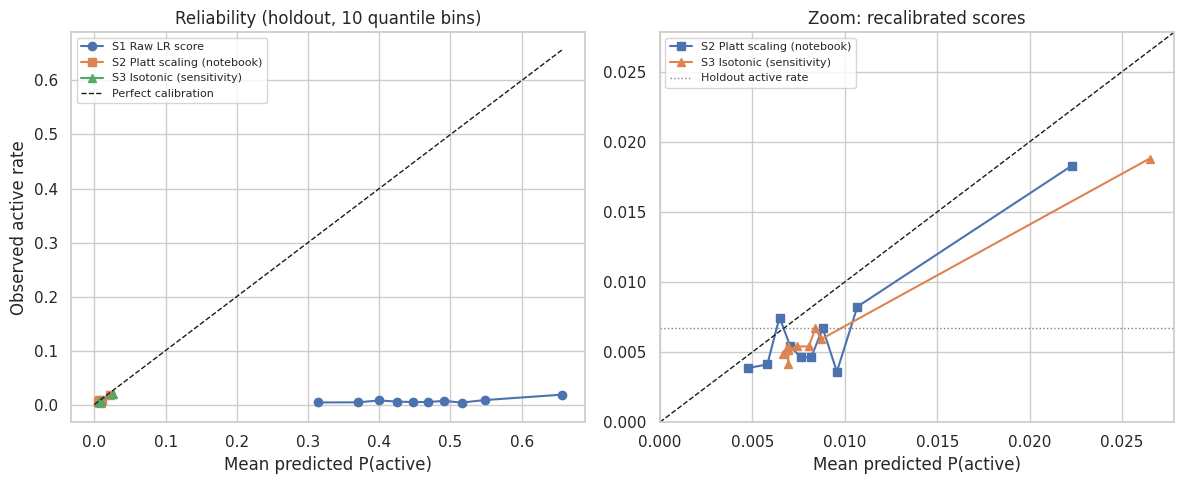


Verifikasi lolos: skor model, kalibrator Platt, dan probabilitas terkalibrasi tidak berubah.
Arsip: /content/olist_outputs/stage4_calibration.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
rel_tables = []
for name in ["S1 Raw LR score", "S2 Platt scaling (notebook)", "S3 Isotonic (sensitivity)"]:
    t = binned_stats(a_ho, scores[name])
    t.insert(0, "score", name)
    rel_tables.append(t)
reliability = pd.concat(rel_tables, ignore_index=True)
reliability.to_csv(STAGE4_DIR / "stage4_reliability_deciles_holdout.csv", index=False)
display(reliability[reliability["score"] == "S2 Platt scaling (notebook)"].round(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, marker in [("S1 Raw LR score", "o"), ("S2 Platt scaling (notebook)", "s"),
                     ("S3 Isotonic (sensitivity)", "^")]:
    t = reliability[reliability["score"] == name]
    axes[0].plot(t["mean_predicted_active"], t["observed_active_rate"], marker=marker, label=name)
lim = max(reliability["mean_predicted_active"].max(), reliability["observed_active_rate"].max())
axes[0].plot([0, lim], [0, lim], "k--", lw=1, label="Perfect calibration")
axes[0].set_xlabel("Mean predicted P(active)")
axes[0].set_ylabel("Observed active rate")
axes[0].set_title("Reliability (holdout, 10 quantile bins)")
axes[0].legend(fontsize=8)

t = reliability[reliability["score"] != "S1 Raw LR score"]
for name, marker in [("S2 Platt scaling (notebook)", "s"), ("S3 Isotonic (sensitivity)", "^")]:
    tt = t[t["score"] == name]
    axes[1].plot(tt["mean_predicted_active"], tt["observed_active_rate"], marker=marker, label=name)
lim2 = max(t["mean_predicted_active"].max(), t["observed_active_rate"].max()) * 1.05
axes[1].plot([0, lim2], [0, lim2], "k--", lw=1)
axes[1].axhline(a_ho.mean(), color="grey", lw=1, ls=":", label="Holdout active rate")
axes[1].set_xlim(0, lim2); axes[1].set_ylim(0, lim2)
axes[1].set_xlabel("Mean predicted P(active)")
axes[1].set_title("Zoom: recalibrated scores")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(STAGE4_DIR / "stage4_reliability_diagram.png", dpi=200, bbox_inches="tight")
plt.show()

# Verifikasi: skor dan kalibrator notebook tidak berubah
assert np.array_equal(_snapshot[0], np.asarray(validation_probabilities[LR]))
assert np.array_equal(_snapshot[1], np.asarray(model_probabilities[LR]))
assert np.array_equal(_snapshot[2], np.asarray(calibrated_probability))
assert np.allclose(platt_calibrator.predict_proba(to_logit(p_churn_ho))[:, 1], calibrated_probability)
print("\nVerifikasi lolos: skor model, kalibrator Platt, dan probabilitas terkalibrasi tidak berubah.")

archive4 = shutil.make_archive(str(OUTPUT_DIR / "stage4_calibration"), "zip", STAGE4_DIR)
print("Arsip:", archive4)
files.download(archive4)

#Tahap 5: Geographic Audit

#CELL 5A: Persiapan, reproduksi segmen, dan reproduksi audit asli

In [ ]:
# ============================================================
# Bagian ini BUKAN uji fairness: customer_state bukan atribut sensitif.
# Tujuannya mengukur (1) siapa yang ditandai model per state dan
# (2) apa yang berubah jika customer_state dikeluarkan dari model.
# Model utama tidak disentuh; model ablasi dilatih terpisah dengan
# protokol yang sama (tuning di development, threshold & cut-off segmen
# dari validation, refit di calibration, evaluasi sekali di holdout).
# ============================================================
import shutil
import hashlib
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             balanced_accuracy_score, matthews_corrcoef, recall_score)

required = ["trained_models", "best_model_name", "model_probabilities", "validation_probabilities",
            "model_thresholds", "holdout", "X_development_raw", "X_validation_raw",
            "X_calibration_raw", "X_holdout_raw", "y_development", "y_validation",
            "y_calibration", "y_holdout", "development_groups", "cross_validation",
            "select_threshold", "numeric_features", "categorical_features",
            "N_ITER_ML", "SEED", "OUTPUT_DIR"]
missing = [n for n in required if n not in globals()]
if missing:
    raise NameError("Jalankan notebook v4 sampai selesai dulu. Belum ada: " + ", ".join(missing))

STAGE5_DIR = OUTPUT_DIR / "stage5_geographic_audit"
STAGE5_DIR.mkdir(parents=True, exist_ok=True)

LR = best_model_name
main_pipeline = trained_models[LR]
main_ho = np.asarray(model_probabilities[LR], dtype=float)
main_val = np.asarray(validation_probabilities[LR], dtype=float)
main_thr = float(model_thresholds[LR])
y_ho = np.asarray(y_holdout)
y_val = np.asarray(y_validation)
state = holdout["customer_state"].astype(str).values          # posisi sama dengan y_holdout
assert len(state) == len(y_ho)


def fingerprint(pipeline):
    clf = pipeline.named_steps["classifier"]
    return hashlib.sha256(clf.coef_.tobytes() + clf.intercept_.tobytes()).hexdigest()


fp_before = fingerprint(main_pipeline)


def make_segments(val_score, ho_score):
    low, high = np.quantile(val_score, [0.40, 0.75])          # aturan notebook
    seg = np.select([ho_score <= low, ho_score <= high],
                    ["Relative Low Risk", "Relative Medium Risk"], default="Relative High Risk")
    return seg, low, high


main_seg, main_low, main_high = make_segments(main_val, main_ho)
seg_counts = pd.Series(main_seg).value_counts()
assert seg_counts.to_dict() == {"Relative Medium Risk": 14808, "Relative Low Risk": 13887,
                                "Relative High Risk": 10143}, seg_counts
print("Segmen model utama sesuai artikel. Cut-off:", round(main_low, 4), round(main_high, 4))

MIN_CUSTOMERS, MIN_ACTIVE = 500, 5                            # kriteria inklusi notebook


def state_performance(score, threshold):
    rows = []
    for s in np.unique(state):
        m = state == s
        a = y_ho[m]
        if m.sum() < MIN_CUSTOMERS or (a == 0).sum() < MIN_ACTIVE or len(np.unique(a)) < 2:
            continue
        pred = (score[m] >= threshold).astype(int)
        rows.append({
            "customer_state": s, "total_customers": int(m.sum()),
            "active_customers": int((a == 0).sum()),
            "balanced_accuracy": balanced_accuracy_score(a, pred),
            "recall_active": recall_score(a, pred, pos_label=0, zero_division=0),
            "roc_auc": roc_auc_score(a, score[m]),
            "pr_auc_active": average_precision_score(1 - a, 1 - score[m]),
        })
    return pd.DataFrame(rows).sort_values("total_customers", ascending=False).reset_index(drop=True)


main_perf = state_performance(main_ho, main_thr)
orig_file = OUTPUT_DIR / "geographic_performance_audit.csv"
if orig_file.exists():
    orig = pd.read_csv(orig_file)
    chk = main_perf.merge(orig, on="customer_state", suffixes=("", "_orig"))
    assert len(chk) == len(orig) == len(main_perf), "Daftar state berbeda dari audit asli."
    diff = max((chk[c] - chk[c + "_orig"]).abs().max()
               for c in ["balanced_accuracy", "recall_active", "roc_auc", "pr_auc_active"])
    print("Selisih maksimum vs geographic_performance_audit.csv:", diff)
    assert diff < 1e-9
INCLUDED_STATES = list(main_perf["customer_state"])
print("State yang memenuhi kriteria:", INCLUDED_STATES)

Segmen model utama sesuai artikel. Cut-off: 0.511 0.5962
Selisih maksimum vs geographic_performance_audit.csv: 9.540979117872439e-17
State yang memenuhi kriteria: ['SP', 'RJ', 'MG', 'RS', 'PR', 'SC', 'BA', 'DF', 'GO', 'ES']


#CELL 5B: Selection rate per state untuk model utama

In [ ]:
# ============================================================
# "Selection" = cara model memperlakukan pelanggan dalam keputusan:
#   share_high_risk     : masuk Relative High Risk (cut-off validation)
#   share_low_risk      : masuk Relative Low Risk
#   share_top10_return  : masuk 10% skor churn TERENDAH (prioritas re-engagement)
#   share_pred_active   : diprediksi aktif pada threshold validation
# Dibandingkan dengan laju aktif teramati (label) per state.
# CI proporsi: Wilson 95%.
# ============================================================
def wilson(k, n, z=1.959964):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half


def selection_table(score, threshold, seg, label):
    top10_cut = np.quantile(score, 0.10)                      # 10% skor churn terendah
    rows = []
    groups = [("ALL HOLDOUT", np.ones(len(state), bool))] + \
             [(s, state == s) for s in sorted(np.unique(state))]
    for s, m in groups:
        n = int(m.sum())
        row = {"model": label, "customer_state": s, "n_customers": n,
               "included_in_audit": (s in INCLUDED_STATES) or s == "ALL HOLDOUT",
               "mean_churn_score": score[m].mean()}
        for name, flag in [("high_risk", seg[m] == "Relative High Risk"),
                           ("low_risk", seg[m] == "Relative Low Risk"),
                           ("top10_return", score[m] <= top10_cut),
                           ("pred_active", score[m] < threshold)]:
            k = int(flag.sum())
            lo, hi = wilson(k, n)
            row[f"share_{name}"] = k / n
            row[f"share_{name}_ci_low"], row[f"share_{name}_ci_high"] = lo, hi
        k_act = int((y_ho[m] == 0).sum())
        lo, hi = wilson(k_act, n)
        row.update({"observed_active_n": k_act, "observed_active_rate": k_act / n,
                    "observed_active_ci_low": lo, "observed_active_ci_high": hi})
        rows.append(row)
    t = pd.DataFrame(rows)
    overall = t.loc[t["customer_state"] == "ALL HOLDOUT"].iloc[0]
    for name in ["high_risk", "low_risk", "top10_return", "pred_active"]:
        t[f"ratio_{name}_vs_overall"] = t[f"share_{name}"] / overall[f"share_{name}"]
    return t


main_sel = selection_table(main_ho, main_thr, main_seg, "Main LR (with customer_state)")
main_sel.to_csv(STAGE5_DIR / "stage5_selection_rates_main.csv", index=False)
show = ["customer_state", "n_customers", "share_high_risk", "share_high_risk_ci_low",
        "share_high_risk_ci_high", "share_top10_return", "share_pred_active",
        "observed_active_rate", "ratio_high_risk_vs_overall"]
display(main_sel[main_sel["included_in_audit"]][show].round(4))


def dispersion(sel, col):
    t = sel[(sel["included_in_audit"]) & (sel["customer_state"] != "ALL HOLDOUT")][col]
    return {"min": t.min(), "max": t.max(), "max_min_ratio": t.max() / t.min() if t.min() > 0 else np.nan,
            "range": t.max() - t.min(), "coef_variation": t.std() / t.mean()}

,customer_state,n_customers,share_high_risk,share_high_risk_ci_low,share_high_risk_ci_high,share_top10_return,share_pred_active,observed_active_rate,ratio_high_risk_vs_overall
0,ALL HOLDOUT,38838,0.2612,0.2568,0.2656,0.1000,0.1197,0.0067,1.0000
5,BA,1289,0.4934,0.4662,0.5207,0.0295,0.0334,0.0070,1.8893
7,DF,845,0.6698,0.6374,0.7007,0.0260,0.0296,0.0083,2.5648
8,ES,789,0.4436,0.4093,0.4785,0.0342,0.0393,0.0063,1.6986
9,GO,810,0.3272,0.2957,0.3602,0.0420,0.0494,0.0086,1.2527
11,MG,4595,0.2733,0.2606,0.2864,0.0664,0.0847,0.0048,1.0466
18,PR,1989,0.3434,0.3228,0.3645,0.0503,0.0588,0.0065,1.3149
19,RJ,4843,0.2587,0.2466,0.2712,0.0968,0.1177,0.0064,0.9907
23,RS,2063,0.2904,0.2712,0.3103,0.0693,0.0790,0.0034,1.1118
24,SC,1456,0.3001,0.2771,0.3242,0.0591,0.0742,0.0082,1.1492


#CELL 5C: Ablasi, yaitu LR tanpa customer_state dengan protokol yang sama

In [ ]:
# ============================================================
ABL_CATEGORICAL = [c for c in categorical_features if c != "customer_state"]
ABL_FEATURES = list(numeric_features) + ABL_CATEGORICAL
print("Fitur ablasi:", ABL_FEATURES)


def make_ablation_preprocessor():
    encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01,
                            sparse_output=False)                # sama dengan make_preprocessor()
    return ColumnTransformer([
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                              ("scaler", StandardScaler())]), list(numeric_features)),
        ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                  ("onehot", encoder)]), ABL_CATEGORICAL),
    ])


abl_search = RandomizedSearchCV(
    estimator=Pipeline([("preprocessor", make_ablation_preprocessor()),
                        ("classifier", LogisticRegression(random_state=SEED))]),
    param_distributions={"classifier__C": np.logspace(-3, 2, 20),
                         "classifier__class_weight": ["balanced"],
                         "classifier__solver": ["lbfgs"], "classifier__max_iter": [2000]},
    n_iter=N_ITER_ML, scoring="roc_auc", cv=cross_validation,
    random_state=SEED, n_jobs=-1, refit=True,
)
abl_search.fit(X_development_raw[ABL_FEATURES], y_development, groups=development_groups)
abl_val = abl_search.best_estimator_.predict_proba(X_validation_raw[ABL_FEATURES])[:, 1]
abl_thr, _ = select_threshold(y_val, abl_val)
abl_model = clone(abl_search.best_estimator_).fit(X_calibration_raw[ABL_FEATURES], y_calibration)
abl_ho = abl_model.predict_proba(X_holdout_raw[ABL_FEATURES])[:, 1]
abl_seg, abl_low, abl_high = make_segments(abl_val, abl_ho)
print(f"Ablasi: C = {abl_search.best_params_['classifier__C']:.4g}, "
      f"CV ROC-AUC = {abl_search.best_score_:.4f}, threshold = {abl_thr:.3f}, "
      f"cut-off segmen = {abl_low:.4f}/{abl_high:.4f}")


def active_at_k(actual, score, k_fraction):
    active = (np.asarray(actual) == 0).astype(float)
    k = int(round(k_fraction * len(score)))
    cutoff = np.partition(score, k - 1)[k - 1]
    below, at = score < cutoff, score == cutoff
    return (active[below].sum() + (k - below.sum()) / at.sum() * active[at].sum()) / k


def overall_metrics(actual, score, thr):
    pred = (score >= thr).astype(int)
    return {"roc_auc": roc_auc_score(actual, score),
            "pr_auc_active": average_precision_score(1 - actual, 1 - score),
            "mcc": matthews_corrcoef(actual, pred),
            "balanced_accuracy": balanced_accuracy_score(actual, pred),
            "recall_active": recall_score(actual, pred, pos_label=0, zero_division=0),
            "precision_at_10pct": active_at_k(actual, score, 0.10)}


overall = pd.DataFrame([
    {"model": "Main LR (with customer_state)", "evaluation_set": "Validation", **overall_metrics(y_val, main_val, main_thr)},
    {"model": "Ablation LR (without customer_state)", "evaluation_set": "Validation", **overall_metrics(y_val, abl_val, abl_thr)},
    {"model": "Main LR (with customer_state)", "evaluation_set": "Holdout", **overall_metrics(y_ho, main_ho, main_thr)},
    {"model": "Ablation LR (without customer_state)", "evaluation_set": "Holdout", **overall_metrics(y_ho, abl_ho, abl_thr)},
])
overall.to_csv(STAGE5_DIR / "stage5_ablation_overall_metrics.csv", index=False)
display(overall.round(4))

# Paired bootstrap holdout: main minus ablation
N_BOOT_5 = 1000
rng5 = np.random.default_rng(SEED + 50)
recs = []
for b in range(N_BOOT_5):
    idx = rng5.choice(len(y_ho), size=len(y_ho), replace=True)
    a = y_ho[idx]
    if len(np.unique(a)) < 2:
        continue
    mm, aa = overall_metrics(a, main_ho[idx], main_thr), overall_metrics(a, abl_ho[idx], abl_thr)
    recs.append({k: mm[k] - aa[k] for k in mm})
recs = pd.DataFrame(recs)
pt_main = overall.query("evaluation_set == 'Holdout'").iloc[0]
pt_abl = overall.query("evaluation_set == 'Holdout'").iloc[1]
paired = pd.DataFrame([{
    "metric": k, "main": pt_main[k], "ablation": pt_abl[k], "difference_main_minus_ablation": pt_main[k] - pt_abl[k],
    "ci_2_5": recs[k].quantile(0.025), "ci_97_5": recs[k].quantile(0.975),
    "share_main_better": (recs[k] > 0).mean(),
    "ci_excludes_zero": (recs[k].quantile(0.025) > 0) or (recs[k].quantile(0.975) < 0),
} for k in recs.columns])
paired.to_csv(STAGE5_DIR / "stage5_ablation_paired_bootstrap.csv", index=False)
display(paired.round(4))

Fitur ablasi: ['recency_days', 'total_orders', 'total_spend', 'average_order_value', 'avg_days_between_orders', 'single_order_flag', 'avg_review_score', 'total_reviews', 'average_items_per_order', 'total_categories', 'active_span_days', 'favorite_category', 'payment_method']
Ablasi: C = 0.1274, CV ROC-AUC = 0.6074, threshold = 0.415, cut-off segmen = 0.5083/0.6023


,model,evaluation_set,roc_auc,pr_auc_active,mcc,balanced_accuracy,recall_active,precision_at_10pct
0,Main LR (with customer_state),Validation,0.5824,0.0250,0.0368,0.5706,0.2932,0.0208
1,Ablation LR (without customer_state),Validation,0.5913,0.0265,0.0467,0.5798,0.2749,0.0226
2,Main LR (with customer_state),Holdout,0.6136,0.0195,0.0446,0.5888,0.2962,0.0183
3,Ablation LR (without customer_state),Holdout,0.6103,0.0201,0.0466,0.5786,0.2385,0.0183


,metric,main,ablation,difference_main_minus_ablation,ci_2_5,ci_97_5,share_main_better,ci_excludes_zero
0,roc_auc,0.6136,0.6103,0.0033,-0.0092,0.0160,0.693,False
1,pr_auc_active,0.0195,0.0201,-0.0006,-0.0041,0.0008,0.358,False
2,mcc,0.0446,0.0466,-0.0020,-0.0116,0.0083,0.335,False
3,balanced_accuracy,0.5888,0.5786,0.0102,-0.0075,0.0285,0.871,False
4,recall_active,0.2962,0.2385,0.0577,0.0217,0.0941,1.000,True
5,precision_at_10pct,0.0183,0.0183,0.0000,-0.0021,0.0021,0.431,False


#CELL 5D: Perbandingan per state, perpindahan segmen, verifikasi, dan arsip

In [ ]:
# ============================================================
abl_perf = state_performance(abl_ho, abl_thr)
perf_cmp = main_perf.merge(abl_perf, on=["customer_state", "total_customers", "active_customers"],
                           suffixes=("_main", "_ablation"))
for c in ["balanced_accuracy", "recall_active", "roc_auc", "pr_auc_active"]:
    perf_cmp[f"{c}_change"] = perf_cmp[f"{c}_ablation"] - perf_cmp[f"{c}_main"]
perf_cmp.to_csv(STAGE5_DIR / "stage5_state_performance_main_vs_ablation.csv", index=False)
display(perf_cmp.round(4))

abl_sel = selection_table(abl_ho, abl_thr, abl_seg, "Ablation LR (without customer_state)")
abl_sel.to_csv(STAGE5_DIR / "stage5_selection_rates_ablation.csv", index=False)

sel_cmp = main_sel[["customer_state", "n_customers", "included_in_audit", "observed_active_rate",
                    "share_high_risk", "share_top10_return", "share_pred_active"]].merge(
    abl_sel[["customer_state", "share_high_risk", "share_top10_return", "share_pred_active"]],
    on="customer_state", suffixes=("_main", "_ablation"))
for c in ["share_high_risk", "share_top10_return", "share_pred_active"]:
    sel_cmp[f"{c}_change_pp"] = 100 * (sel_cmp[f"{c}_ablation"] - sel_cmp[f"{c}_main"])
sel_cmp.to_csv(STAGE5_DIR / "stage5_selection_rates_main_vs_ablation.csv", index=False)
display(sel_cmp[sel_cmp["included_in_audit"]].round(4))

disp_rows = []
for label, sel in [("Main LR (with customer_state)", main_sel), ("Ablation LR (without customer_state)", abl_sel)]:
    for col in ["share_high_risk", "share_top10_return", "share_pred_active"]:
        disp_rows.append({"model": label, "quantity": col, **dispersion(sel, col)})
disp_rows.append({"model": "Observed (labels)", "quantity": "observed_active_rate",
                  **dispersion(main_sel, "observed_active_rate")})
disp = pd.DataFrame(disp_rows)
disp.to_csv(STAGE5_DIR / "stage5_selection_dispersion_across_states.csv", index=False)
print("\nSebaran antar state (hanya state yang memenuhi kriteria):")
display(disp.round(4))

order = ["Relative Low Risk", "Relative Medium Risk", "Relative High Risk"]
transition = pd.crosstab(pd.Series(main_seg, name="segment_main"),
                         pd.Series(abl_seg, name="segment_ablation")).reindex(index=order, columns=order)
transition.to_csv(STAGE5_DIR / "stage5_segment_transition_main_vs_ablation.csv")
moved = 1 - np.trace(transition.values) / transition.values.sum()
print(f"\nPelanggan yang berpindah segmen setelah ablasi: {moved:.1%}")
display(transition)

seg_dist = pd.DataFrame({"main": pd.Series(main_seg).value_counts(),
                         "ablation": pd.Series(abl_seg).value_counts()}).reindex(order)
seg_dist.to_csv(STAGE5_DIR / "stage5_segment_distribution.csv")
display(seg_dist)

# ---- Verifikasi + arsip ------------------------------------------------
assert fingerprint(main_pipeline) == fp_before, "Model utama berubah!"
assert np.allclose(main_pipeline.predict_proba(X_holdout_raw)[:, 1], main_ho), "Skor holdout berubah!"
assert np.array_equal(np.asarray(model_probabilities[LR]), main_ho)
print("\nVerifikasi lolos: model utama dan skor holdout tidak berubah.")

archive5 = shutil.make_archive(str(OUTPUT_DIR / "stage5_geographic_audit"), "zip", STAGE5_DIR)
print("Arsip:", archive5)
files.download(archive5)

,customer_state,total_customers,active_customers,balanced_accuracy_main,recall_active_main,roc_auc_main,pr_auc_active_main,balanced_accuracy_ablation,recall_active_ablation,roc_auc_ablation,pr_auc_active_ablation,balanced_accuracy_change,recall_active_change,roc_auc_change,pr_auc_active_change
0,SP,16625,133,0.5980,0.3759,0.6121,0.0232,0.5811,0.2556,0.6114,0.0239,-0.0169,-0.1203,-0.0007,0.0007
1,RJ,4843,31,0.6031,0.3226,0.5410,0.0291,0.5915,0.2581,0.5409,0.0286,-0.0116,-0.0645,-0.0002,-0.0005
2,MG,4595,22,0.5945,0.2727,0.5451,0.0089,0.5726,0.2273,0.5516,0.0087,-0.0219,-0.0455,0.0065,-0.0002
3,RS,2063,7,0.6754,0.4286,0.7280,0.0826,0.6737,0.4286,0.7080,0.0841,-0.0017,0.0000,-0.0199,0.0016
4,PR,1989,13,0.5478,0.1538,0.5030,0.0150,0.5397,0.1538,0.5122,0.0174,-0.0081,0.0000,0.0092,0.0024
5,SC,1456,12,0.5886,0.2500,0.7329,0.0241,0.5880,0.2500,0.7065,0.0222,-0.0007,0.0000,-0.0264,-0.0019
6,BA,1289,9,0.5391,0.1111,0.7905,0.0361,0.6346,0.3333,0.7809,0.0357,0.0955,0.2222,-0.0096,-0.0004
7,DF,845,7,0.4851,0.0000,0.4870,0.0125,0.5320,0.1429,0.4847,0.0119,0.0470,0.1429,-0.0024,-0.0006
8,GO,810,7,0.4751,0.0000,0.7870,0.0325,0.5428,0.1429,0.7917,0.0320,0.0677,0.1429,0.0046,-0.0005
9,ES,789,5,0.4802,0.0000,0.5663,0.0082,0.4681,0.0000,0.5462,0.0078,-0.0121,0.0000,-0.0202,-0.0004


,customer_state,n_customers,included_in_audit,observed_active_rate,share_high_risk_main,share_top10_return_main,share_pred_active_main,share_high_risk_ablation,share_top10_return_ablation,share_pred_active_ablation,share_high_risk_change_pp,share_top10_return_change_pp,share_pred_active_change_pp
0,ALL HOLDOUT,38838,True,0.0067,0.2612,0.1000,0.1197,0.2631,0.1000,0.0823,0.1957,0.0000,-3.7386
5,BA,1289,True,0.0070,0.4934,0.0295,0.0334,0.3251,0.0760,0.0659,-16.8348,4.6548,3.2583
7,DF,845,True,0.0083,0.6698,0.0260,0.0296,0.2876,0.0935,0.0793,-38.2249,6.7456,4.9704
8,ES,789,True,0.0063,0.4436,0.0342,0.0393,0.2763,0.0837,0.0634,-16.7300,4.9430,2.4081
9,GO,810,True,0.0086,0.3272,0.0420,0.0494,0.2667,0.0778,0.0580,-6.0494,3.5802,0.8642
11,MG,4595,True,0.0048,0.2733,0.0664,0.0847,0.2598,0.1010,0.0827,-1.3493,3.4603,-0.1959
18,PR,1989,True,0.0065,0.3434,0.0503,0.0588,0.2499,0.0940,0.0749,-9.3514,4.3741,1.6088
19,RJ,4843,True,0.0064,0.2587,0.0968,0.1177,0.3097,0.0921,0.0762,5.1001,-0.4749,-4.1503
23,RS,2063,True,0.0034,0.2904,0.0693,0.0790,0.2661,0.0999,0.0824,-2.4237,3.0538,0.3393
24,SC,1456,True,0.0082,0.3001,0.0591,0.0742,0.2782,0.0879,0.0755,-2.1978,2.8846,0.1374



Sebaran antar state (hanya state yang memenuhi kriteria):


,model,quantity,min,max,max_min_ratio,range,coef_variation
0,Main LR (with customer_state),share_high_risk,0.1409,0.6698,4.7548,0.5290,0.4168
1,Main LR (with customer_state),share_top10_return,0.0260,0.1527,5.8636,0.1266,0.6109
2,Main LR (with customer_state),share_pred_active,0.0296,0.1816,6.1379,0.1520,0.6192
3,Ablation LR (without customer_state),share_high_risk,0.2306,0.3251,1.4095,0.0944,0.1004
4,Ablation LR (without customer_state),share_top10_return,0.0760,0.1145,1.5064,0.0385,0.1255
5,Ablation LR (without customer_state),share_pred_active,0.0580,0.0947,1.6327,0.0367,0.1419
6,Observed (labels),observed_active_rate,0.0034,0.0086,2.5469,0.0052,0.2477



Pelanggan yang berpindah segmen setelah ablasi: 19.3%


segment_ablation,Relative Low Risk,Relative Medium Risk,Relative High Risk
segment_main,,,
Relative Low Risk,11899,1977,11
Relative Medium Risk,1724,11154,1930
Relative High Risk,63,1802,8278


,main,ablation
Relative Low Risk,13887,13686
Relative Medium Risk,14808,14933
Relative High Risk,10143,10219



Verifikasi lolos: model utama dan skor holdout tidak berubah.
Arsip: /content/olist_outputs/stage5_geographic_audit.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## TAHAP 6 — LABEL INTEGRITY

#CELL 6A: Persiapan, inventaris status, dan reproduksi label notebook

In [ ]:
# ============================================================
# Label notebook: is_churn = 0 jika pelanggan punya order DELIVERED
# (dari tabel `fact`) dengan order_purchase_timestamp di [cutoff, cutoff+90 hari).
# Tahap ini memeriksa order NON-delivered di jendela label dan membangun
# label alternatif. FITUR TIDAK DIUBAH (tetap dari order delivered), agar
# efek perubahan label dapat diisolasi. Model utama tidak disentuh.
# ============================================================
import shutil
import hashlib
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             balanced_accuracy_score, matthews_corrcoef, recall_score)

required = ["orders", "customers", "fact", "calibration", "holdout", "y_calibration", "y_holdout",
            "development_index", "validation_index", "development_groups", "X_development_raw",
            "X_validation_raw", "X_calibration_raw", "X_holdout_raw", "trained_models",
            "best_model_name", "model_probabilities", "model_thresholds", "make_preprocessor",
            "select_threshold", "cross_validation", "N_ITER_ML", "SEED", "OUTPUT_DIR"]
missing = [n for n in required if n not in globals()]
if missing:
    raise NameError("Jalankan notebook v4 sampai selesai dulu. Belum ada: " + ", ".join(missing))

STAGE6_DIR = OUTPUT_DIR / "stage6_label_integrity"
STAGE6_DIR.mkdir(parents=True, exist_ok=True)

LR = best_model_name
main_pipeline = trained_models[LR]
main_ho = np.asarray(model_probabilities[LR], dtype=float)
main_thr = float(model_thresholds[LR])
fp_before = hashlib.sha256(main_pipeline.named_steps["classifier"].coef_.tobytes()).hexdigest()

LABEL_DAYS = 90

# ---- Tabel order mentah dengan customer_unique_id ----------------------
raw = orders.merge(customers[["customer_id", "customer_unique_id"]], on="customer_id", how="left")
raw = raw[raw["customer_unique_id"].notna() & raw["order_purchase_timestamp"].notna()].copy()
print("Rentang order_purchase_timestamp (semua status):",
      raw["order_purchase_timestamp"].min(), "->", raw["order_purchase_timestamp"].max())
print("Rentang order_purchase_timestamp (fact, delivered):",
      fact["order_purchase_timestamp"].min(), "->", fact["order_purchase_timestamp"].max())

# Status per bulan pembelian (2018) untuk melihat ekor data
raw["purchase_month"] = raw["order_purchase_timestamp"].dt.to_period("M").astype(str)
status_by_month = pd.crosstab(raw["purchase_month"], raw["order_status"])
status_by_month["non_delivered_share"] = 1 - status_by_month.get("delivered", 0) / status_by_month.sum(axis=1)
status_by_month.to_csv(STAGE6_DIR / "stage6_status_by_purchase_month.csv")
display(status_by_month.loc[status_by_month.index >= "2017-12"].round(4))

# Delivered di data mentah yang tidak masuk `fact` (nilai order hilang, dll.)
delivered_raw_ids = set(raw.loc[raw["order_status"] == "delivered", "order_id"])
dropped_delivered = len(delivered_raw_ids - set(fact["order_id"]))
print("Order delivered mentah yang tidak masuk fact:", dropped_delivered)

# ---- Jendela label untuk setiap snapshot ----------------------------------
cal_cutoffs = pd.to_datetime(calibration["snapshot_date"]).values
ho_cutoffs = pd.to_datetime(holdout["snapshot_date"]).values
CUTOFFS = sorted(set(pd.to_datetime(np.r_[cal_cutoffs, ho_cutoffs])))
print("Cutoff:", [str(pd.Timestamp(c).date()) for c in CUTOFFS])


def returning_customers(order_table, cutoff):
    start = pd.Timestamp(cutoff)
    end = start + pd.Timedelta(days=LABEL_DAYS)
    w = order_table[(order_table["order_purchase_timestamp"] >= start) &
                    (order_table["order_purchase_timestamp"] < end)]
    return set(w["customer_unique_id"].unique())


def relabel(frame, order_table):
    """is_churn untuk setiap baris snapshot berdasarkan order_table."""
    out = np.empty(len(frame), dtype=int)
    cut = pd.to_datetime(frame["snapshot_date"]).values
    ids = frame["customer_unique_id"].values
    for c in np.unique(cut):
        m = cut == c
        ret = returning_customers(order_table, c)
        out[m] = (~pd.Series(ids[m]).isin(ret)).astype(int).values
    return out


# Reproduksi label notebook dari `fact` (harus identik)
L0_cal = relabel(calibration, fact)
L0_ho = relabel(holdout, fact)
assert np.array_equal(L0_cal, np.asarray(y_calibration)), "Label calibration tidak tereproduksi."
assert np.array_equal(L0_ho, np.asarray(y_holdout)), "Label holdout tidak tereproduksi."
print("Label notebook (delivered only) tereproduksi untuk calibration dan holdout.")

# ---- Inventaris status di setiap jendela label ---------------------------
inv_rows = []
for c in CUTOFFS:
    start, end = pd.Timestamp(c), pd.Timestamp(c) + pd.Timedelta(days=LABEL_DAYS)
    w = raw[(raw["order_purchase_timestamp"] >= start) & (raw["order_purchase_timestamp"] < end)]
    row = {"cutoff": start.date(), "label_end_exclusive": end.date(),
           "role": "holdout" if start == pd.Timestamp(ho_cutoffs[0]) else "calibration",
           "orders_all_status": len(w)}
    row.update(w["order_status"].value_counts().to_dict())
    inv_rows.append(row)
inventory = pd.DataFrame(inv_rows).fillna(0)
inventory.to_csv(STAGE6_DIR / "stage6_status_inventory_by_label_window.csv", index=False)
display(inventory)

Rentang order_purchase_timestamp (semua status): 2016-09-04 21:15:19 -> 2018-10-17 17:30:18
Rentang order_purchase_timestamp (fact, delivered): 2016-09-15 12:16:38 -> 2018-08-29 15:00:37


order_status,approved,canceled,created,delivered,invoiced,processing,shipped,unavailable,non_delivered_share
purchase_month,,,,,,,,,
2017-12,0,11,2,5513,13,35,57,42,0.0282
2018-01,0,34,0,7069,15,29,74,48,0.0275
2018-02,0,73,1,6555,6,6,57,30,0.0257
2018-03,0,26,0,7003,23,9,133,17,0.0288
2018-04,0,15,0,6798,14,8,99,5,0.0203
2018-05,0,24,0,6749,24,6,54,16,0.0180
2018-06,0,18,0,6099,3,0,43,4,0.0110
2018-07,0,41,0,6159,13,1,60,18,0.0211
2018-08,0,84,0,6351,23,0,47,7,0.0247


Order delivered mentah yang tidak masuk fact: 0
Cutoff: ['2017-07-01', '2017-08-01', '2017-09-01', '2017-10-01', '2017-11-01', '2017-12-01', '2018-01-01', '2018-02-01', '2018-03-01', '2018-06-01']
Label notebook (delivered only) tereproduksi untuk calibration dan holdout.


,cutoff,label_end_exclusive,role,orders_all_status,delivered,shipped,unavailable,canceled,processing,invoiced,created
0,2017-07-01,2017-09-29,calibration,12412,12001,129,117,75,49,41,0.0
1,2017-08-01,2017-10-30,calibration,12938,12527,111,120,72,57,51,0.0
2,2017-09-01,2017-11-30,calibration,16193,15657,141,177,83,66,67,2.0
3,2017-10-01,2017-12-30,calibration,17677,17113,160,183,73,80,64,4.0
4,2017-11-01,2018-01-30,calibration,19972,19372,199,172,73,89,63,4.0
5,2017-12-01,2018-03-01,calibration,19670,19137,188,120,118,70,34,3.0
6,2018-01-01,2018-04-01,calibration,21208,20627,264,95,133,44,44,1.0
7,2018-02-01,2018-05-02,calibration,21134,20608,291,53,115,23,43,1.0
8,2018-03-01,2018-05-30,calibration,20750,20280,283,38,65,23,61,0.0
9,2018-06-01,2018-08-30,holdout,18966,18609,150,29,138,1,39,0.0


#CELL 6B: Label alternatif dan perpindahan label

In [ ]:
# ============================================================
# L0 (notebook)   : delivered (dari `fact`)
# L1 (utama alt.) : L0 + order non-canceled yang relevan:
#                   shipped, invoiced, processing, approved, created
#                   (dikeluarkan: canceled, unavailable)
# L2 (sensitivitas): L0 + shipped + invoiced (order yang sudah melewati
#                   tahap penagihan/pengiriman)
# Hanya pelanggan yang SUDAH ada di snapshot yang dinilai; fitur tetap.
# ============================================================
L1_EXTRA = ["shipped", "invoiced", "processing", "approved", "created"]
L2_EXTRA = ["shipped", "invoiced"]
base_orders = fact[["customer_unique_id", "order_purchase_timestamp"]]


def order_table_with(extra_status):
    extra = raw.loc[raw["order_status"].isin(extra_status),
                    ["customer_unique_id", "order_purchase_timestamp"]]
    return pd.concat([base_orders, extra], ignore_index=True)


LABELS = {
    "L0 delivered only (notebook)": (L0_cal, L0_ho),
    "L1 + non-canceled relevant": (relabel(calibration, order_table_with(L1_EXTRA)),
                                   relabel(holdout, order_table_with(L1_EXTRA))),
    "L2 + shipped/invoiced": (relabel(calibration, order_table_with(L2_EXTRA)),
                              relabel(holdout, order_table_with(L2_EXTRA))),
}

# Sifat definisi: label alternatif hanya bisa memindahkan churn -> aktif
for name, (lc, lh) in LABELS.items():
    assert np.all(lc <= L0_cal) and np.all(lh <= L0_ho), name

y_dev_idx, y_val_idx = np.asarray(development_index), np.asarray(validation_index)
prev_rows = []
for name, (lc, lh) in LABELS.items():
    for subset, lab, base in [("Calibration", lc, L0_cal), ("Development", lc[y_dev_idx], L0_cal[y_dev_idx]),
                              ("Validation", lc[y_val_idx], L0_cal[y_val_idx]), ("Holdout", lh, L0_ho)]:
        prev_rows.append({"label": name, "subset": subset, "n": len(lab),
                          "active_n": int((lab == 0).sum()), "active_rate": (lab == 0).mean(),
                          "flipped_churn_to_active": int((base - lab).sum()),
                          "flipped_share_of_new_actives": (base - lab).sum() / max((lab == 0).sum(), 1)})
prevalence = pd.DataFrame(prev_rows)
prevalence.to_csv(STAGE6_DIR / "stage6_prevalence_by_label_definition.csv", index=False)
display(prevalence.round(5))

# Laju aktif per cutoff (apakah penurunan 0,89% -> 0,67% berubah?)
per_cut = []
all_frame = pd.concat([calibration[["snapshot_date"]].assign(role="calibration"),
                       holdout[["snapshot_date"]].assign(role="holdout")], ignore_index=True)
for name, (lc, lh) in LABELS.items():
    lab = np.r_[lc, lh]
    t = all_frame.assign(active=(lab == 0)).groupby(["snapshot_date", "role"])["active"].agg(["size", "sum", "mean"])
    t = t.reset_index().rename(columns={"size": "n", "sum": "active_n", "mean": "active_rate"})
    t.insert(0, "label", name)
    per_cut.append(t)
per_cutoff = pd.concat(per_cut, ignore_index=True)
per_cutoff.to_csv(STAGE6_DIR / "stage6_active_rate_by_cutoff.csv", index=False)
display(per_cutoff.pivot_table(index="snapshot_date", columns="label", values="active_rate").round(5))

# Siapa yang berpindah label di holdout, dan bagaimana model memeringkat mereka?
lh1 = LABELS["L1 + non-canceled relevant"][1]
flip_mask = (L0_ho == 1) & (lh1 == 0)
pct_rank = pd.Series(main_ho).rank(pct=True).values          # 0 = skor churn terendah
flip_profile = pd.DataFrame({
    "group": ["Flipped churn->active (L1)", "Active under L0", "Churn under both"],
    "n": [flip_mask.sum(), (L0_ho == 0).sum(), ((L0_ho == 1) & (lh1 == 1)).sum()],
    "mean_churn_score_percentile": [pct_rank[flip_mask].mean() if flip_mask.any() else np.nan,
                                    pct_rank[L0_ho == 0].mean(),
                                    pct_rank[(L0_ho == 1) & (lh1 == 1)].mean()],
    "share_in_lowest_risk_decile": [(pct_rank[flip_mask] <= 0.10).mean() if flip_mask.any() else np.nan,
                                    (pct_rank[L0_ho == 0] <= 0.10).mean(),
                                    (pct_rank[(L0_ho == 1) & (lh1 == 1)] <= 0.10).mean()],
})
flip_profile.to_csv(STAGE6_DIR / "stage6_holdout_flipped_customer_profile.csv", index=False)
display(flip_profile.round(4))

if flip_mask.any():
    flipped_ids = set(holdout.loc[flip_mask, "customer_unique_id"])
    ho_start = pd.Timestamp(ho_cutoffs[0])
    fw = raw[raw["customer_unique_id"].isin(flipped_ids) &
             (raw["order_purchase_timestamp"] >= ho_start) &
             (raw["order_purchase_timestamp"] < ho_start + pd.Timedelta(days=LABEL_DAYS)) &
             raw["order_status"].isin(L1_EXTRA)]
    flip_status = fw.groupby(["order_status", "purchase_month"]).size().rename("orders").reset_index()
    flip_status.to_csv(STAGE6_DIR / "stage6_holdout_flip_orders_by_status_month.csv", index=False)
    display(flip_status)

,label,subset,n,active_n,active_rate,flipped_churn_to_active,flipped_share_of_new_actives
0,L0 delivered only (notebook),Calibration,214005,1857,0.00868,0,0.00000
1,L0 delivered only (notebook),Development,171164,1475,0.00862,0,0.00000
2,L0 delivered only (notebook),Validation,42841,382,0.00892,0,0.00000
3,L0 delivered only (notebook),Holdout,38838,260,0.00669,0,0.00000
4,L1 + non-canceled relevant,Calibration,214005,1876,0.00877,19,0.01013
5,L1 + non-canceled relevant,Development,171164,1487,0.00869,12,0.00807
6,L1 + non-canceled relevant,Validation,42841,389,0.00908,7,0.01799
7,L1 + non-canceled relevant,Holdout,38838,260,0.00669,0,0.00000
8,L2 + shipped/invoiced,Calibration,214005,1871,0.00874,14,0.00748
9,L2 + shipped/invoiced,Development,171164,1485,0.00868,10,0.00673


label,L0 delivered only (notebook),L1 + non-canceled relevant,L2 + shipped/invoiced
snapshot_date,,,
2017-07-01,0.00839,0.00853,0.00853
2017-08-01,0.00835,0.00847,0.00847
2017-09-01,0.00969,0.00974,0.00974
2017-10-01,0.01003,0.01018,0.01013
2017-11-01,0.00998,0.01016,0.01011
2017-12-01,0.00882,0.00890,0.00890
2018-01-01,0.00782,0.00789,0.00786
2018-02-01,0.00774,0.00777,0.00774
2018-03-01,0.00818,0.00824,0.00821


,group,n,mean_churn_score_percentile,share_in_lowest_risk_decile
0,Flipped churn->active (L1),0,NaN,NaN
1,Active under L0,260,0.3872,0.2731
2,Churn under both,38578,0.5008,0.0988


#CELL 6C: Evaluasi model utama dengan setiap definisi label (tanpa pelatihan ulang)

In [ ]:
# ============================================================
def active_at_k(actual, score, k_fraction):
    active = (np.asarray(actual) == 0).astype(float)
    k = int(round(k_fraction * len(score)))
    cutoff = np.partition(score, k - 1)[k - 1]
    below, at = score < cutoff, score == cutoff
    return (active[below].sum() + (k - below.sum()) / at.sum() * active[at].sum()) / k


def metrics(actual, score, thr):
    pred = (score >= thr).astype(int)
    prev = (actual == 0).mean()
    pr = average_precision_score(1 - actual, 1 - score)
    return {"active_rate": prev, "roc_auc": roc_auc_score(actual, score), "pr_auc_active": pr,
            "pr_auc_lift": pr / prev, "mcc": matthews_corrcoef(actual, pred),
            "balanced_accuracy": balanced_accuracy_score(actual, pred),
            "recall_active": recall_score(actual, pred, pos_label=0, zero_division=0),
            "precision_at_10pct": active_at_k(actual, score, 0.10)}


eval_rows = [{"model": "Main LR (trained on L0)", "holdout_label": n, **metrics(lh, main_ho, main_thr)}
             for n, (_, lh) in LABELS.items()]
eval_main = pd.DataFrame(eval_rows)
eval_main.to_csv(STAGE6_DIR / "stage6_main_model_by_holdout_label.csv", index=False)
display(eval_main.round(4))

# Paired bootstrap: metrik (label L1) - metrik (label L0), skor sama
N_BOOT_6 = 1000
rng6 = np.random.default_rng(SEED + 60)
recs = []
for b in range(N_BOOT_6):
    idx = rng6.choice(len(L0_ho), size=len(L0_ho), replace=True)
    a0, a1 = L0_ho[idx], lh1[idx]
    if len(np.unique(a0)) < 2 or len(np.unique(a1)) < 2:
        continue
    m0, m1 = metrics(a0, main_ho[idx], main_thr), metrics(a1, main_ho[idx], main_thr)
    recs.append({k: m1[k] - m0[k] for k in m0})
recs = pd.DataFrame(recs)
label_effect = pd.DataFrame([{
    "metric": k, "L0": eval_main.loc[0, k], "L1": eval_main.loc[1, k],
    "difference_L1_minus_L0": eval_main.loc[1, k] - eval_main.loc[0, k],
    "ci_2_5": recs[k].quantile(0.025), "ci_97_5": recs[k].quantile(0.975),
} for k in recs.columns])
label_effect.to_csv(STAGE6_DIR / "stage6_label_effect_paired_bootstrap.csv", index=False)
display(label_effect.round(5))

,model,holdout_label,active_rate,roc_auc,pr_auc_active,pr_auc_lift,mcc,balanced_accuracy,recall_active,precision_at_10pct
0,Main LR (trained on L0),L0 delivered only (notebook),0.0067,0.6136,0.0195,2.9161,0.0446,0.5888,0.2962,0.0183
1,Main LR (trained on L0),L1 + non-canceled relevant,0.0067,0.6136,0.0195,2.9161,0.0446,0.5888,0.2962,0.0183
2,Main LR (trained on L0),L2 + shipped/invoiced,0.0067,0.6136,0.0195,2.9161,0.0446,0.5888,0.2962,0.0183


,metric,L0,L1,difference_L1_minus_L0,ci_2_5,ci_97_5
0,active_rate,0.00669,0.00669,0.0,0.0,0.0
1,roc_auc,0.61360,0.61360,0.0,0.0,0.0
2,pr_auc_active,0.01952,0.01952,0.0,0.0,0.0
3,pr_auc_lift,2.91605,2.91605,0.0,0.0,0.0
4,mcc,0.04461,0.04461,0.0,0.0,0.0
5,balanced_accuracy,0.58881,0.58881,0.0,0.0,0.0
6,recall_active,0.29615,0.29615,0.0,0.0,0.0
7,precision_at_10pct,0.01828,0.01828,0.0,0.0,0.0


#CELL 6D: Melatih ulang LR dengan label L1, perbandingan, verifikasi, dan arsip

In [ ]:
# ============================================================
# Split development/validation SAMA (indeks notebook); hanya label berubah.
# Model utama tidak disentuh.
# ============================================================
lc1 = LABELS["L1 + non-canceled relevant"][0]
y_dev_L1, y_val_L1 = lc1[y_dev_idx], lc1[y_val_idx]

search_L1 = RandomizedSearchCV(
    estimator=Pipeline([("preprocessor", make_preprocessor()),
                        ("classifier", LogisticRegression(random_state=SEED))]),
    param_distributions={"classifier__C": np.logspace(-3, 2, 20),
                         "classifier__class_weight": ["balanced"],
                         "classifier__solver": ["lbfgs"], "classifier__max_iter": [2000]},
    n_iter=N_ITER_ML, scoring="roc_auc", cv=cross_validation,
    random_state=SEED, n_jobs=-1, refit=True,
)
search_L1.fit(X_development_raw, y_dev_L1, groups=development_groups)
val_L1 = search_L1.best_estimator_.predict_proba(X_validation_raw)[:, 1]
thr_L1, _ = select_threshold(y_val_L1, val_L1)
model_L1 = clone(search_L1.best_estimator_).fit(X_calibration_raw, lc1)
ho_L1 = model_L1.predict_proba(X_holdout_raw)[:, 1]
print(f"LR-L1: C = {search_L1.best_params_['classifier__C']:.4g}, CV ROC-AUC = {search_L1.best_score_:.4f}, "
      f"threshold = {thr_L1:.3f}")

retrain = pd.DataFrame([
    {"model": "Main LR (trained on L0)", "holdout_label": "L0", **metrics(L0_ho, main_ho, main_thr)},
    {"model": "Main LR (trained on L0)", "holdout_label": "L1", **metrics(lh1, main_ho, main_thr)},
    {"model": "LR retrained on L1", "holdout_label": "L0", **metrics(L0_ho, ho_L1, thr_L1)},
    {"model": "LR retrained on L1", "holdout_label": "L1", **metrics(lh1, ho_L1, thr_L1)},
])
retrain.to_csv(STAGE6_DIR / "stage6_retrained_L1_comparison.csv", index=False)
display(retrain.round(4))

rank_corr = pd.Series(main_ho).corr(pd.Series(ho_L1), method="spearman")
top10_main = pd.Series(main_ho).rank(pct=True) <= 0.10
top10_L1 = pd.Series(ho_L1).rank(pct=True) <= 0.10
overlap = (top10_main & top10_L1).sum() / top10_main.sum()
coef_main = pd.Series(main_pipeline.named_steps["classifier"].coef_.ravel(),
                      index=main_pipeline.named_steps["preprocessor"].get_feature_names_out())
coef_L1 = pd.Series(model_L1.named_steps["classifier"].coef_.ravel(),
                    index=model_L1.named_steps["preprocessor"].get_feature_names_out())
common = coef_main.index.intersection(coef_L1.index)
agreement = pd.DataFrame([{
    "spearman_holdout_scores_main_vs_L1": rank_corr,
    "top10pct_overlap_share": overlap,
    "coef_pearson_corr": np.corrcoef(coef_main[common], coef_L1[common])[0, 1],
    "coef_sign_agreement": (np.sign(coef_main[common]) == np.sign(coef_L1[common])).mean(),
    "n_common_coefficients": len(common),
}])
agreement.to_csv(STAGE6_DIR / "stage6_main_vs_L1_model_agreement.csv", index=False)
display(agreement.round(4))

# ---- Verifikasi + arsip ------------------------------------------------
assert hashlib.sha256(main_pipeline.named_steps["classifier"].coef_.tobytes()).hexdigest() == fp_before
assert np.allclose(main_pipeline.predict_proba(X_holdout_raw)[:, 1], main_ho)
assert np.array_equal(np.asarray(y_holdout), L0_ho) and np.array_equal(np.asarray(y_calibration), L0_cal)
print("\nVerifikasi lolos: model utama, skor holdout, dan label notebook tidak berubah.")

archive6 = shutil.make_archive(str(OUTPUT_DIR / "stage6_label_integrity"), "zip", STAGE6_DIR)
print("Arsip:", archive6)
files.download(archive6)

LR-L1: C = 0.001833, CV ROC-AUC = 0.6101, threshold = 0.480


,model,holdout_label,active_rate,roc_auc,pr_auc_active,pr_auc_lift,mcc,balanced_accuracy,recall_active,precision_at_10pct
0,Main LR (trained on L0),L0,0.0067,0.6136,0.0195,2.9161,0.0446,0.5888,0.2962,0.0183
1,Main LR (trained on L0),L1,0.0067,0.6136,0.0195,2.9161,0.0446,0.5888,0.2962,0.0183
2,LR retrained on L1,L0,0.0067,0.6146,0.0196,2.9340,0.0374,0.5976,0.4308,0.0185
3,LR retrained on L1,L1,0.0067,0.6146,0.0196,2.9340,0.0374,0.5976,0.4308,0.0185


,spearman_holdout_scores_main_vs_L1,top10pct_overlap_share,coef_pearson_corr,coef_sign_agreement,n_common_coefficients
0,0.9984,0.9688,0.9974,0.9615,52



Verifikasi lolos: model utama, skor holdout, dan label notebook tidak berubah.
Arsip: /content/olist_outputs/stage6_label_integrity.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###CELL 7: Audit revisi (overlap pelanggan, korelasi, SHAP per kategori, stabilitas koefisien)

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import roc_auc_score, average_precision_score

def cek(nama):
    if nama not in globals():
        print(f"[LEWATI] Objek '{nama}' belum ada. Jalankan sel pembuatnya dulu.")
        return False
    return True

# ------------------------------------------------------------
# 1. OVERLAP PELANGGAN: model-development pool vs holdout
# ------------------------------------------------------------
print("=" * 60, "\n1. OVERLAP PELANGGAN\n" + "=" * 60)
if cek("calibration") and cek("holdout"):
    dev_ids = set(calibration["customer_unique_id"])
    ho_ids = set(holdout["customer_unique_id"])
    ov = dev_ids & ho_ids
    ho_active = holdout["is_churn"].eq(0)
    ho_ov = holdout["customer_unique_id"].isin(ov)

    print("Pelanggan unik di model-development pool :", len(dev_ids))
    print("Pelanggan unik di holdout                :", len(ho_ids))
    print(f"Overlap                                  : {len(ov)} "
          f"({len(ov)/len(ho_ids):.2%} dari holdout)")
    print(f"Holdout yang BARU (tidak ada di pool)    : {len(ho_ids - dev_ids)} "
          f"({len(ho_ids - dev_ids)/len(ho_ids):.2%})")
    print(f"Aktif holdout yang overlap               : {(ho_active & ho_ov).sum()} "
          f"dari {ho_active.sum()}")
    print(f"Aktif holdout yang baru                  : {(ho_active & ~ho_ov).sum()} "
          f"dari {ho_active.sum()}")

    # Kinerja LR terpisah: pelanggan overlap vs pelanggan baru
    if cek("model_probabilities") and cek("best_model_name"):
        s = np.asarray(model_probabilities[best_model_name])
        y = holdout["is_churn"].to_numpy()
        m = ho_ov.to_numpy()
        for label, mask in [("Overlap", m), ("Baru", ~m)]:
            yy, ss = y[mask], s[mask]
            n_act = int((yy == 0).sum())
            if n_act > 0 and n_act < len(yy):
                print(f"  {label:7s}: n = {mask.sum():6d}, aktif = {n_act:4d} "
                      f"({n_act/len(yy):.2%}), ROC-AUC = {roc_auc_score(yy, ss):.4f}, "
                      f"PR-AUC aktif = {average_precision_score(1-yy, 1-ss):.4f}, "
                      f"baseline = {n_act/len(yy):.4f}")
            else:
                print(f"  {label:7s}: n = {mask.sum()}, aktif = {n_act} (metrik tidak dapat dihitung)")

# ------------------------------------------------------------
# 2. KORELASI customer_tenure_days, active_span_days, recency_days
#    (untuk klaim r = 0,88 dan r = -0,03 di artikel)
# ------------------------------------------------------------
print("\n" + "=" * 60, "\n2. KORELASI TENURE / ACTIVE SPAN / RECENCY\n" + "=" * 60)
cols = ["customer_tenure_days", "active_span_days", "recency_days"]
for nama_df in ["calibration", "holdout"]:
    if cek(nama_df):
        df = globals()[nama_df]
        hilang = [c for c in cols if c not in df.columns]
        if hilang:
            print(f"[{nama_df}] kolom tidak ada: {hilang}")
            continue
        d = df[cols].dropna()
        print(f"\n[{nama_df}] n = {len(d)}")
        for a, b in [("customer_tenure_days", "recency_days"),
                     ("active_span_days", "recency_days"),
                     ("customer_tenure_days", "active_span_days")]:
            r, p = pearsonr(d[a], d[b])
            rho, _ = spearmanr(d[a], d[b])
            print(f"  {a} vs {b}: Pearson r = {r:.4f} (p = {p:.3g}), Spearman = {rho:.4f}")

# ------------------------------------------------------------
# 3. SPEARMAN: share high-risk vs observed active rate per state
#    (untuk klaim +0,31; p = 0,38 di audit geografis)
# ------------------------------------------------------------
print("\n" + "=" * 60, "\n3. SPEARMAN AUDIT GEOGRAFIS\n" + "=" * 60)
if cek("main_sel"):
    t = main_sel[(main_sel["included_in_audit"]) &
                 (main_sel["customer_state"] != "ALL HOLDOUT")]
    print("State yang diaudit:", list(t["customer_state"]), f"(n = {len(t)})")
    for col in ["share_high_risk", "share_top10_return", "share_pred_active"]:
        rho, p = spearmanr(t[col], t["observed_active_rate"])
        print(f"  {col} vs observed_active_rate: Spearman = {rho:+.4f}, p = {p:.4f}")
    ar = t["observed_active_rate"]
    print(f"  Observed active rate: min {ar.min():.4%}, max {ar.max():.4%}, "
          f"rasio {ar.max()/ar.min():.2f}x")

# ------------------------------------------------------------
# 4. RATA-RATA SHAP PER KATEGORI DAN PER STATE
#    (dasar contoh arah kategori di 3.4; skala log-odds kelas churn)
# ------------------------------------------------------------
print("\n" + "=" * 60, "\n4. RATA-RATA SHAP PER NILAI KATEGORI\n" + "=" * 60)
if cek("shap_values_array") and cek("transformed_feature_names") and cek("holdout"):
    names = np.asarray(transformed_feature_names)
    raw = np.array([n.split("__", 1)[-1] for n in names])
    for fitur in ["favorite_category", "customer_state", "payment_method"]:
        idx = np.where(np.char.startswith(raw.astype(str), fitur + "_"))[0]
        grp_shap = shap_values_array[:, idx].sum(axis=1)       # SHAP grup per pelanggan
        out = (pd.DataFrame({fitur: holdout[fitur].to_numpy(), "shap": grp_shap})
                 .groupby(fitur)["shap"]
                 .agg(n="size", mean_shap="mean", median_shap="median")
                 .sort_values("mean_shap"))
        out.to_csv(OUTPUT_DIR / f"audit_mean_shap_by_{fitur}.csv")
        print(f"\n{fitur}  (jumlah dummy = {len(idx)}; "
              f"positif = mendorong ke churn, negatif = menahan)")
        pd.set_option("display.max_rows", 100)
        display(out.round(4))
    print("\nCSV tersimpan di OUTPUT_DIR: audit_mean_shap_by_*.csv")

# ------------------------------------------------------------
# 5. BOOTSTRAP CI: kinerja pelanggan overlap vs pelanggan baru
#    (300 resample di dalam tiap kelompok, seed 42)
# ------------------------------------------------------------
print("\n" + "=" * 60, "\n5. BOOTSTRAP OVERLAP vs BARU\n" + "=" * 60)
if cek("ov") and cek("model_probabilities") and cek("best_model_name"):
    s_all = np.asarray(model_probabilities[best_model_name])
    y_all = holdout["is_churn"].to_numpy()
    is_ov = holdout["customer_unique_id"].isin(ov).to_numpy()
    rng = np.random.default_rng(42)
    rows = []
    for b in range(300):
        r = {}
        for label, mask in [("overlap", is_ov), ("baru", ~is_ov)]:
            idx_g = np.flatnonzero(mask)
            pick = rng.choice(idx_g, size=len(idx_g), replace=True)
            yy, ss = y_all[pick], s_all[pick]
            if 0 < (yy == 0).sum() < len(yy):
                r[f"auc_{label}"] = roc_auc_score(yy, ss)
                r[f"pr_{label}"] = average_precision_score(1 - yy, 1 - ss)
                r[f"lift_{label}"] = r[f"pr_{label}"] / (yy == 0).mean()
        if all(k in r for k in ["auc_overlap", "auc_baru"]):
            r["auc_diff_overlap_minus_baru"] = r["auc_overlap"] - r["auc_baru"]
            r["lift_diff_overlap_minus_baru"] = r["lift_overlap"] - r["lift_baru"]
        rows.append(r)
    boot = pd.DataFrame(rows)
    ci = boot.quantile([0.025, 0.5, 0.975]).T
    ci.columns = ["ci_2.5", "median", "ci_97.5"]
    ci.to_csv(OUTPUT_DIR / "audit_overlap_vs_new_bootstrap.csv")
    display(ci.round(4))
    print("Jika CI selisih (diff) melewati 0, perbedaan overlap vs baru tidak dapat dipastikan.")

# ------------------------------------------------------------
# 6. KATEGORI/STATE/PAYMENT DENGAN TANDA KOEFISIEN STABIL
#    (dari bootstrap koefisien Tahap 1G; CI tidak melewati nol)
# ------------------------------------------------------------
print("\n" + "=" * 60, "\n6. KOEFISIEN DENGAN TANDA STABIL\n" + "=" * 60)
ct = None
if "coef_table" in globals():
    ct = coef_table.copy()
elif "FROZEN_DIR" in globals():
    ct = pd.read_csv(FROZEN_DIR / "stage1g_coefficient_stability.csv", index_col=0)
else:
    print("[LEWATI] coef_table / FROZEN_DIR belum ada. Jalankan sel Tahap 1G dulu.")

if ct is not None:
    ct["fitur"] = ct.index.astype(str)
    for prefix in ["favorite_category_", "customer_state_", "payment_method_"]:
        sub = ct[ct["fitur"].str.contains(prefix)]
        stabil = sub[~sub["ci_crosses_zero"].astype(bool)]
        print(f"\n{prefix[:-1]}: {len(stabil)} dari {len(sub)} dummy dengan CI tidak melewati nol")
        display(stabil[["reference_coef", "boot_p2.5", "boot_p97.5",
                        "sign_agreement_with_reference"]]
                .sort_values("reference_coef").round(4))
    ct[~ct["ci_crosses_zero"].astype(bool)].to_csv(OUTPUT_DIR / "audit_stable_coefficients.csv")
    print("\nCSV tersimpan: audit_stable_coefficients.csv")

print("\nSelesai.")

1. OVERLAP PELANGGAN
Pelanggan unik di model-development pool : 55267
Pelanggan unik di holdout                : 38838
Overlap                                  : 18973 (48.85% dari holdout)
Holdout yang BARU (tidak ada di pool)    : 19865 (51.15%)
Aktif holdout yang overlap               : 119 dari 260
Aktif holdout yang baru                  : 141 dari 260
  Overlap: n =  18973, aktif =  119 (0.63%), ROC-AUC = 0.6218, PR-AUC aktif = 0.0269, baseline = 0.0063
  Baru   : n =  19865, aktif =  141 (0.71%), ROC-AUC = 0.5978, PR-AUC aktif = 0.0131, baseline = 0.0071

2. KORELASI TENURE / ACTIVE SPAN / RECENCY

[calibration] n = 214005
  customer_tenure_days vs recency_days: Pearson r = 0.9606 (p = 0), Spearman = 0.9831
  active_span_days vs recency_days: Pearson r = -0.0287 (p = 2.53e-40), Spearman = -0.0178
  customer_tenure_days vs active_span_days: Pearson r = 0.2503 (p = 0), Spearman = 0.1215

[holdout] n = 38838
  customer_tenure_days vs recency_days: Pearson r = 0.8840 (p = 0), Spearm

,n,mean_shap,median_shap
favorite_category,,,
pet_shop,603,-0.3035,-0.3035
sports_leisure,3081,-0.2701,-0.2701
fashion_bags_accessories,638,-0.2649,-0.2649
perfumery,1114,-0.2158,-0.2158
bed_bath_table,3490,-0.1957,-0.1957
health_beauty,3405,-0.1343,-0.1343
furniture_decor,2337,-0.1032,-0.1032
computers_accessories,3022,-0.0418,-0.0418
stationery,1099,0.0257,0.0257



customer_state  (jumlah dummy = 14; positif = mendorong ke churn, negatif = menahan)


,n,mean_shap,median_shap
customer_state,,,
SP,16625,-0.0928,-0.0928
RJ,4843,-0.0464,-0.0464
MG,4595,0.0323,0.0323
RS,2063,0.0406,0.0406
SC,1456,0.0412,0.0412
GO,810,0.0720,0.0720
AC,22,0.0795,0.0795
AL,145,0.0795,0.0795
MT,366,0.0795,0.0795



payment_method  (jumlah dummy = 4; positif = mendorong ke churn, negatif = menahan)


,n,mean_shap,median_shap
payment_method,,,
voucher,1125,-0.2270,-0.2270
credit_card,29680,-0.0005,-0.0005
boleto,7591,0.0193,0.0193
debit_card,442,0.2719,0.2719


... (5 outputs left out)

,reference_coef,boot_p2.5,boot_p97.5,sign_agreement_with_reference
categorical__customer_state_SP,-0.2136,-0.3236,-0.1064,1.0
categorical__customer_state_CE,0.3407,0.0309,0.6386,1.0



payment_method: 0 dari 4 dummy dengan CI tidak melewati nol


,reference_coef,boot_p2.5,boot_p97.5,sign_agreement_with_reference



CSV tersimpan: audit_stable_coefficients.csv

Selesai.


In [ ]:
import shutil, glob, os
from google.colab import files

# Kumpulkan semua file hasil audit ke satu folder
audit_dir = OUTPUT_DIR / "audit_revisi"
audit_dir.mkdir(exist_ok=True)
for f in glob.glob(str(OUTPUT_DIR / "audit_*.csv")):
    shutil.copy(f, audit_dir)

print("File yang dikumpulkan:")
for f in sorted(os.listdir(audit_dir)):
    print(" -", f)

arsip = shutil.make_archive(str(OUTPUT_DIR / "audit_revisi"), "zip", audit_dir)
files.download(arsip)

File yang dikumpulkan:
 - audit_mean_shap_by_customer_state.csv
 - audit_mean_shap_by_favorite_category.csv
 - audit_mean_shap_by_payment_method.csv
 - audit_overlap_vs_new_bootstrap.csv
 - audit_stable_coefficients.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>